# Does asynchronous text help forecasting of irregular time series?
### Regression study on the Time-IMM benchmark

**Name:** Dilara Erdem  |  **Course:** 11-413a  |  **Date:** 26/11/2026

---
### Research question
> **Does asynchronous text (news, commit messages, log summaries) improve forecasts of irregular numeric series, and does the answer depend on the *cause* of the irregularity?**

### Summary

**Findings** (numbers from the locked test part unless said otherwise):
1. **The numeric models beat simple baselines clearly on three datasets:** RepoHealth 35% lower MAE than "repeat the last value", StudentLife 19% (against the train mean) and EPA-Air 12%. GDELT, the negative control, gains only 2.1%. On ClusterTrace "repeat the last value" wins (the best model is 2.6% worse).
2. **Text did not give a reliable gain.** RepoHealth: the best text model is 1.0% *worse* than the best numeric-only model (0.5733 vs 0.5677). GDELT: 0.5% better, below the 1% I call negligible. The LLM codes added nothing (none of the eight tests is significant, p_fdr 0.49 to 0.87).
3. **Does the gain depend on the cause of irregularity (H3)?** Not shown. There are 5 datasets and about 8 folds each, so the test has little power (Appendix A).
4. **The model is not just copying the last value** on RepoHealth (it keeps a 20% advantage without it); on EPA-Air it depends on it (section 13).

**Limits.** Few entities, a Diebold-Mariano test that rejects too often, and text that is already summarised, often missing and labelled by a small LLM. So the honest answer is *"text did not help with these texts and this coverage"*, not *"text cannot help"* (sections 14.4 and 16).

**Two different tasks** are used: next-observation forecasts (sections 8-13) and long-horizon forecasts for the text experiments (section 14). Their MAEs must not be compared with each other (section 5).

### What this notebook does
EDA (section 3), cleaning and features (4-5), a time-ordered split and nine regression models (`LinearRegression`, `Ridge`, `Lasso`, `ElasticNet`, `DecisionTree`, `RandomForest`, `GradientBoosting`, plus `LightGBM` and a `VotingEnsemble`) evaluated with MAE, MSE, RMSE and R² against baselines and with walk-forward cross-validation (6-11), a check that the models do not just copy the last value (12-13), Diebold-Mariano tests for text features (14), and one final run on the locked test part (15-16).


## 1. Setup
One chunk: imports, settings, the two master switches, helper functions, and the optional script runner.

In [1]:
import re
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython import get_ipython
from IPython.display import Image, Markdown, display
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme()
%matplotlib inline
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)

sys.path.insert(0, str(Path.cwd())) 
import ts_common
from ts_common import (
    fit_model,
    grouped_time_cv,
    lags,
    lgbm_objective,
    make_features,
    metrics,
    models,
    n_splits,
    predict_delta,
    row_windows,
    time_windows,
    use_query_time,
)

CLEAN, RES, RAW = Path("clean_data"), Path("results"), Path("time_imm")
MAIN = ["RepoHealth", "EPA-Air", "GDELT"]
OPTIONAL = ["ClusterTrace", "StudentLife"]
ALL_DS = MAIN + OPTIONAL
SPLIT_COLORS = {"train": "tab:blue", "val": "tab:orange", "test": "tab:red"}

RERUN = False
EVALUATE_TEST = False

RUN = {
    "EDA_project_math.py": False,
    "clean_data.py": False,
    "baseline_models.py": False,
    "llm_extract.py": False,
    "text_features.py": False,
    "extra_hypotheses.py": False,
    "error_analysis.py": False,
    "text_signal_check.py": False,
    "h5_followup.py": False,
    "dm_calibration.py": False,
    "lag_ablation.py": False,
    "sweep_targets.py": False,
    "residual_model.py": False,
    "label_check.py": False,
}


def read_res(name, quiet=False, **kw):
    p = RES / name
    if not p.exists():
        if not quiet:
            print(f"[missing] {p}  -> run the script that writes it")
        return None
    return pd.read_csv(p, **kw)


SCRIPT_ALIASES = {"lag_ablation.py": ["lab_ablation.py"]}


def find_script(name):
    for n in [name] + SCRIPT_ALIASES.get(name, []):
        if Path(n).exists():
            return Path(n)
    return None


def show_code(filename, start=None, end=None, title=""):
    p = find_script(filename)
    if p is None:
        print(f"[missing] {filename}: put the project file in the project folder")
        return
    lines = p.read_text(encoding="utf-8").splitlines()
    a = 0
    if start:
        a = next((i for i, l in enumerate(lines) if re.match(start, l)), None)
        if a is None:
            print(f"[not found] pattern {start!r} in {p.name} (was the file edited?)")
            return
    b = len(lines)
    if end:
        b = next((i for i in range(a + 1, len(lines)) if re.match(end, lines[i])), len(lines))
    while b > a and not lines[b - 1].strip():
        b -= 1
    display(Markdown(f"**{p.name}`, lines {a + 1}-{b}**  {title}\n\n```python\n" + "\n".join(lines[a:b]) + "\n```"))


def show_function(filename, func):
    show_code(filename, rf"def {func}\(", r"\S")


def short(entity):
    return str(entity).split("/")[-1]


print("Settings used by ts_common.py:")
print(f"  predict_delta={predict_delta}, lgbm_objective={lgbm_objective}, use_query_time={use_query_time}, "
      f"walk-forward folds={n_splits}")
print("  (the tables in results/ were made with the settings in force when the scripts ran)")
print(f"RERUN = {RERUN} | EVALUATE_TEST = {EVALUATE_TEST}")

if RERUN:
    for script, go in RUN.items():
        if go:
            print(f"\n######## running {script} ########")
            p = find_script(script)
            if p is None:
                print(f"[missing] {script}")
            else:
                get_ipython().run_line_magic("run", str(p))
        else:
            print(f"skipped {script}")
else:
    print("\nRERUN = False: nothing is run, the saved results are read.")

Settings used by ts_common.py:
  predict_delta=False, lgbm_objective=regression_l1, use_query_time=True, walk-forward folds=8
  (the tables in results/ were made with the settings in force when the scripts ran)
RERUN = False | EVALUATE_TEST = False

RERUN = False: nothing is run, the saved results are read.


## 2. Load the datasets
`clean_data.py` turned the raw Time-IMM folders into one table per dataset: `date_time`, `entity_id`, `target`, `split`
(train / val / test, in time order inside every entity) and the other numeric columns. Texts are in a second table (`text_raw`, `text_clean`).

| Dataset | Target (what I forecast) | Text | Why it is here |
|---|---|---|---|
| RepoHealth | `new_issues` (log1p) | commit / issue summaries | main |
| EPA-Air | `pm2_5` (log1p) | weather / air news | main |
| GDELT | `AvgTone` | news summaries | main, and a **negative control** (target close to noise) |
| ClusterTrace | `machine_cpu` | log summaries | optional, must pass the gate |
| StudentLife | `sleep_duration` | notes | optional, must pass the gate |

In [3]:
num, txt = {}, {}
for ds in ALL_DS:
    p, q = CLEAN / f"{ds}_numeric.csv", CLEAN / f"{ds}_text.csv"
    if p.exists():
        d = pd.read_csv(p)
        d["date_time"] = pd.to_datetime(d["date_time"], utc=True)
        num[ds] = d
    else:
        print(f"[missing] {p}")
    if q.exists():
        t = pd.read_csv(q)
        t["date_time"] = pd.to_datetime(t["date_time"], utc=True)
        txt[ds] = t

if not num:
    raise FileNotFoundError("No clean_data/<dataset>_numeric.csv found. Start Jupyter from the project folder "
                            "(the one that contains clean_data/, results/ and ts_common.py) and run clean_data.py first.")

inv = []
for ds, d in num.items():
    inv.append(dict(dataset=ds, entities=d["entity_id"].nunique(), rows=len(d), columns=d.shape[1],
                    start=d["date_time"].min().date(), end=d["date_time"].max().date(),
                    texts=len(txt[ds]) if ds in txt else 0, **d["split"].value_counts().to_dict()))
inventory = pd.DataFrame(inv).set_index("dataset")
display(inventory)
display(num["RepoHealth"].head() if "RepoHealth" in num else next(iter(num.values())).head())

,entities,rows,columns,start,end,texts,train,val,test
dataset,,,,,,,,,
RepoHealth,4,6783,13,2015-01-05,2025-04-23,12310,4071,1358,1354
EPA-Air,8,5309,6,2024-01-01,2024-09-30,1243,3189,1060,1060
GDELT,8,38641,8,2021-01-01,2024-12-31,14328,23187,7729,7725
ClusterTrace,1,2506,24,2000-01-27,2000-03-15,688,1504,501,501
StudentLife,20,26392,19,2017-09-07,2022-06-15,6623,15844,5277,5271


,date_time,entity_id,target,split,open_issues,closed_issues,avg_age_open_issues_hr,issue_comment_volume,open_prs,new_prs,merged_prs,avg_age_open_prs_hr,pr_comment_volume
0,2015-01-05 17:05:26+00:00,RepoHealth/facebook_react,0.000000,train,0,0,0.0,0,0,0,0,0.000000,0
1,2015-01-19 17:05:26+00:00,RepoHealth/facebook_react,3.828641,train,17,28,0.0,270,-5,29,34,28.412778,29
2,2015-01-26 17:05:26+00:00,RepoHealth/facebook_react,3.401197,train,24,22,0.0,242,6,33,22,128.574124,30
3,2015-02-02 17:05:26+00:00,RepoHealth/facebook_react,3.496508,train,38,18,0.0,302,23,44,27,214.133220,27
4,2015-02-09 17:05:26+00:00,RepoHealth/facebook_react,3.332205,train,43,22,0.0,285,24,34,33,294.221797,43


## 3. Exploratory data analysis (EDA)
### 3.0 The EDA script of the project (`EDA_project_math.py`)
My first look at the raw Time-IMM folders was done by the project file `EDA_project_math.py`. It reads every `time_series.csv` / `text.csv` and writes its tables and figures to `eda_outputs/`; the cell below shows the most useful ones.
It works in two parts: a dataset-level part (size, gaps, missing values and texts for every dataset in the raw folder; a score in `deep_dive_candidates.csv` was used to choose the datasets to study) and a target-level part for the five datasets of the study (skew, outliers, stationarity with the ADF test, share of gaps without text, most frequent words). Sections 3.1 to 3.5 look at the cleaned tables in more detail.


Per dataset (summary_per_dataset.csv):


,n_entities,total_rows,median_rows,median_gap_h,median_cv_gap,median_big_gap_share,mean_missing_pct,total_texts
Dataset,,,,,,,,
CESNET,11,18702,1683.0,1.093,0.634,0.000,0.000,81
ClusterTrace,3,15014,5004.0,0.095,2.504,0.161,58.218,688
EPA-Air,8,42306,5110.0,1.000,0.054,0.000,70.712,1244
FNSPID,10,34949,3541.5,24.000,0.606,0.000,0.003,20850
GDELT,8,38641,1853.5,10.625,1.282,0.087,0.000,14357
ILINet,1,640,640.0,168.000,0.089,0.000,30.142,650
RepoHealth,4,6783,1801.0,24.000,1.026,0.037,0.000,12310
StudentLife,20,26417,1335.0,24.000,0.285,0.001,35.387,6623



The target, median over entities (part3_target_summary.csv):


Dataset,ClusterTrace,EPA-Air,GDELT,RepoHealth,StudentLife
n_observed,3313.000,639.000,1853.500,1801.000,1334.500
target_missing_pct,33.793,87.496,0.000,0.000,0.000
skew,0.185,2.962,-0.273,5.128,0.882
outlier_share,0.000,0.045,0.024,0.049,0.028
adf_p_level,0.000,0.000,0.000,0.000,0.000
adf_p_change,0.000,0.000,0.000,0.000,0.000
share_gaps_without_text,0.961,0.849,0.607,0.002,0.776
texts_per_gap,0.045,0.243,0.410,1.512,0.224


Share of entities with a stationary target (ADF p < 0.05):


,on the values,on the changes
Dataset,,
ClusterTrace,1.00,1.0
EPA-Air,1.00,1.0
GDELT,1.00,1.0
RepoHealth,1.00,1.0
StudentLife,0.85,1.0


fig_gap_histograms.png


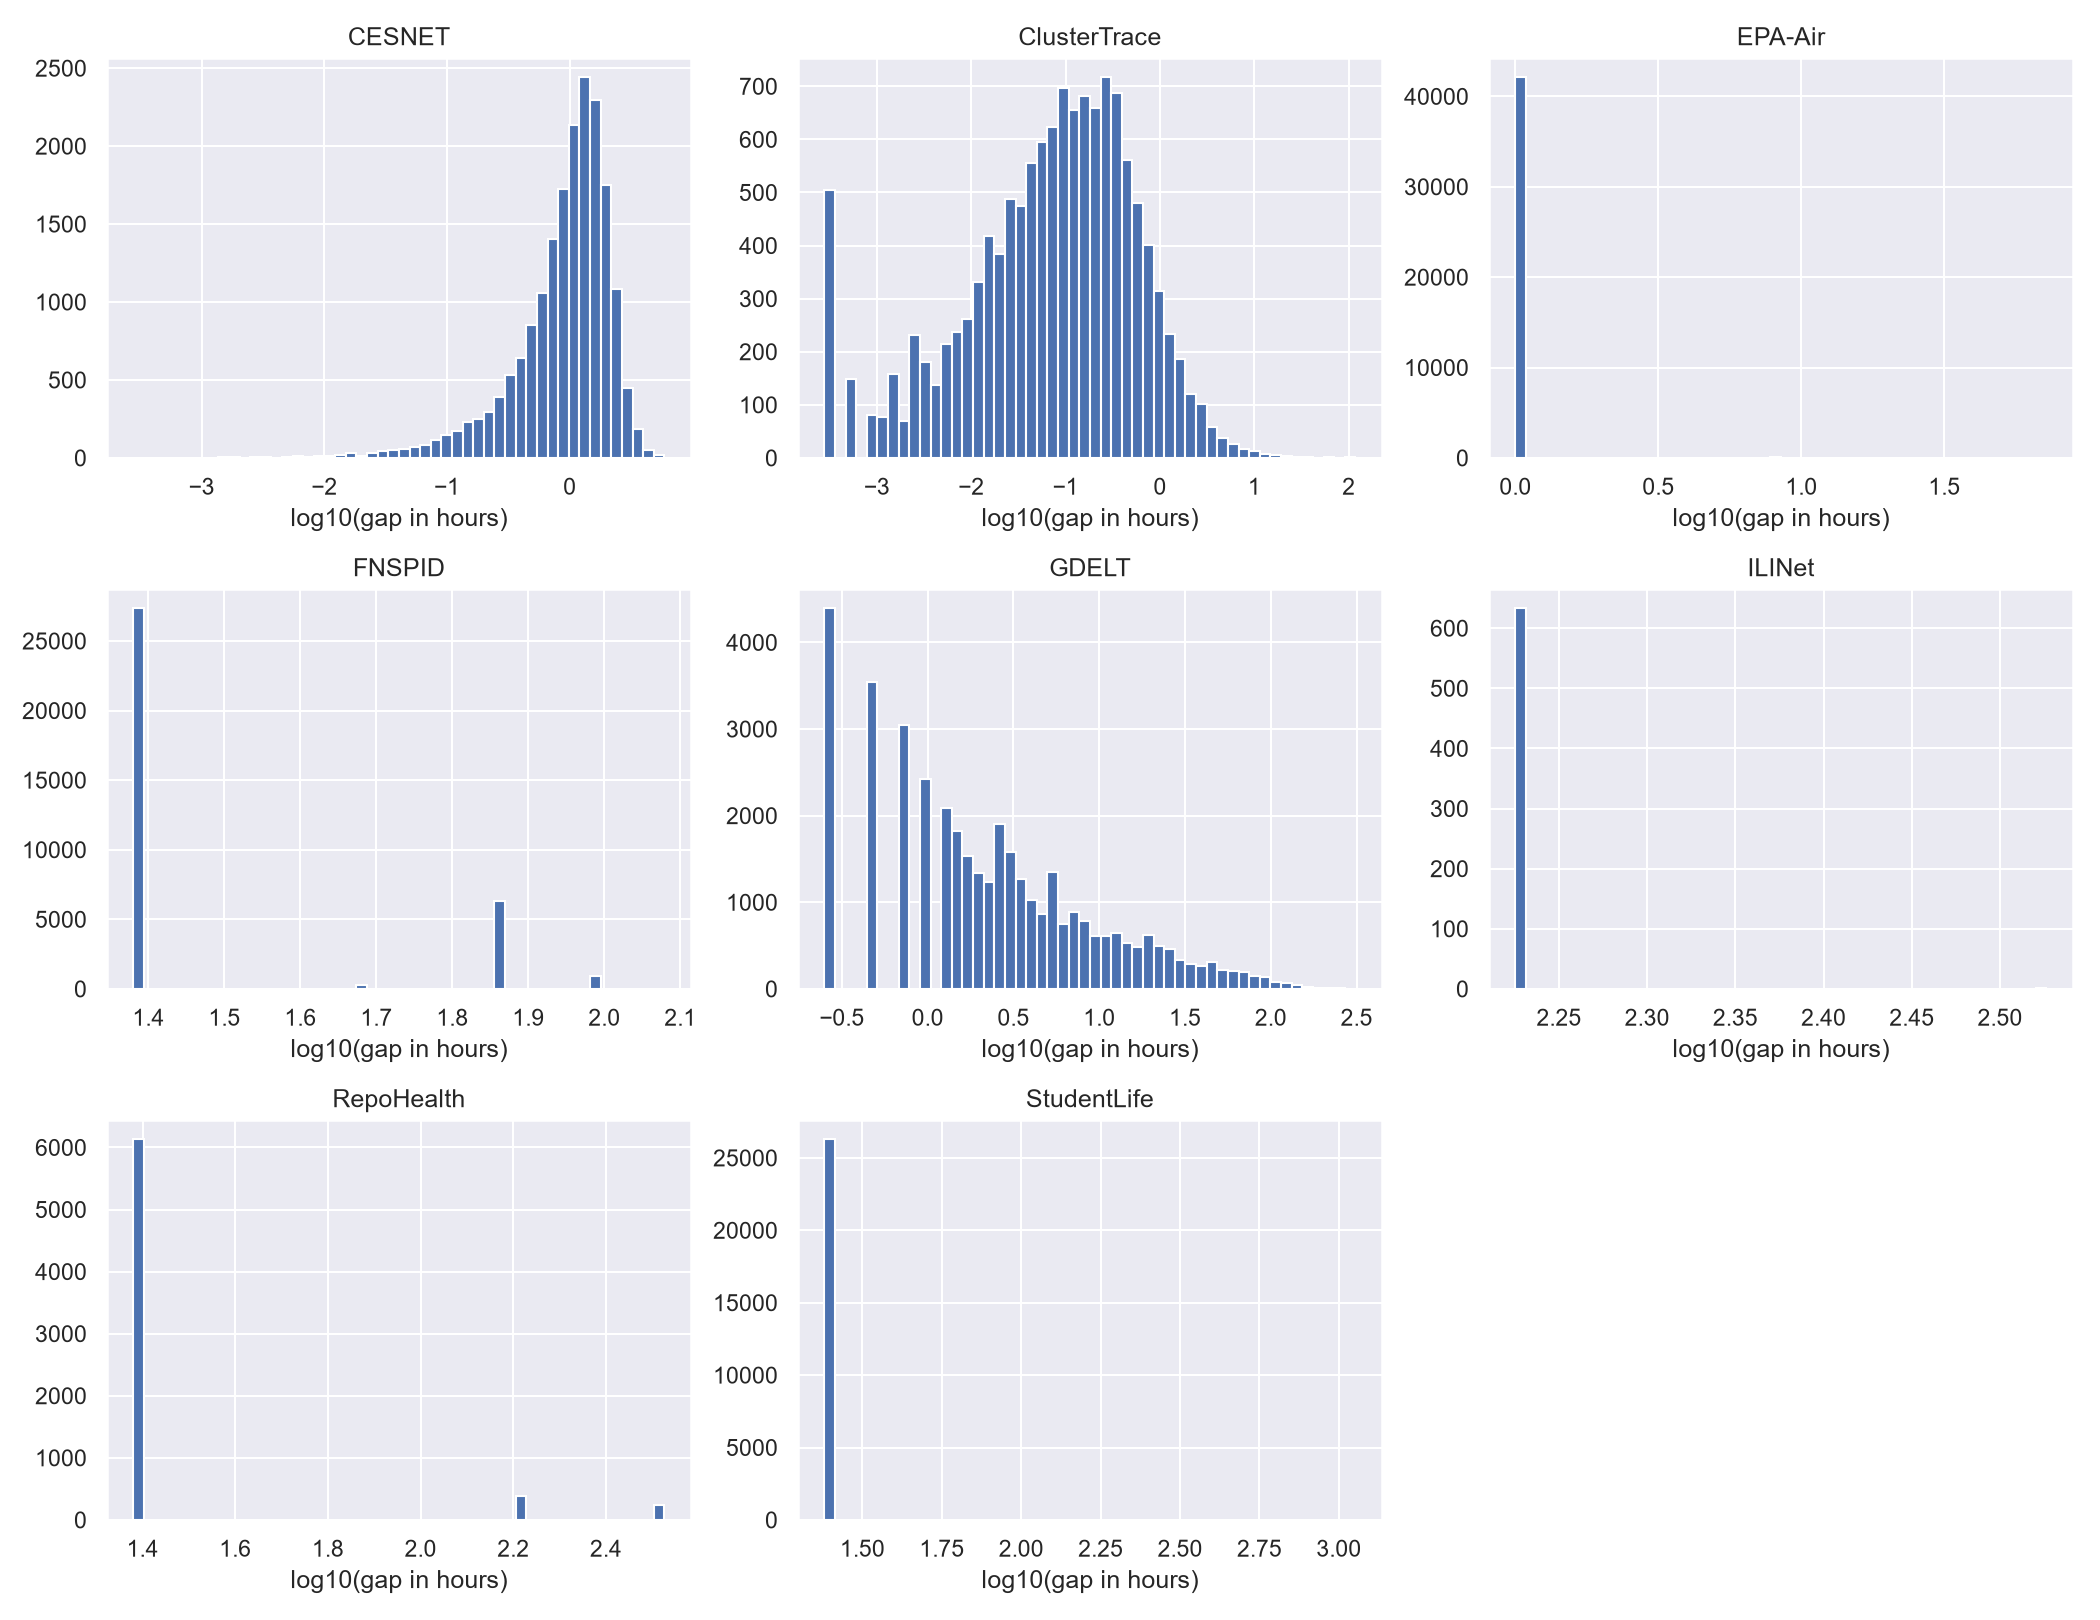

In [4]:
EDA_OUT = Path("eda_outputs")
if not EDA_OUT.exists():
    print("eda_outputs/ not found. Run EDA_project_math.py once "
          "(RERUN = True and RUN['EDA_project_math.py'] = True in section 1), then run this cell again.")
else:
    print("Per dataset (summary_per_dataset.csv):")
    display(pd.read_csv(EDA_OUT / "summary_per_dataset.csv", index_col=0))

    p3_file = EDA_OUT / "part3_target_summary.csv"
    if p3_file.exists():
        p3 = pd.read_csv(p3_file)
        cols = [c for c in ["n_observed", "target_missing_pct", "skew", "outlier_share", "adf_p_level", "adf_p_change",
                            "share_gaps_without_text", "texts_per_gap"] if c in p3.columns]
        print("\nThe target, median over entities (part3_target_summary.csv):")
        display(p3.groupby("Dataset")[cols].median().round(3).T)
        print("Share of entities with a stationary target (ADF p < 0.05):")
        display(pd.DataFrame({"on the values": (p3["adf_p_level"] < 0.05).groupby(p3["Dataset"]).mean(),
                              "on the changes": (p3["adf_p_change"] < 0.05).groupby(p3["Dataset"]).mean()}).round(2))

    for name in ["fig_gap_histograms.png"]:
        if (EDA_OUT / name).exists():
            print(name)
            display(Image(filename=str(EDA_OUT / name), width=800))


**What the EDA script shows**

* **Size.** EPA-Air looks large, but 87.5% of its target (`pm2_5`) is empty, so about 640 real measurements per city remain. ClusterTrace has 3 machines; only 1 is kept after cleaning.
* **Stationarity.** The target level of EPA-Air and GDELT does not trend, so "predict the average" is a fair baseline. Stock prices (dropped) drift, so they would need the daily change.
* **Text coverage.** 85% of the gaps between EPA-Air measurements and 61% of the GDELT gaps contain no new text, so for most predictions the model has nothing new to read.
* **Words.** GDELT: workers, union, farmers, labor. EPA-Air: weather, conditions, heat, storm. "weather" was removed in cleaning because it was the search word used to select those articles. Regular vs bursty series and missing data are covered in 3.1 and 3.3.


### 3.1 Data quality and missingness
First the checks on the **cleaned** tables (types, duplicates, missing cells). Then the part that explains the cleaning:
the **missingness heatmaps are drawn from the raw Time-IMM files, before any cleaning**. Left: share of missing values per column and entity. Right: the same for the first entity over time (share per month).
This is why the cleaning step creates a `<column>_missing_hours` mask: a value that was missing and later filled forward must not look like a real measurement.

,duplicated_rows,duplicated_entity_and_time,target_missing,other_cells_missing,missingness_mask_columns
dataset,,,,,
RepoHealth,0,0,0,0,0
EPA-Air,0,0,0,0,1
GDELT,0,0,0,0,0
ClusterTrace,0,0,0,0,10
StudentLife,0,0,0,0,7



Column types of RepoHealth:
<class 'pandas.DataFrame'>
RangeIndex: 6783 entries, 0 to 6782
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype              
---  ------                  --------------  -----              
 0   date_time               6783 non-null   datetime64[us, UTC]
 1   entity_id               6783 non-null   str                
 2   target                  6783 non-null   float64            
 3   split                   6783 non-null   str                
 4   open_issues             6783 non-null   int64              
 5   closed_issues           6783 non-null   int64              
 6   avg_age_open_issues_hr  6783 non-null   float64            
 7   issue_comment_volume    6783 non-null   int64              
 8   open_prs                6783 non-null   int64              
 9   new_prs                 6783 non-null   int64              
 10  merged_prs              6783 non-null   int64              
 11  avg_age_open_prs_hr     6

,count,mean,std,min,25%,50%,75%,max
target,6783.0,2.575135,0.832221,0.0,2.079442,2.639057,3.135494,6.086775
open_issues,6783.0,2220.159664,3593.511323,-3008.0,-106.500000,612.000000,4041.500000,10666.000000
closed_issues,6783.0,15.995725,20.045204,0.0,6.000000,11.000000,19.000000,389.000000
avg_age_open_issues_hr,6783.0,12954.459947,7845.181411,0.0,7019.697479,11926.735691,18113.961549,33382.645231
issue_comment_volume,6783.0,436.354710,638.127238,0.0,86.000000,239.000000,549.500000,9015.000000
open_prs,6783.0,17765.278638,23038.103497,-5.0,2265.000000,6474.000000,22695.500000,87735.000000
new_prs,6783.0,29.276869,25.864738,0.0,10.000000,23.000000,42.000000,310.000000
merged_prs,6783.0,11.938818,17.526849,0.0,0.000000,5.000000,17.000000,182.000000
avg_age_open_prs_hr,6783.0,14688.153614,9998.266885,0.0,6777.474954,13375.702326,19274.340096,45438.621539
pr_comment_volume,6783.0,100.087277,116.654430,0.0,28.000000,74.000000,135.000000,1964.000000


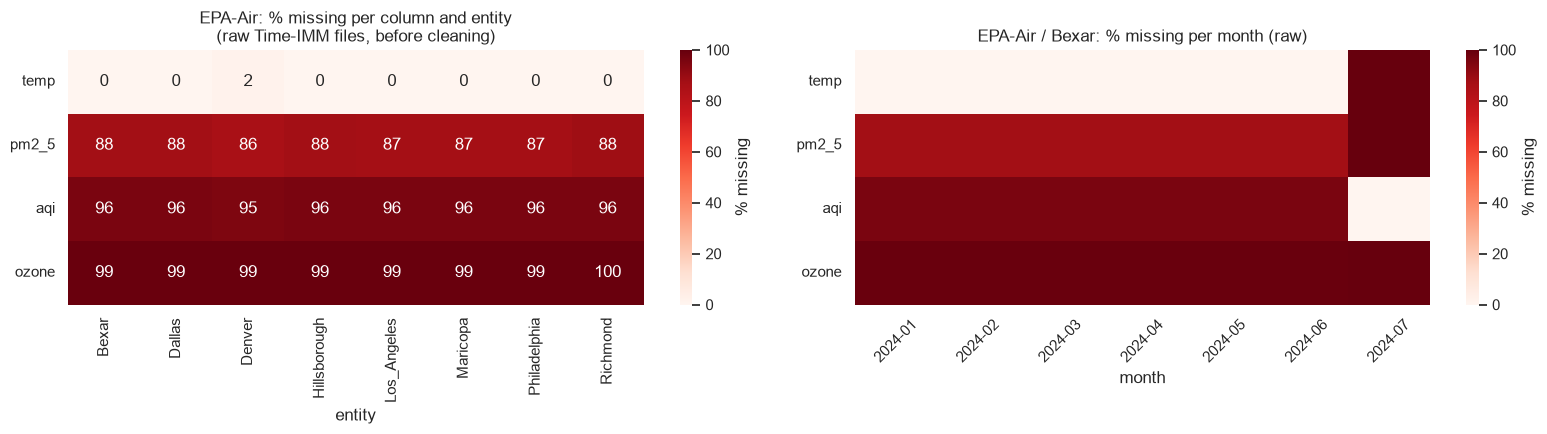

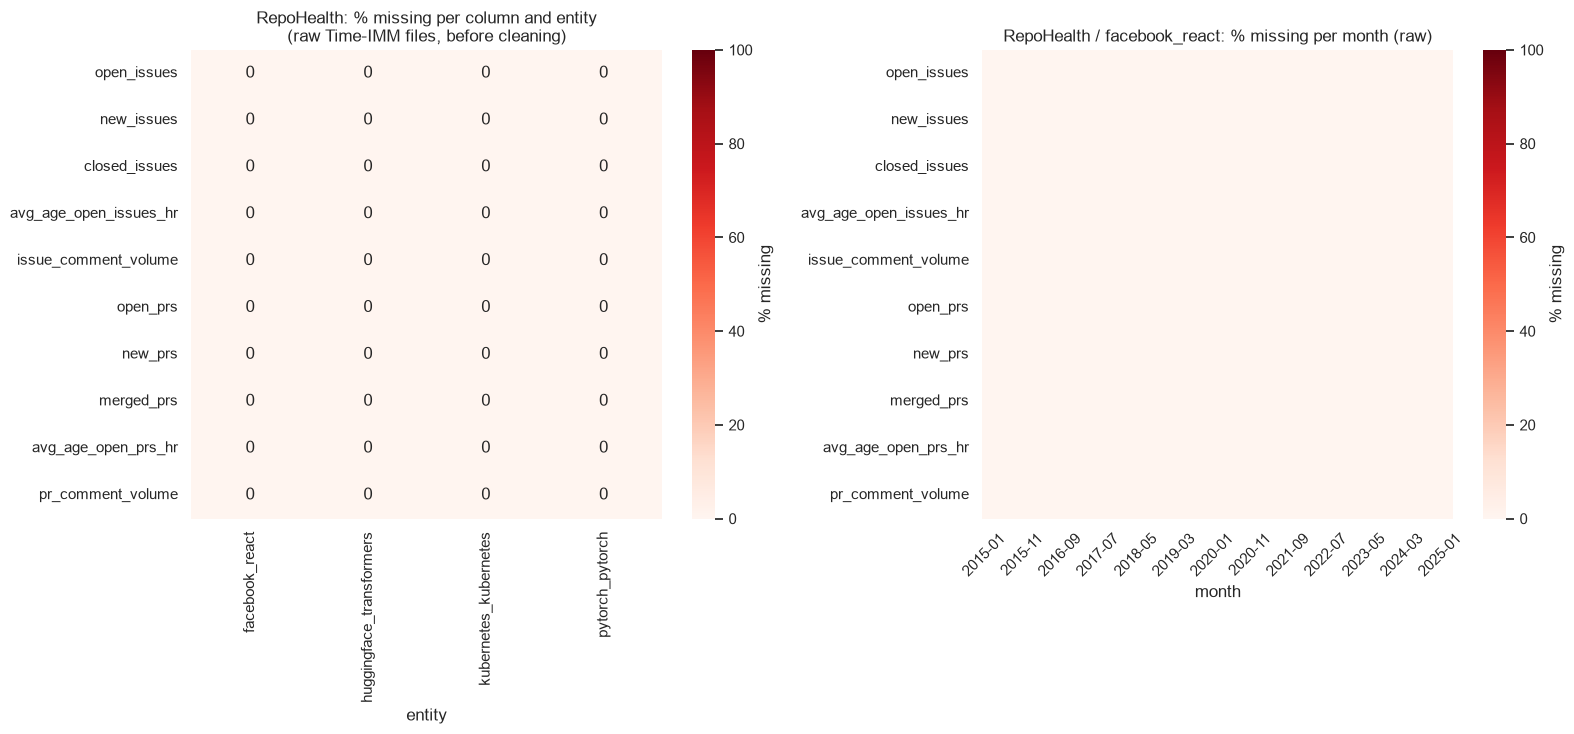

In [6]:
rows = []
for ds, d in num.items():
    rows.append(dict(dataset=ds,
                     duplicated_rows=int(d.duplicated().sum()),
                     duplicated_entity_and_time=int(d.duplicated(["entity_id", "date_time"]).sum()),
                     target_missing=int(d["target"].isna().sum()),
                     other_cells_missing=int(d.isna().sum().sum()),
                     missingness_mask_columns=sum(c.endswith("_missing_hours") for c in d.columns)))
display(pd.DataFrame(rows).set_index("dataset"))
first_ds = "RepoHealth" if "RepoHealth" in num else next(iter(num))
print(f"\nColumn types of {first_ds}:")
num[first_ds].info()
display(num[first_ds].describe().T.head(15))


def _time_col(d):
    for c in d.columns:
        if any(k in c.lower() for k in ("date", "time", "stamp")):
            return c
    return None


def raw_missing(ds):
    per_entity, first = {}, None
    for f in sorted((RAW / ds).rglob("time_series.csv")):
        d = pd.read_csv(f).drop(columns=["record_id"], errors="ignore")
        tcol = _time_col(d)
        per_entity[f.parent.name] = d.drop(columns=[tcol] if tcol else []).isna().mean()
        if first is None and tcol is not None:
            d[tcol] = pd.to_datetime(d[tcol], errors="coerce", utc=True)
            first = (f.parent.name, d.dropna(subset=[tcol]).set_index(tcol).sort_index().drop(columns=[]))
    return pd.DataFrame(per_entity), first


def mask_missing(ds):
    d = num[ds]
    mc = [c for c in d.columns if c.endswith("_missing_hours")]
    share = d.assign(**{c: d[c] > 0 for c in mc}).groupby("entity_id")[mc].mean().T
    share.index = [c.replace("_missing_hours", "") for c in share.index]
    share.columns = [short(c) for c in share.columns]
    return share


for ds in ["EPA-Air", "RepoHealth"]:
    if ds not in num:
        continue
    share, first = (raw_missing(ds) if (RAW / ds).exists() else (pd.DataFrame(), None))
    source = "raw Time-IMM files, before cleaning"
    if share.empty:
        share, first = mask_missing(ds), None
        source = "missingness masks of the cleaned file (the raw folder time_imm/ was not found)"
    share = share.loc[share.max(axis=1) > 0] if (share.max(axis=1) > 0).any() else share
    ncols = 2 if first is not None else 1
    fig, axes = plt.subplots(1, ncols, figsize=(8 * ncols, max(4.5, 0.5 * len(share) + 2.5)), squeeze=False)
    sns.heatmap(share * 100, ax=axes[0, 0], cmap="Reds", vmin=0, vmax=100, annot=share.size <= 120, fmt=".0f",
                cbar_kws={"label": "% missing"})
    axes[0, 0].set_title(f"{ds}: % missing per column and entity\n({source})")
    axes[0, 0].set_xlabel("entity")
    plt.setp(axes[0, 0].get_yticklabels(), rotation=0)
    if first is not None:
        miss = first[1].isna().resample("MS").mean()
        miss = miss.loc[:, miss.max() > 0] if (miss.max() > 0).any() else miss
        sns.heatmap(miss.T * 100, ax=axes[0, 1], cmap="Reds", vmin=0, vmax=100,
                    xticklabels=max(1, len(miss) // 12), cbar_kws={"label": "% missing"})
        axes[0, 1].set_xticklabels([t.strftime("%Y-%m") for t in miss.index[::max(1, len(miss) // 12)]], rotation=45)
        axes[0, 1].set_title(f"{ds} / {first[0]}: % missing per month (raw)")
        axes[0, 1].set_xlabel("month")
        plt.setp(axes[0, 1].get_yticklabels(), rotation=0)
    fig.tight_layout()
    plt.show()

**How to read it:** dark red = most values missing; **grey = that column does not exist for that entity**

**What the heatmaps show.** In the raw EPA-Air files, `temp` is complete (0% missing; 2% for Denver), but the target `pm2_5` is 86–88% empty in every one of the 8 entities, `aqi` is 95–96% empty and `ozone` 99–100% empty. The picture over time (Bexar) shows the same share in every month, so the gaps are a permanent feature of the data and not a short outage. In the last month shown (July 2024) the pattern changes (temp and pm2_5 fully missing, aqi complete); I did not look into why. RepoHealth is the opposite: 0% missing in every column, every entity and every month.

**What the cleaning does about it:** see section 4 (the target is never filled, empty columns are dropped, other columns are forward-filled with a `_missing_hours` mask). EPA-Air shrinks from 42,306 raw rows to 5,309 cleaned rows (12.5%).


### 3.2 The target: distribution and the target over time
Top: histogram and boxplot of the target as it is modelled (counts use `log1p`). Bottom: the target over time for the **first entity** of RepoHealth and GDELT, coloured by the time-ordered split
(blue = train, orange = validation, red = test). **Outliers are kept on purpose**: in event-driven series an outlier is often the real signal.

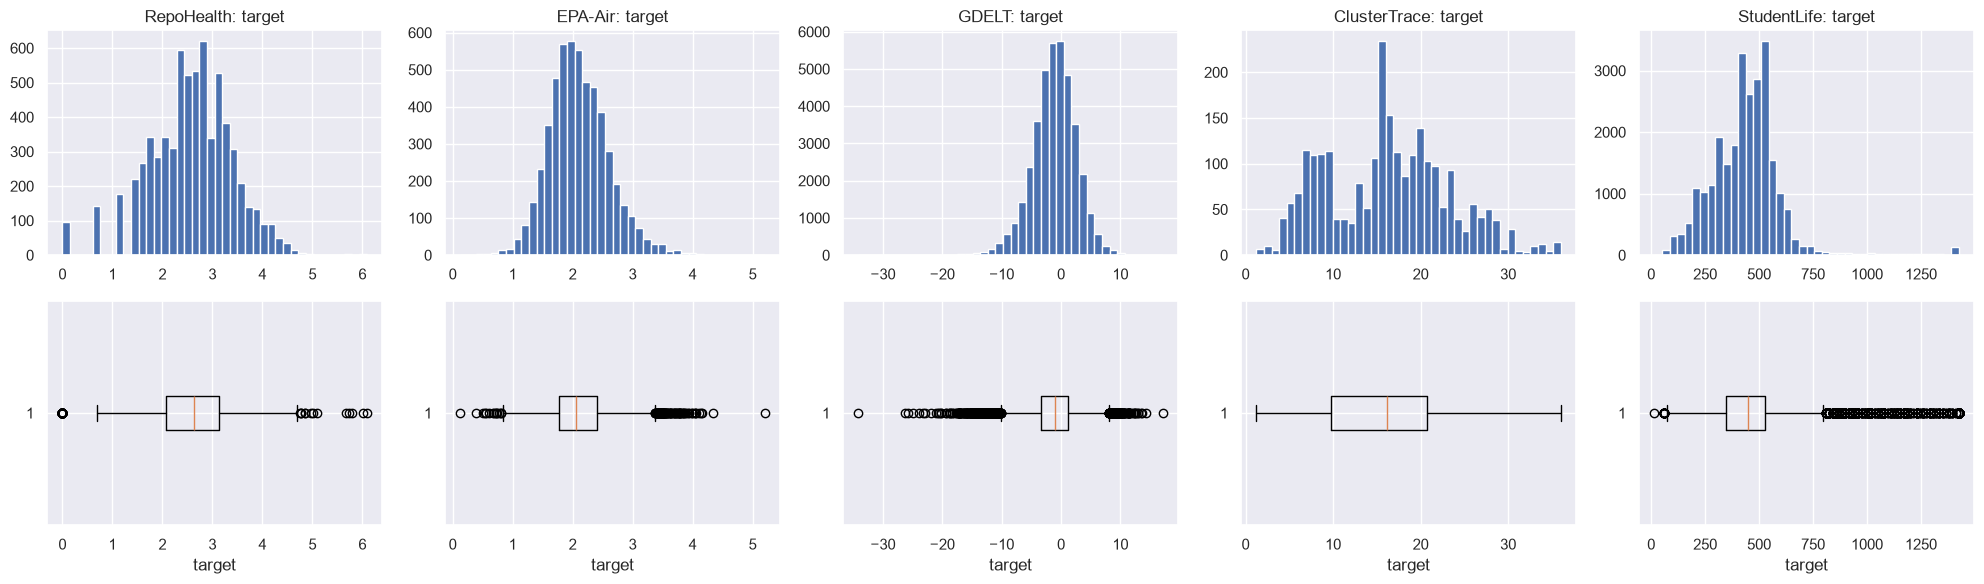

,count,mean,std,min,25%,50%,75%,max
RepoHealth,6783.0,2.575135,0.832221,0.000000,2.079442,2.639057,3.135494,6.086775
EPA-Air,5309.0,2.105100,0.500863,0.128833,1.768961,2.062912,2.407621,5.202678
GDELT,38641.0,-1.157253,3.687906,-34.146341,-3.333333,-0.997151,1.236749,17.142857
ClusterTrace,2506.0,16.268304,7.001228,1.237955,9.766096,16.145040,20.773888,36.008137
StudentLife,26392.0,437.593513,163.403812,15.000000,345.000000,450.000000,525.000000,1425.000000


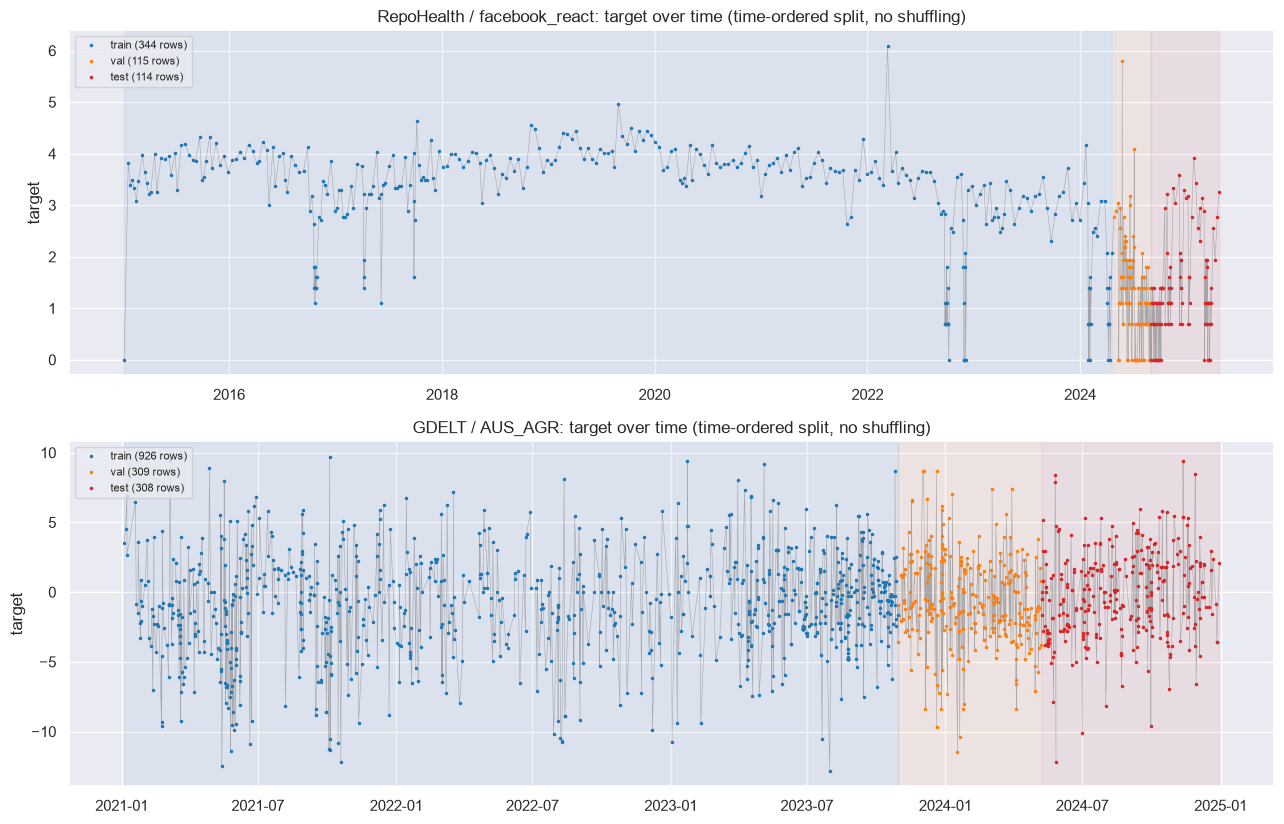

In [7]:
fig, axes = plt.subplots(2, len(num), figsize=(4 * len(num), 6), squeeze=False)
for j, (ds, d) in enumerate(num.items()):
    axes[0, j].hist(d["target"], bins=40)
    axes[0, j].set_title(f"{ds}: target")
    axes[1, j].boxplot(d["target"], vert=False)
    axes[1, j].set_xlabel("target")
fig.tight_layout()
plt.show()
display(pd.DataFrame({ds: d["target"].describe() for ds, d in num.items()}).T)

show = [ds for ds in ["RepoHealth", "GDELT"] if ds in num]
fig, axes = plt.subplots(len(show), 1, figsize=(13, 4.2 * len(show)), squeeze=False)
for ax, ds in zip(axes.ravel(), show):
    d = num[ds]
    ent = d["entity_id"].iloc[0]
    e = d[d["entity_id"] == ent].sort_values("date_time")
    ax.plot(e["date_time"], e["target"], color="gray", lw=0.4, alpha=0.6)
    for s, col in SPLIT_COLORS.items():
        part = e[e["split"] == s]
        if len(part):
            ax.axvspan(part["date_time"].min(), part["date_time"].max(), color=col, alpha=0.07)
            ax.plot(part["date_time"], part["target"], ".", ms=3, color=col, label=f"{s} ({len(part)} rows)")
    ax.set_title(f"{ds} / {short(ent)}: target over time (time-ordered split, no shuffling)")
    ax.set_ylabel("target")
    ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

### 3.3 Irregularity (the point of Time-IMM)
Gap = hours between two consecutive observations of the same entity. A regular series has CV (std / mean of the gap) close to 0; a bursty one has CV above 1.

,median_gap_h,mean_gap_h,CV,p90_gap_h,share_gaps_over_5x_median
dataset,,,,,
RepoHealth,24.000,43.720,1.512,24.000,0.094
EPA-Air,8.000,8.094,0.567,8.000,0.000
GDELT,2.000,7.236,2.287,18.250,0.160
ClusterTrace,0.027,0.456,7.887,0.693,0.263
StudentLife,24.000,24.482,0.521,24.000,0.001


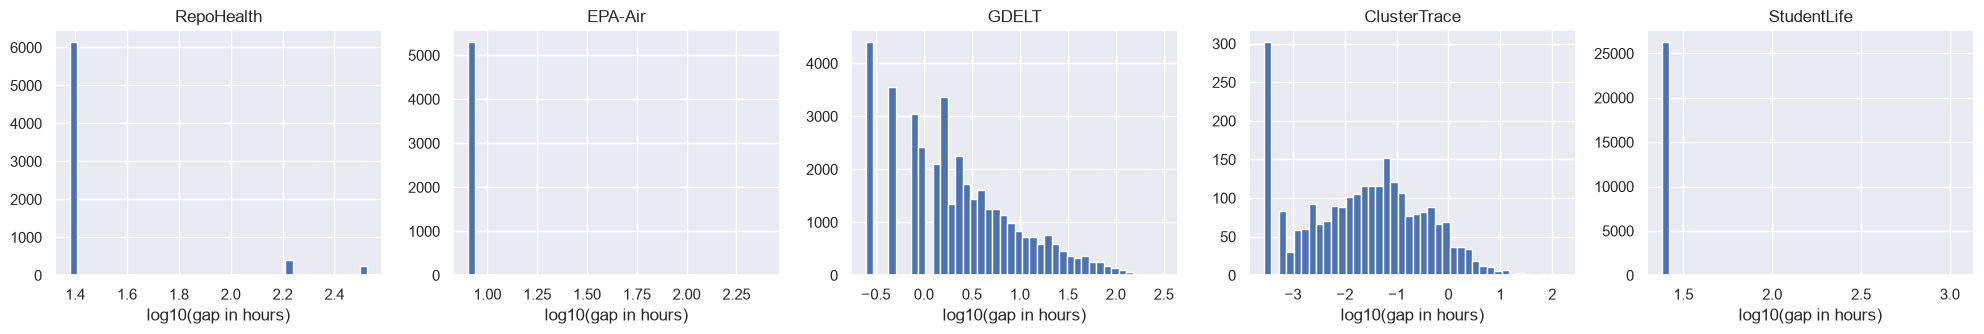

In [9]:
def gap_hours(d):
    d = d.sort_values(["entity_id", "date_time"])
    return d.groupby("entity_id")["date_time"].diff().dt.total_seconds().div(3600).dropna()

gaps = {ds: gap_hours(d) for ds, d in num.items()}
rows = []
for ds, g in gaps.items():
    med = g.median()
    rows.append(dict(dataset=ds, median_gap_h=med, mean_gap_h=g.mean(), CV=g.std() / g.mean(),
                     p90_gap_h=g.quantile(0.9), share_gaps_over_5x_median=(g > 5 * med).mean() if med > 0 else np.nan))
gap_table = pd.DataFrame(rows).set_index("dataset")
display(gap_table.round(3))

fig, axes = plt.subplots(1, len(gaps), figsize=(4 * len(gaps), 3.5), squeeze=False)
for ax, (ds, g) in zip(axes.ravel(), gaps.items()):
    ax.hist(np.log10(g[g > 0]), bins=40)
    ax.set_title(ds)
    ax.set_xlabel("log10(gap in hours)")
fig.tight_layout()
plt.show()

**What the table shows** (cleaned data, gaps in hours):

| Dataset | Median gap | CV | Gaps > 5x median | Cause of irregularity in Time-IMM (paper, section 2.1) |
|---|---|---|---|---|
| RepoHealth | 24 | 1.51 | 9.4% | trigger-based (adaptive / reactive sampling) |
| GDELT | 2 | 2.29 | 16% | trigger-based (event-based logging) |
| ClusterTrace | 0.027 (about 1.6 min) | 7.89 | 26% | constraint-based (resource-aware collection) |
| StudentLife | 24 | 0.52 | 0.1% | constraint-based (human scheduling / availability) |
| EPA-Air | 8 | 0.57 | 0% | artifact-based (multi-source asynchrony) |

* **Bursty:** ClusterTrace (CV 7.9) is by far the most irregular, then GDELT (2.3) and RepoHealth (1.5); a CV above 1 means the gaps vary more than their average. **Regular:** StudentLife is almost a fixed daily rhythm, and EPA-Air is a fixed 8-hour grid in the cleaned data (the raw data is hourly; the grid appears because only rows with a measured `pm2_5` are kept, section 3.1).
* **Link to the three causes.** Both trigger-based datasets are bursty, but the constraint-based ones differ a lot (ClusterTrace 7.9, StudentLife 0.5), so the cause alone does not predict how irregular a series looks. EPA-Air (artifact-based) looks regular after cleaning because of what the cleaning keeps.
* The irregularity labels are those of the Time-IMM paper (arXiv 2506.10412, section 2.1).


### 3.4 Correlation of the numeric features with the target
Correlation matrix (levels, all entities pooled) of the target and the 14 numeric columns most correlated with it, for each main dataset. This is a first look only: two series that both drift will correlate without one explaining the other.

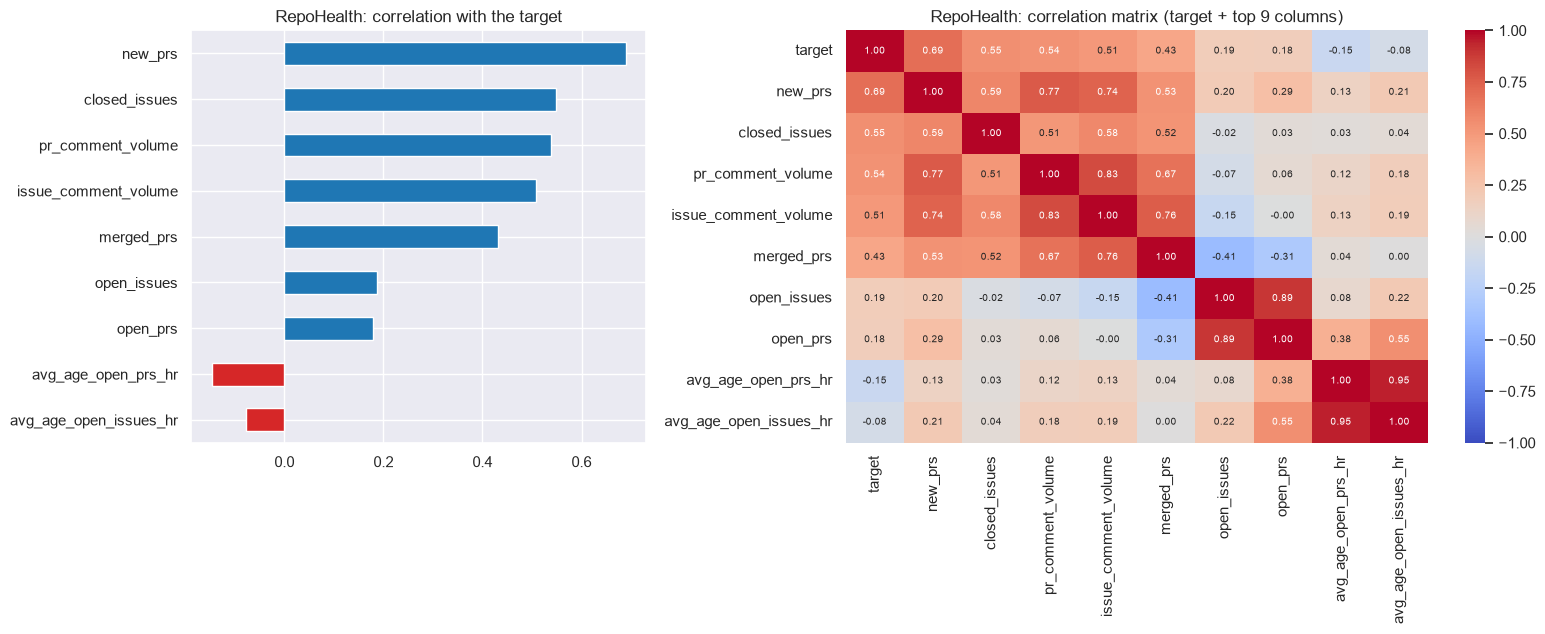

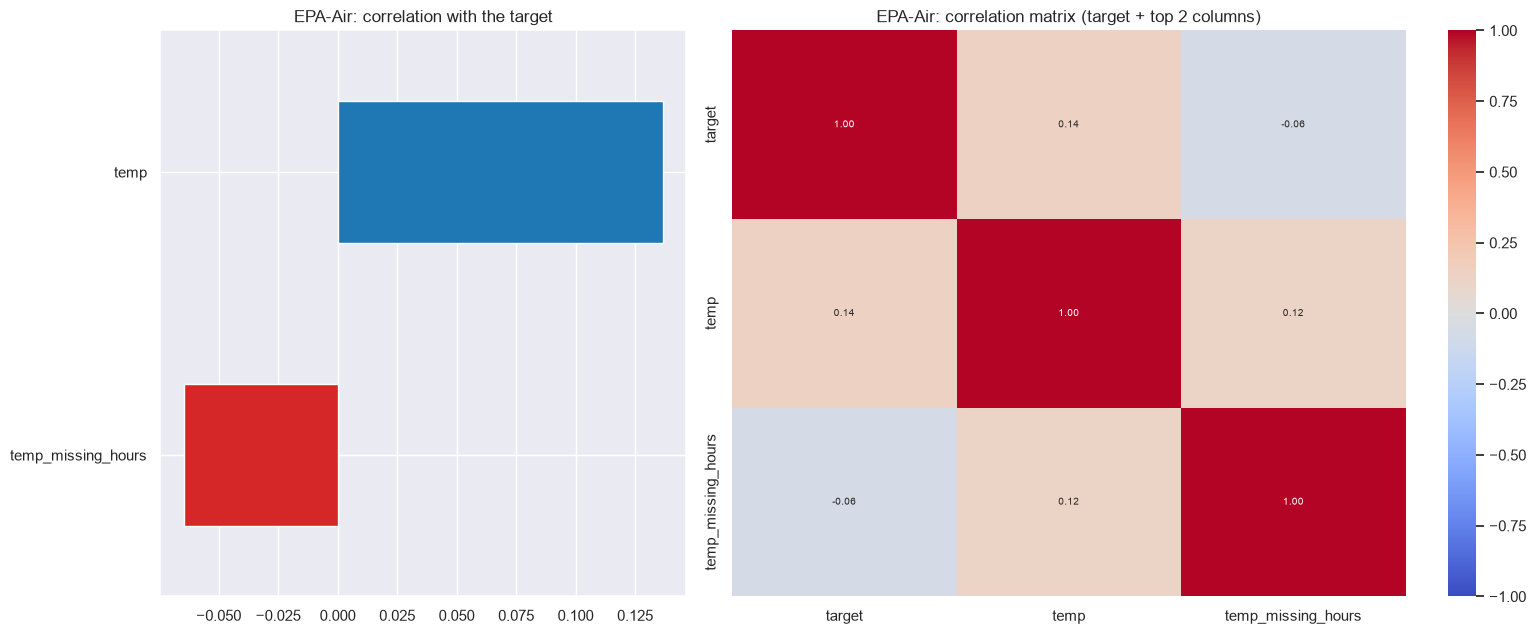

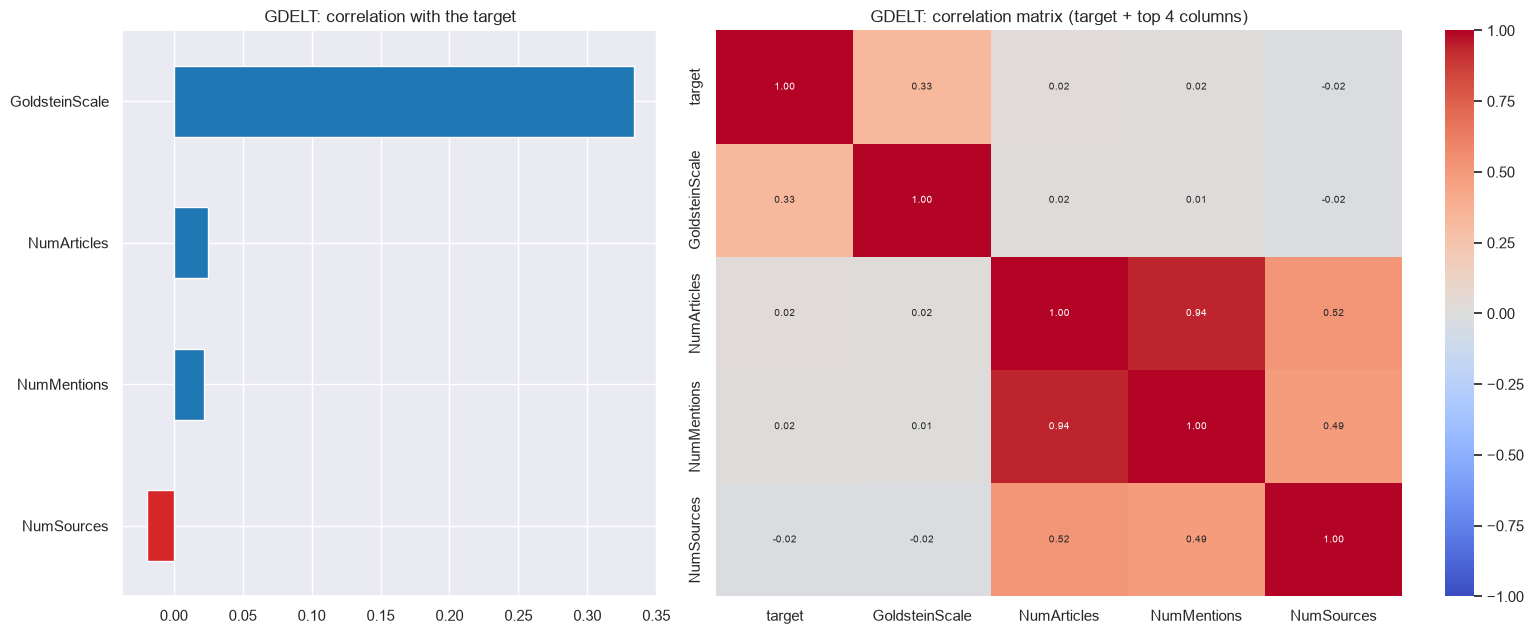

In [10]:
def corr_heatmap(ds, top=14):
    d = num[ds].drop(columns=["entity_id", "split", "date_time"]).select_dtypes("number")
    d = d.loc[:, d.std() > 0]
    c = d.corr()["target"].drop("target").dropna()
    if c.empty:
        print(f"{ds}: no other numeric columns to correlate")
        return
    order = list(c.abs().sort_values(ascending=False).index[:top])
    sel = ["target"] + order
    fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.6]})
    c[order][::-1].plot.barh(ax=axes[0], color=["tab:red" if v < 0 else "tab:blue" for v in c[order][::-1]])
    axes[0].set_title(f"{ds}: correlation with the target")
    sns.heatmap(d[sel].corr(), annot=len(sel) <= 16, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
                annot_kws={"size": 7}, ax=axes[1])
    axes[1].set_title(f"{ds}: correlation matrix (target + top {len(order)} columns)")
    fig.tight_layout()
    plt.show()

for ds in MAIN:
    if ds in num:
        corr_heatmap(ds)

**What the correlation plots show.** Correlations are for the same time step, all entities pooled, and only describe the data (at forecast time today's values are not known).
* **RepoHealth:** the target (`new_issues`, log) is most related to `new_prs` (0.69), `closed_issues` (0.55) and the comment volumes (0.51-0.54); days with many new issues are busy days. Several columns are near copies of each other (for example `open_issues` and `open_prs` 0.89), which is no problem for tree models, Ridge or Lasso but splits feature importance between "twins".
* **EPA-Air:** only `temp` is left as a numeric column and its correlation with `pm2_5` is small (0.14), so the forecast must rely on the target's own history (section 13).
* **GDELT:** only `GoldsteinScale` is related to `AvgTone` (0.33); the count columns are near 0.
* These are straight-line relations only; a weak correlation does not prove that a column is useless for tree models.


### 3.5 The texts
Size of the text collections, the number of texts per entity (bar chart for RepoHealth and GDELT), and a few examples.

,texts,entities_with_text,median_words,p90_words,texts_per_numeric_row
dataset,,,,,
RepoHealth,12310,4,136.0,158.0,1.815
EPA-Air,1243,8,98.0,122.0,0.234
GDELT,14328,8,109.0,128.0,0.371
ClusterTrace,688,3,97.0,109.0,0.275
StudentLife,6623,20,137.0,142.0,0.251


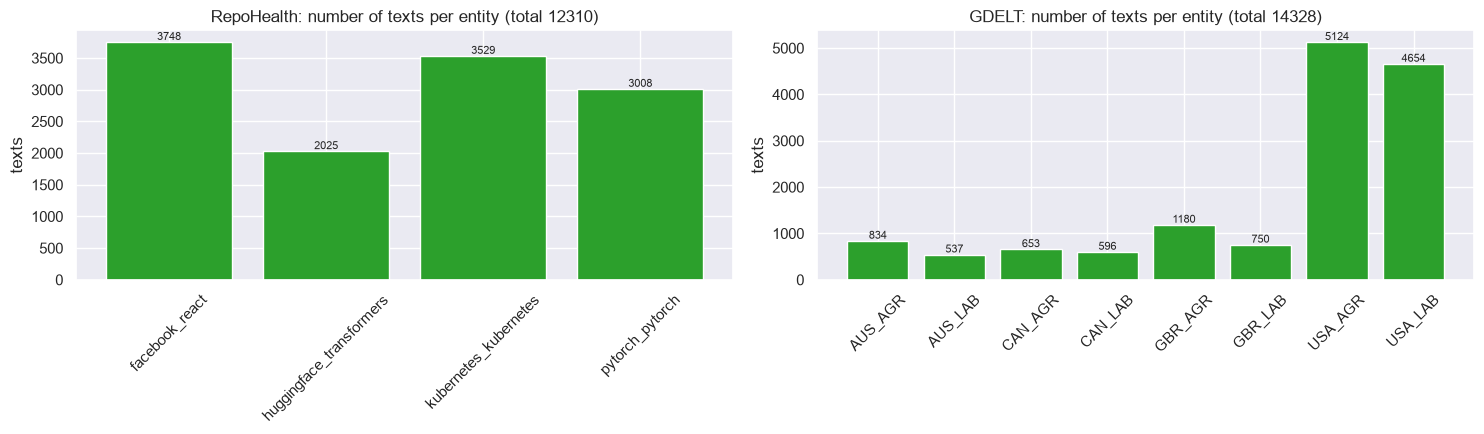


RepoHealth: 3 random examples
  - The discussions highlight several technical issues and questions: the need for clearer documentation and tutorials for training and fine-tuning transformer models, especially for complex tasks like qu
  - The comments highlight ongoing challenges with certain Kubernetes features and APIs, such as the need for better handling of secrets, configmaps, and rolling restarts, with suggestions for tools like 
  - The discussions primarily focus on ensuring backward-compatibility and seamless integration of new features, such as broadcasting and in-place operations, while minimizing disruption to existing code.

EPA-Air: 3 random examples
  - The article highlights several cities' climate resilience and natural disaster risks, with FEMA data indicating Spokane and South Bend both rank highly for low risk and high resilience to extreme weat
  - The article mentions a weather delay at Kansas Speedway that postponed the start of the NASCAR race, as officials wor

In [12]:
rows = []
for ds, t in txt.items():
    words = t["text_raw"].astype(str).str.split().str.len()
    rows.append(dict(dataset=ds, texts=len(t), entities_with_text=t["entity_id"].nunique(),
                     median_words=words.median(), p90_words=words.quantile(0.9),
                     texts_per_numeric_row=len(t) / len(num[ds]) if ds in num else np.nan))
display(pd.DataFrame(rows).set_index("dataset").round(3))

show = [ds for ds in ["RepoHealth", "GDELT"] if ds in txt]
if show:
    fig, axes = plt.subplots(1, len(show), figsize=(7.5 * len(show), 4.5), squeeze=False)
    for ax, ds in zip(axes.ravel(), show):
        cnt = txt[ds]["entity_id"].value_counts().sort_index()
        ax.bar([short(e) for e in cnt.index], cnt.values, color="tab:green")
        for i, v in enumerate(cnt.values):
            ax.text(i, v, str(v), ha="center", va="bottom", fontsize=8)
        ax.set_title(f"{ds}: number of texts per entity (total {len(txt[ds])})")
        ax.set_ylabel("texts")
        ax.tick_params(axis="x", rotation=45)
    fig.tight_layout()
    plt.show()

for ds, t in txt.items():
    print(f"\n{ds}: 3 random examples")
    for s in t["text_raw"].astype(str).sample(min(3, len(t)), random_state=0):
        print("  -", s[:200].replace("\n", " "))

## 4. Data cleaning
What `clean_data.py` does, and why:

* **Target:** never filled. A row without a real target is dropped (a filled target would be an invented answer).
* **Other columns:** forward-fill only (uses the past, never the future); what is still empty is set to 0, and the `<column>_missing_hours` mask says "this value is not real".
  *Why not median / mode filling?* The median of a time series contains future values and hides that a value was missing. Backward fill or centred interpolation would also use the future.
* **Columns that are more than 95% empty** are dropped; entities with fewer than 100 usable rows are skipped.
* **Outliers are kept** (real events); the log transform tames them.
* **No scaling here.** Scalers are fitted on the training part inside the models, so nothing from validation or test leaks in.
* **Time-ordered split inside every entity: 60% train, 20% validation, 20% test.** No shuffling.
* Texts: lower-case, URLs / numbers / punctuation removed, stop words removed (negations such as "not" are kept), plus domain stop words (for example "weather" in EPA-Air, the search word used to select those articles).

Entities where train / val / test are NOT in time order (must be 0):
{'RepoHealth': 0, 'EPA-Air': 0, 'GDELT': 0, 'ClusterTrace': 0, 'StudentLife': 0}


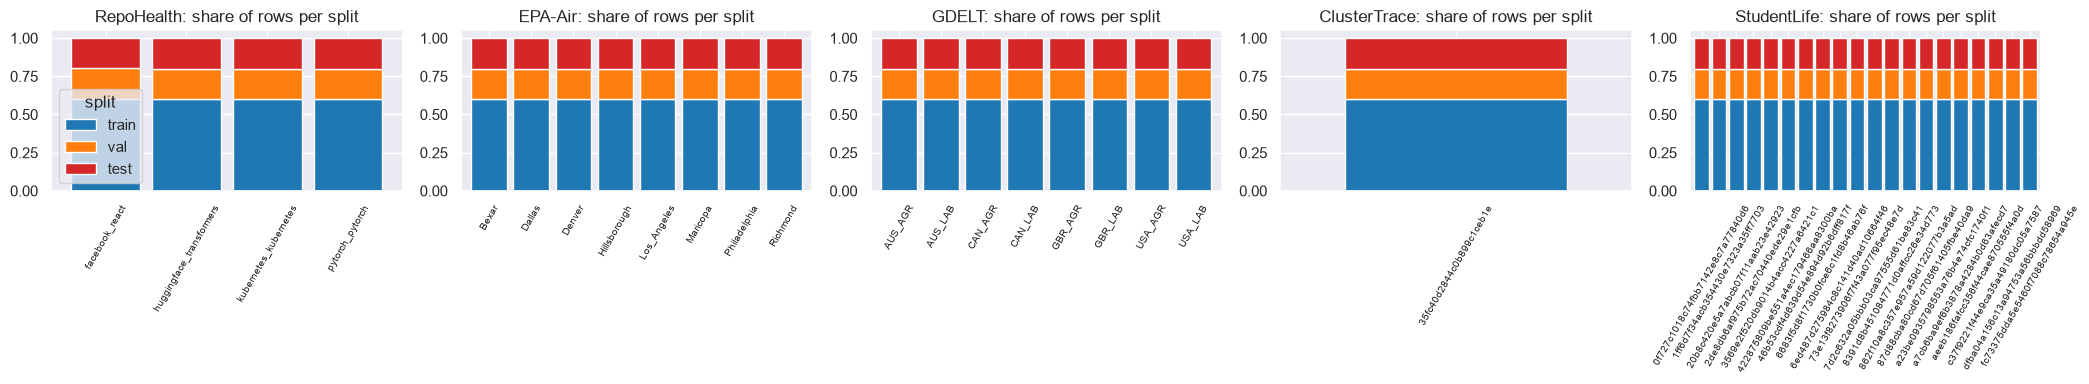

In [15]:
def split_order_problems(d):
    bad = 0
    for _, g in d.groupby("entity_id"):
        a = g.groupby("split")["date_time"].agg(["min", "max"])
        if {"train", "val", "test"} <= set(a.index):
            if not (a.loc["train", "max"] <= a.loc["val", "min"] and a.loc["val", "max"] <= a.loc["test", "min"]):
                bad += 1
    return bad

print("Entities where train / val / test are NOT in time order (must be 0):")
print({ds: split_order_problems(d) for ds, d in num.items()})

fig, axes = plt.subplots(1, len(num), figsize=(4.2 * len(num), 4), squeeze=False)
for ax, (ds, d) in zip(axes.ravel(), num.items()):
    sh = d.groupby("entity_id")["split"].value_counts(normalize=True).unstack().reindex(columns=["train", "val", "test"])
    sh.index = [short(i) for i in sh.index]
    sh.plot.bar(stacked=True, ax=ax, color=[SPLIT_COLORS[c] for c in sh.columns], legend=ds == list(num)[0], width=0.85)
    ax.set_title(f"{ds}: share of rows per split")
    ax.tick_params(axis="x", rotation=60, labelsize=7)
fig.tight_layout()
plt.show()

## 5. Feature matrix and target

**The forecasting task.** A *forecast origin* is the last observation I know (time `t_j`). The *target* is a later observation (time `t_i`).
Every feature must be known **at the origin**. Two settings are used:

* **Next observation** (`horizon_hours=None`): used for the numeric-only comparison (sections 8–13).
* **Longer horizons** (used for the text experiments, because on a long horizon the last value says less and text has more room to help); the horizon of each dataset is in the table below.

**Two different tasks, so their numbers cannot be compared.**

| | Task A: next observation | Task B: long horizon |
|---|---|---|
| Used in | sections 8-13 | section 14 and the text conclusions |
| Forecast origin | the previous row | the last row at least *H* hours before the target (21 to 115 observations earlier) |
| Question it answers | how good are the numeric models? | does text help when the last value says less? |
| Horizon | none | ClusterTrace 12 h, EPA-Air 7 days, GDELT 14 days, RepoHealth and StudentLife 31 days |

*How the horizons were set:* one fixed value per dataset (`runs` in `text_features.py`), long enough to span 21 to 115 observations (`steps_ahead` in the DM test), so "repeat the last value" is no longer almost perfect. The tasks must not be mixed: RepoHealth has a test MAE of 0.379 for the next observation but 0.568 for the 31-day forecasts of section 14.

**Is `lag_1` a leak?** No. `lag_1` is the value at the origin, the last number I already know. The target is a *later* row that the model never sees.
The model gets no information from the future, only the past and the *time* of the value to be predicted (`lead_h`, calendar), because in Time-IMM the query time is given.
`ts_common.make_features` builds the features row by row, and the check below asserts that the origin is always before the target.

In [16]:
show_code("ts_common.py", r"def make_features", r"def grouped_time_cv", "- ALL features are built here, from the origin row only")

**ts_common.py`, lines 25-84**  - ALL features are built here, from the origin row only

```python
def make_features(df, horizon_hours=None):
    df = df.copy()
    df["date_time"] = pd.to_datetime(df["date_time"], utc=True)
    df = df.sort_values(["entity_id", "date_time"]).reset_index(drop=True)
    n = len(df)
    g = df.groupby("entity_id")
    y = df["target"].to_numpy()
    t_ns = df["date_time"].dt.tz_convert(None).to_numpy().astype("datetime64[ns]")

    O = pd.DataFrame(index=df.index)
    for k in lags:
        O[f"lag_{k}"] = g["target"].shift(k - 1)
    for w in row_windows:
        O[f"mean_{w}"] = g["target"].transform(lambda s, w=w: s.rolling(w).mean())
        O[f"std_{w}"] = g["target"].transform(lambda s, w=w: s.rolling(w).std())
    
    for win in time_windows:
        m, s, c = (np.full(n, np.nan) for _ in range(3))
        for idx in g.indices.values():
            roll = pd.Series(y[idx], index=pd.DatetimeIndex(t_ns[idx])).rolling(win)
            m[idx], s[idx], c[idx] = roll.mean().to_numpy(), roll.std().to_numpy(), roll.count().to_numpy()
        O[f"tmean_{win}"], O[f"tstd_{win}"], O[f"tcount_{win}"] = m, np.nan_to_num(s), c
        
    O["gap_prev_h"] = g["date_time"].diff().dt.total_seconds() / 3600
    for c in [c for c in df.columns if c not in ("date_time", "entity_id", "target", "split")]:
        v = df[c]
        if c in log_cols or c.endswith("_missing_hours"):
            v = np.log1p(v.clip(lower=0))
        O[f"{c}_lag1"] = v

    src = np.full(n, -1)
    delta = None if horizon_hours is None else np.timedelta64(int(round(horizon_hours * 3600)), "s")
    for idx in g.indices.values():
        if delta is None:
            src[idx[1:]] = idx[:-1]
        else:
            k = np.searchsorted(t_ns[idx], t_ns[idx] - delta, side="right")
            ok = k >= 1
            src[idx[ok]] = idx[k[ok] - 1]
            
    rows = np.where(src >= 0)[0]
    origin = src[rows]

    F = O.iloc[origin].reset_index(drop=True)
    F.index = rows
    if use_query_time:
        F["lead_h"] = (t_ns[rows] - t_ns[origin]) / np.timedelta64(1, "h")
        tt = df["date_time"].iloc[rows]
        for name, value, period in (("hour", tt.dt.hour, 24), ("weekday", tt.dt.dayofweek, 7),
                                    ("month", tt.dt.month - 1, 12), ("doy", tt.dt.dayofyear - 1, 366)):
            F[f"{name}_sin"] = np.sin(2 * np.pi * value / period)
            F[f"{name}_cos"] = np.cos(2 * np.pi * value / period)
            
    F.columns = [re.sub(r"[^0-9a-zA-Z_]", "_", c) for c in F.columns]

    meta = df.loc[rows, ["entity_id", "date_time", "target", "split"]].copy()
    meta["t_cut"] = df["date_time"].iloc[origin].to_numpy()
    keep = F.notna().all(axis=1)
    data = pd.concat([meta, F], axis=1)[keep]
    return data.reset_index(drop=True), list(F.columns)
```

In [17]:
DEMO = "RepoHealth" if "RepoHealth" in num else next(iter(num))
data, cols = make_features(num[DEMO].copy())
origin_before_target = bool((pd.to_datetime(data["t_cut"], utc=True) < pd.to_datetime(data["date_time"], utc=True)).all())
print(f"{DEMO}: {len(data)} forecast rows, {len(cols)} features")
print("origin is always strictly before the target:", origin_before_target)

groups = {
    "lags of the target (lag_k)": r"^lag_\d+$",
    "rolling mean/std over the last rows": r"^(mean|std)_\d+$",
    "rolling mean/std/count over the last days": r"^t(mean|std|count)_",
    "time since the previous observation": r"^gap_prev_h$",
    "query time (lead time, calendar of the target)": r"^(lead_h|(hour|weekday|month|doy)_(sin|cos))$",
    "other columns at the origin": r"_lag1$",
}
rows = []
for name, pat in groups.items():
    members = [c for c in cols if re.search(pat, c)]
    rows.append(dict(group=name, n=len(members), examples=", ".join(members[:5])))
display(pd.DataFrame(rows).set_index("group"))
display(data[["entity_id", "t_cut", "date_time", "target", "lag_1", "lag_2", "mean_5", "lead_h"]].head())

tr = data[data["split"] == "train"]
print("\nCorrelation inside the training part:")
print(tr[["target", "lag_1", "mean_20"]].corr().round(3))

RepoHealth: 6703 forecast rows, 34 features
origin is always strictly before the target: True


,n,examples
group,,
lags of the target (lag_k),5,"lag_1, lag_2, lag_3, lag_5, lag_7"
rolling mean/std over the last rows,4,"mean_5, std_5, mean_20, std_20"
rolling mean/std/count over the last days,6,"tmean_1D, tstd_1D, tcount_1D, tmean_7D, tstd_7D"
time since the previous observation,1,gap_prev_h
"query time (lead time, calendar of the target)",9,"lead_h, hour_sin, hour_cos, weekday_sin, weekd..."
other columns at the origin,9,"open_issues_lag1, closed_issues_lag1, avg_age_..."


,entity_id,t_cut,date_time,target,lag_1,lag_2,mean_5,lead_h
0,RepoHealth/facebook_react,2015-07-06 17:05:26+00:00,2015-07-20 17:05:26+00:00,4.158883,3.295837,4.007333,3.745951,336.0
1,RepoHealth/facebook_react,2015-07-20 17:05:26+00:00,2015-08-03 17:05:26+00:00,4.189655,4.158883,3.295837,3.799363,336.0
2,RepoHealth/facebook_react,2015-08-03 17:05:26+00:00,2015-08-17 17:05:26+00:00,3.970292,4.189655,4.158883,3.847045,336.0
3,RepoHealth/facebook_react,2015-08-17 17:05:26+00:00,2015-08-31 17:05:26+00:00,3.871201,3.970292,4.189655,3.924400,336.0
4,RepoHealth/facebook_react,2015-08-31 17:05:26+00:00,2015-09-07 17:05:26+00:00,3.850148,3.871201,3.970292,3.897174,168.0



Correlation inside the training part:
         target  lag_1  mean_20
target    1.000  0.589    0.507
lag_1     0.589  1.000    0.563
mean_20   0.507  0.563    1.000


**Delta option (`PREDICT_DELTA`).** The models can learn the *change* `target - lag_1` and add `lag_1` back when predicting. All metrics, baselines and tests stay on the original scale.
Ordinary least squares is not affected by this reparametrisation, so Ridge/Lasso barely move; trees can change.
Final settings: predict_delta=False, lgbm_objective=regression_l1, use_query_time=True, n_splits=8.
I kept predict_delta=False so the model learns the actual target level directly, instead of anchoring its prediction to the last known value (which happens in delta mode).
These settings were chosen using only the validation and cross-validation results. The test set was strictly locked and opened only once at the very end. (I didn't keep a formal count of the variations I tried during development).

## 6. Train / validation / test split
Every entity is cut on its own timeline: **first 60% = train, next 20% = validation, last 20% = test**.

Inside the training part I use **walk-forward cross-validation**: fold *k* trains on everything before a cut and is scored on the chunk right after it
(8 folds, every entity cut at the same share of its own timeline). Validation is used to compare models, and **test is opened only once at the end**.

In [18]:
show_code("clean_data.py", r"    pos = np\.arange\(len\(df\)\)", r"    df\[\"entity_id\"\]", "- the 60/20/20 split inside every entity (in clean_data.py)")


**clean_data.py`, lines 148-151**  - the 60/20/20 split inside every entity (in clean_data.py)

```python
    pos = np.arange(len(df)) / max(len(df), 1)
    df["split"] = np.where(
        pos < 0.6, "train", np.where(pos < 0.8, "val", "test")
    )
```

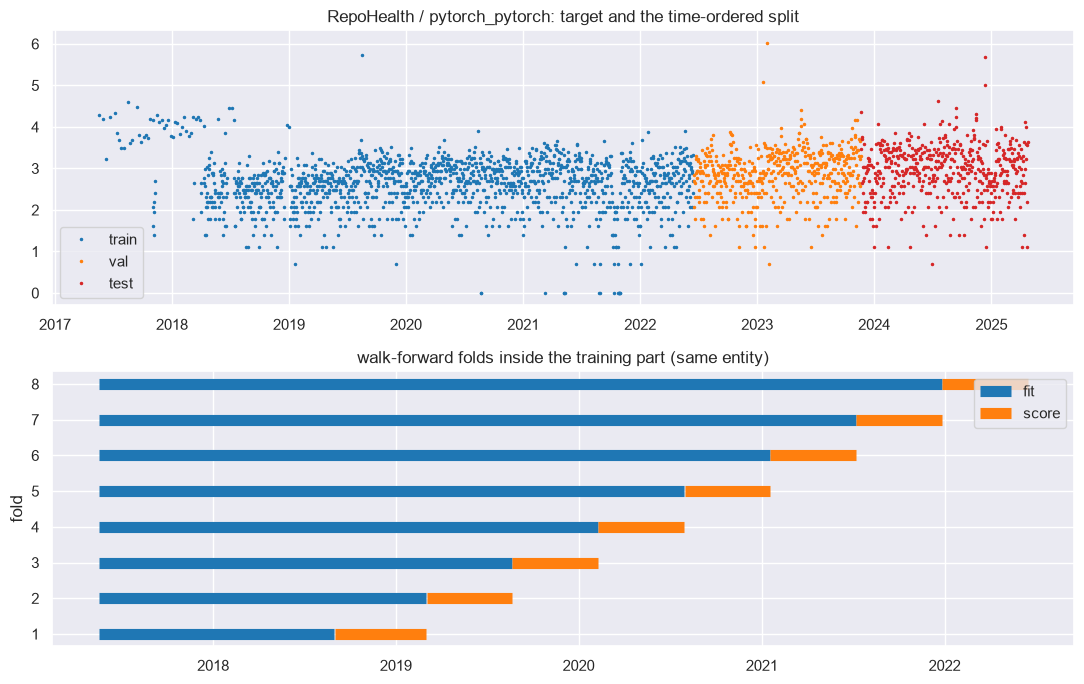

In [19]:
ent = data["entity_id"].value_counts().index[0]
d = data[data["entity_id"] == ent].sort_values("date_time")
train_all = data[data["split"] == "train"].reset_index(drop=True)

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
for s, col in SPLIT_COLORS.items():
    part = d[d["split"] == s]
    axes[0].plot(part["date_time"], part["target"], ".", ms=3, color=col, label=s)
axes[0].set_title(f"{DEMO} / {short(ent)}: target and the time-ordered split")
axes[0].legend()

for k, (a, b) in enumerate(grouped_time_cv(train_all), start=1):
    ta = train_all.iloc[a]; ta = ta[ta["entity_id"] == ent]
    vb = train_all.iloc[b]; vb = vb[vb["entity_id"] == ent]
    if len(ta) and len(vb):
        axes[1].hlines(k, ta["date_time"].min(), ta["date_time"].max(), color="tab:blue", lw=8, label="fit" if k == 1 else None)
        axes[1].hlines(k, vb["date_time"].min(), vb["date_time"].max(), color="tab:orange", lw=8, label="score" if k == 1 else None)
axes[1].set_title("walk-forward folds inside the training part (same entity)")
axes[1].set_ylabel("fold")
axes[1].legend()
fig.tight_layout()
plt.show()

## 7. Preprocessing and models
* **Linear models** (`LinearRegression`, `Ridge`, `Lasso`, `ElasticNet`): the features **and** the target are standardised (fitted on the training rows only), and standardised features are clipped to ±5.
  *Why clip?* If a column hardly varies in an early fold, the scaler divides by a tiny number and a normal value later becomes huge; clipping stops a linear model from predicting nonsense.
* **Tree models** need no scaling. They are **limited on purpose** (`max_depth`, `min_samples_leaf`), because unlimited trees memorise the noise of a time series.
* **Tuning** (only inside the training rows, on *inner* time-ordered folds): `Ridge` over its penalty, `LightGBM` in two stages (random search, then a small grid), scored by MAE.
* **LightGBM** minimises the absolute error (`objective="regression_l1"`) because I report MAE.
* **VotingEnsemble** = the plain average of RandomForest and the same tuned LightGBM.

In [20]:
print({k: type(v).__name__ for k, v in models().items()})

{'LinearRegression': 'TransformedTargetRegressor', 'Ridge': 'TransformedTargetRegressor', 'Lasso': 'TransformedTargetRegressor', 'ElasticNet': 'TransformedTargetRegressor', 'DecisionTree': 'DecisionTreeRegressor', 'RandomForest': 'RandomForestRegressor', 'GradientBoosting': 'GradientBoostingRegressor', 'LightGBM': 'LGBMRegressor', 'VotingEnsemble': 'VotingRegressor'}


In [21]:
pd.DataFrame([
    ("LinearRegression", "yes (+clip)", "none"),
    ("Ridge", "yes (+clip)", "penalty alpha over 6 values"),
    ("Lasso", "yes (+clip)", "fixed alpha=0.01"),
    ("ElasticNet", "yes (+clip)", "fixed alpha=0.01, l1_ratio=0.5"),
    ("DecisionTree", "no", "depth 5, min 20 rows per leaf"),
    ("RandomForest", "no", "100 trees, depth 8, min 20 rows per leaf"),
    ("GradientBoosting", "no", "200 trees, depth 3, learning rate 0.05"),
    ("LightGBM", "no", "random search + local grid, MAE objective"),
    ("VotingEnsemble", "no", "mean of RandomForest and tuned LightGBM"),
], columns=["model", "scaled?", "settings / tuning"]).set_index("model")

,scaled?,settings / tuning
model,,
LinearRegression,yes (+clip),none
Ridge,yes (+clip),penalty alpha over 6 values
Lasso,yes (+clip),fixed alpha=0.01
ElasticNet,yes (+clip),"fixed alpha=0.01, l1_ratio=0.5"
DecisionTree,no,"depth 5, min 20 rows per leaf"
RandomForest,no,"100 trees, depth 8, min 20 rows per leaf"
GradientBoosting,no,"200 trees, depth 3, learning rate 0.05"
LightGBM,no,"random search + local grid, MAE objective"
VotingEnsemble,no,mean of RandomForest and tuned LightGBM


## 8. Regression results (numeric models, validation part)
The models are fitted on the **training part** and scored on the **validation part**. Two baselines sit next to them:
* **baseline: last value** (repeat what I knew at the origin; EPA-Air also has *same time yesterday*),
* **baseline: train mean** (predict the average of the training part). R² is measured **against this baseline**: 0 = as good as the mean, below 0 = worse.

Metrics are computed per entity and then averaged, so a long series does not dominate. The work is done by `evaluate()` in `baseline_models.py`; this section reads the tables it saved
(`results/<dataset>_validation.csv`) and draws them.

datasets with validation tables: ['RepoHealth', 'EPA-Air', 'GDELT', 'ClusterTrace', 'StudentLife']

The function that does the work (straight from baseline_models.py):



**baseline_models.py`, lines 21-43**  

```python
def evaluate(train, ev, cols, ds):
    base = (
        ev["entity_id"].map(train.groupby("entity_id")["target"].mean()).values
    )
    preds = {
        "baseline: train mean": base,
        "baseline: last value": ev["lag_1"].values,
    }
    if ds == "EPA-Air":
        preds["baseline: same time yesterday"] = ev["lag_3"].values
    cache = {}
    for name in models():
        preds[name] = fit_model(
            name,
            train[cols],
            train["target"],
            train["entity_id"],
            cache=cache,
            delta=predict_delta,
        ).predict(ev[cols])
    return pd.DataFrame(
        {name: metrics(ev, p, base)[0] for name, p in preds.items()}
    ).T
```

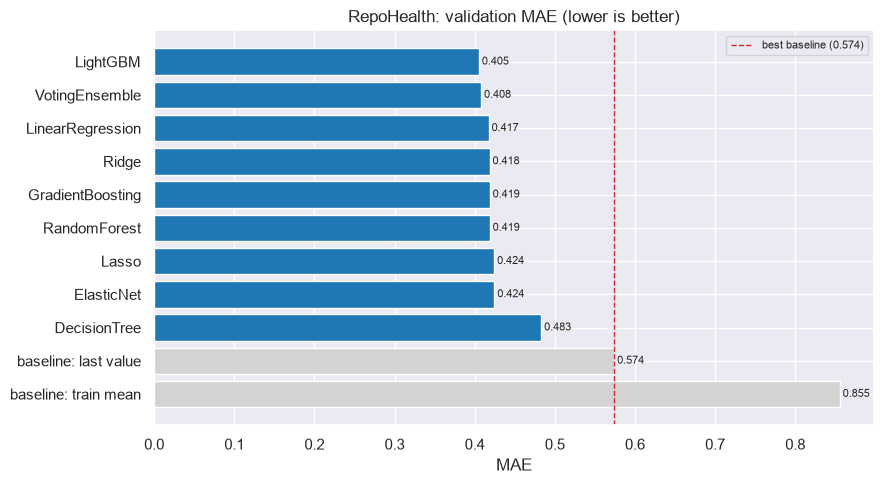

In [23]:
val_tables, cv_tables = {}, {}
for ds in ALL_DS:
    v = read_res(f"{ds}_validation.csv", index_col=0)
    c = read_res(f"{ds}_cv.csv", index_col=0)
    if v is not None:
        val_tables[ds] = v
    if c is not None:
        cv_tables[ds] = c
print("datasets with validation tables:", list(val_tables))

print("\nThe function that does the work (straight from baseline_models.py):\n")
show_function("baseline_models.py", "evaluate")


def mae_bar(ds, ax):
    t = val_tables[ds].sort_values("MAE")
    is_base = t.index.str.startswith("baseline")
    ax.barh(t.index, t["MAE"], color=["lightgray" if b else "tab:blue" for b in is_base])
    for i, v in enumerate(t["MAE"]):
        ax.text(v, i, f" {v:.3f}", va="center", fontsize=8)
    best_base = t.loc[is_base, "MAE"].min()
    ax.axvline(best_base, color="tab:red", ls="--", lw=1, label=f"best baseline ({best_base:.3f})")
    ax.invert_yaxis()
    ax.set_title(f"{ds}: validation MAE (lower is better)")
    ax.set_xlabel("MAE")
    ax.legend(fontsize=8, loc="upper right")

if "RepoHealth" in val_tables:
    fig, ax = plt.subplots(figsize=(9, 5))
    mae_bar("RepoHealth", ax)
    fig.tight_layout()
    plt.show()

Grey bars = baselines, blue bars = models, the red dashed line = the best baseline. A model is only useful if its bar is clearly **left** of the red line.


### Actual vs predicted on the validation part
For each dataset the **best numeric model of the validation table** is refitted on the training part (the same call as in `baseline_models.py`) and predicts the validation rows (next-observation task); predictions are saved in `results/val_predictions.csv`.
*Left:* every dot is one validation row; a perfect model puts all dots on the red diagonal, a flat vertical band means no skill. *Right:* the entity with most validation rows: black = actual, dashed grey = "repeat the last value", blue = the model.


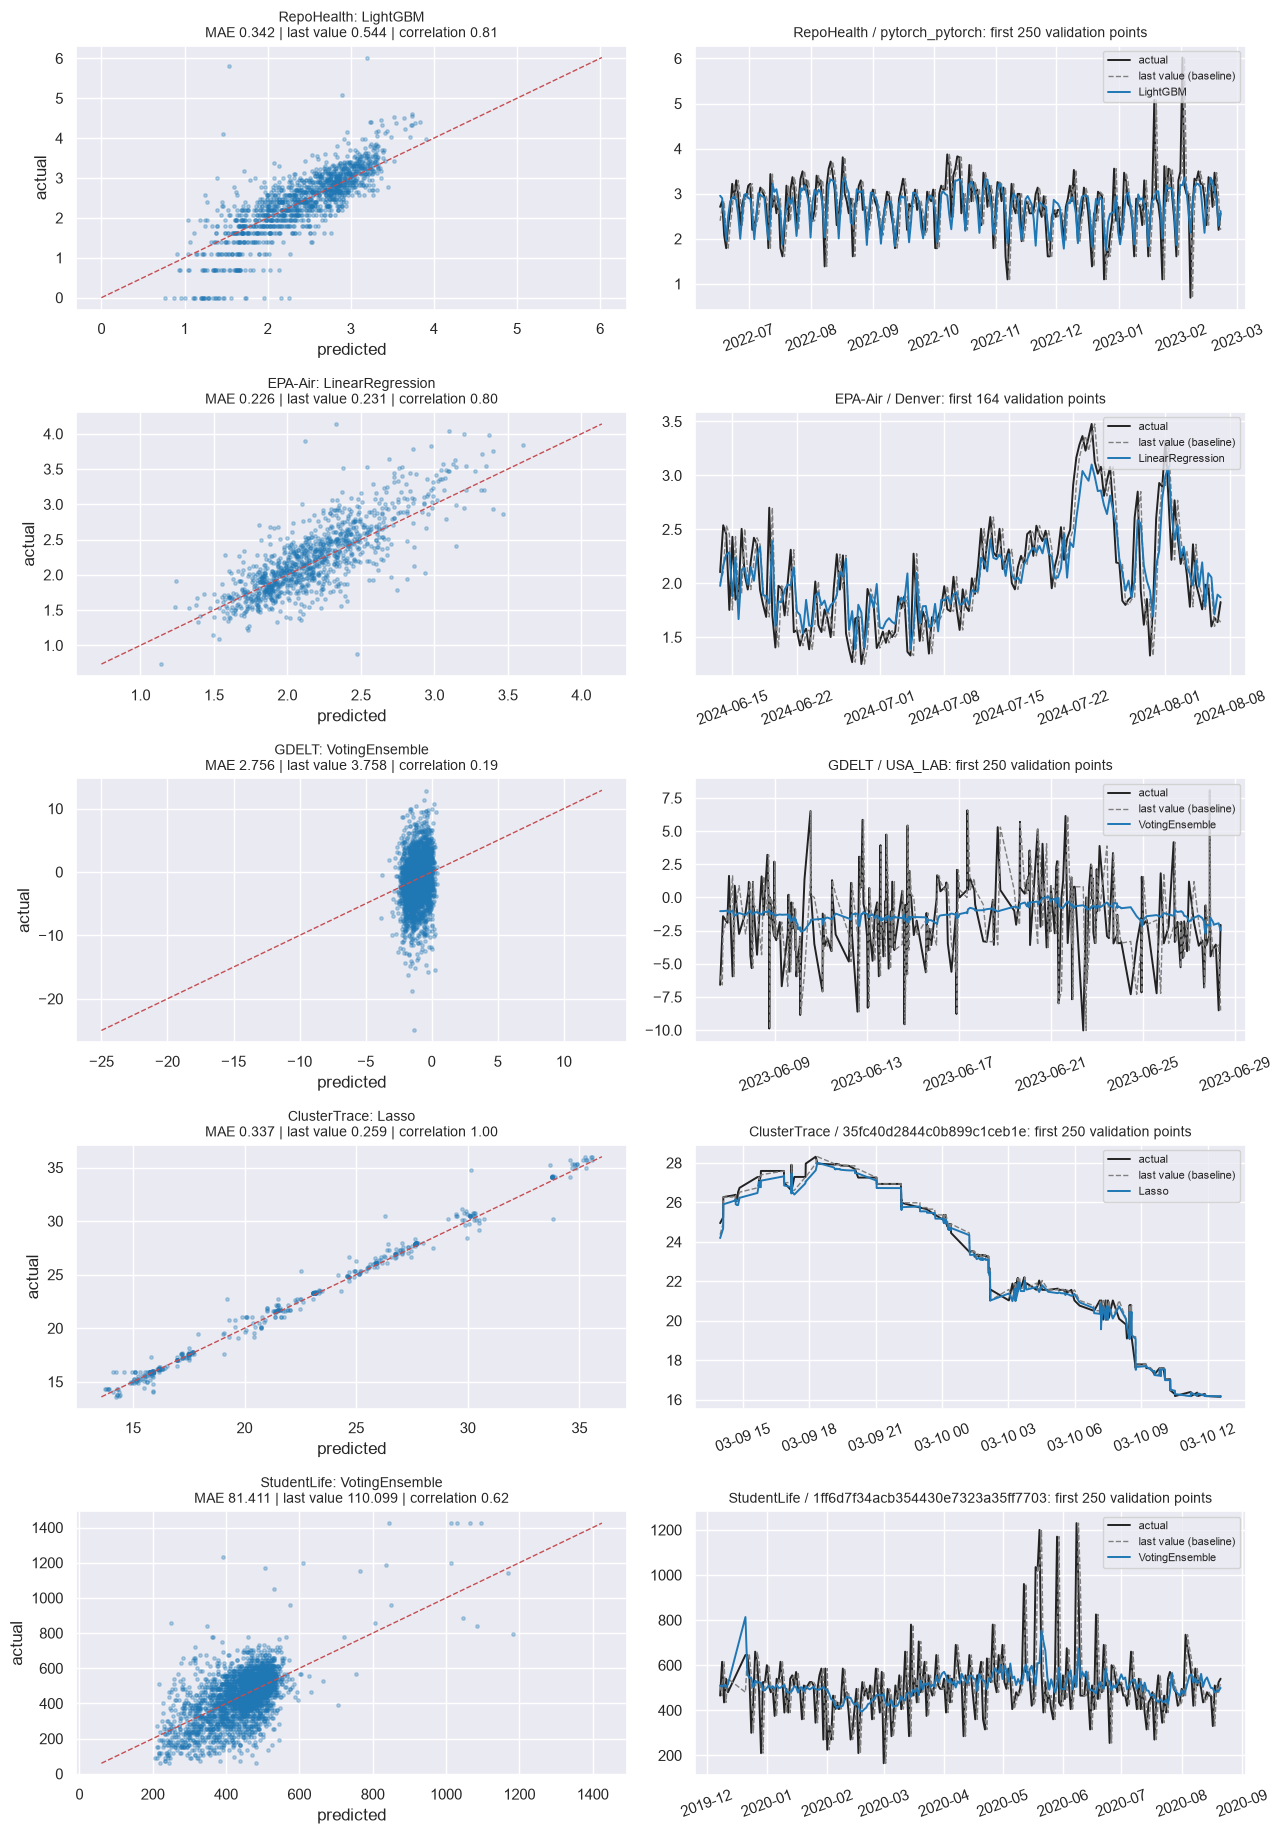

,model,rows,MAE_model,MAE_last_value,correlation
dataset,,,,,
RepoHealth,LightGBM,1358,0.342,0.544,0.814
EPA-Air,LinearRegression,1060,0.226,0.231,0.802
GDELT,VotingEnsemble,7729,2.756,3.758,0.194
ClusterTrace,Lasso,501,0.337,0.259,0.996
StudentLife,VotingEnsemble,5277,81.411,110.099,0.616


In [57]:
VAL_PRED = RES / "val_predictions.csv"
cached = pd.read_csv(VAL_PRED) if VAL_PRED.exists() else pd.DataFrame()
frames = []
for ds in ALL_DS:
    if ds not in val_tables or ds not in num:
        continue
    t = val_tables[ds]
    best = t.loc[~t.index.str.startswith("baseline"), "MAE"].idxmin()
    if len(cached) and ((cached["dataset"] == ds) & (cached["model"] == best)).any():
        frames.append(cached[cached["dataset"] == ds])
        continue
    data, cols = make_features(num[ds].copy())
    tr = data[data["split"] == "train"].reset_index(drop=True)
    va = data[data["split"] == "val"].reset_index(drop=True)
    fitted = fit_model(best, tr[cols], tr["target"], tr["entity_id"], cache={}, delta=predict_delta)
    frames.append(pd.DataFrame({
        "dataset": ds, "model": best, "entity_id": va["entity_id"],
        "date_time": pd.to_datetime(va["date_time"], utc=True),
        "target": va["target"], "pred": fitted.predict(va[cols]), "last_value": va["lag_1"],
    }))
vp = pd.concat(frames, ignore_index=True)
vp.to_csv(VAL_PRED, index=False)
vp["date_time"] = pd.to_datetime(vp["date_time"], utc=True)

BLUE, GREY, DARK = "tab:blue", "tab:gray", "#222222"
fig, axes = plt.subplots(len(frames), 2, figsize=(13, 3.7 * len(frames)), squeeze=False)
summary = []
for (ds, g), (ax_s, ax_t) in zip(vp.groupby("dataset", sort=False), axes):
    y, p, lv = g["target"].to_numpy(), g["pred"].to_numpy(), g["last_value"].to_numpy()
    mae_m, mae_l = np.mean(np.abs(y - p)), np.mean(np.abs(y - lv))
    summary.append(dict(dataset=ds, model=g["model"].iloc[0], rows=len(g), MAE_model=mae_m,
                    MAE_last_value=mae_l, correlation=np.corrcoef(y, p)[0, 1]))
    s = g.sample(min(len(g), 3000), random_state=0)
    lo, hi = min(y.min(), p.min()), max(y.max(), p.max())
    ax_s.scatter(s["pred"], s["target"], s=6, alpha=0.3, color=BLUE)
    ax_s.plot([lo, hi], [lo, hi], "r--", lw=1)
    ax_s.set_xlabel("predicted")
    ax_s.set_ylabel("actual")
    ax_s.set_title(f"{ds}: {g['model'].iloc[0]}\nMAE {mae_m:.3f} | last value {mae_l:.3f} | correlation {summary[-1]['correlation']:.2f}", fontsize=10)
    ent = g["entity_id"].value_counts().index[0]
    e = g[g["entity_id"] == ent].sort_values("date_time").head(250)
    ax_t.plot(e["date_time"], e["target"], color=DARK, lw=1.4, label="actual")
    ax_t.plot(e["date_time"], e["last_value"], color=GREY, lw=1, ls="--", label="last value (baseline)")
    ax_t.plot(e["date_time"], e["pred"], color=BLUE, lw=1.4, label=g["model"].iloc[0])
    ax_t.set_title(f"{ds} / {short(ent)}: first {len(e)} validation points", fontsize=10)
    ax_t.legend(fontsize=8, loc="upper right")
    ax_t.tick_params(axis="x", labelrotation=20)
fig.tight_layout()
plt.show()
display(pd.DataFrame(summary).set_index("dataset").round(3))


## 9. Metrics comparison (all datasets)
MAE is the main metric: it is in the units of the target and not dominated by a few huge errors. RMSE and R² are shown as well.
The table at the bottom compares the best model with the best baseline on each dataset.


RepoHealth  (validation, sorted by MAE; baselines in the same table)


,MAE,MSE,RMSE,R2
LightGBM,0.4052,0.3411,0.5398,0.7138
VotingEnsemble,0.4079,0.3435,0.5437,0.7087
LinearRegression,0.4173,0.3331,0.5493,0.6877
Ridge,0.4185,0.3343,0.5505,0.6863
GradientBoosting,0.4186,0.3721,0.5589,0.6957
RandomForest,0.4187,0.3570,0.5571,0.6932
Lasso,0.4242,0.3425,0.5574,0.6776
ElasticNet,0.4244,0.3419,0.5570,0.6787
DecisionTree,0.4829,0.4608,0.6443,0.5784
baseline: last value,0.5740,0.6611,0.7912,0.2998



EPA-Air  (validation, sorted by MAE; baselines in the same table)


,MAE,MSE,RMSE,R2
LinearRegression,0.2291,0.0953,0.3001,0.6609
Ridge,0.2298,0.0966,0.3019,0.6563
VotingEnsemble,0.2301,0.0978,0.3018,0.6539
LightGBM,0.2306,0.0980,0.3021,0.6532
ElasticNet,0.2317,0.0973,0.3018,0.6554
Lasso,0.2318,0.0975,0.3019,0.6550
RandomForest,0.2321,0.0991,0.3040,0.6493
baseline: last value,0.2328,0.1019,0.3121,0.6330
GradientBoosting,0.2355,0.1041,0.3099,0.6335
DecisionTree,0.2417,0.1052,0.3147,0.6256



GDELT  (validation, sorted by MAE; baselines in the same table)


,MAE,MSE,RMSE,R2
VotingEnsemble,2.6566,11.9685,3.4481,0.0066
LightGBM,2.6569,11.9737,3.4488,0.0050
Lasso,2.6607,11.9706,3.4492,0.0067
RandomForest,2.6607,12.0036,3.4531,0.0048
ElasticNet,2.6612,11.9763,3.4500,0.0069
LinearRegression,2.6621,11.9897,3.4519,0.0064
Ridge,2.6624,11.9867,3.4515,0.0065
GradientBoosting,2.6634,12.0342,3.4581,0.0059
DecisionTree,2.6768,12.1952,3.4801,-0.0057
baseline: train mean,2.6787,12.1458,3.4746,0.0000


... (2 outputs left out)


StudentLife  (validation, sorted by MAE; baselines in the same table)


,MAE,MSE,RMSE,R2
VotingEnsemble,81.6256,12533.7238,109.6621,0.3276
LightGBM,81.7590,12800.4979,110.8901,0.3134
GradientBoosting,82.0523,12406.2167,109.0842,0.3341
RandomForest,82.2636,12548.6995,109.6467,0.3266
LinearRegression,82.8715,12758.7688,110.5079,0.3153
Ridge,82.9141,12767.1806,110.5540,0.3149
ElasticNet,82.9920,12796.7327,110.6625,0.3135
Lasso,83.1759,12853.4089,110.8894,0.3105
DecisionTree,83.8868,13159.4347,112.2630,0.2941
baseline: train mean,100.4298,18545.4332,129.3049,0.0000



Best model vs best baseline (validation):


,best_model,model_MAE,best_baseline,baseline_MAE,gain_vs_best_baseline_pct,gain_vs_train_mean_pct,R2,verdict
dataset,,,,,,,,
RepoHealth,LightGBM,0.405,baseline: last value,0.574,29.409,52.635,0.714,clear gain
EPA-Air,LinearRegression,0.229,baseline: last value,0.233,1.558,41.900,0.661,no real gain
GDELT,VotingEnsemble,2.657,baseline: train mean,2.679,0.826,0.826,0.007,no real gain
ClusterTrace,Lasso,0.337,baseline: last value,0.259,-30.285,95.252,0.996,no real gain
StudentLife,VotingEnsemble,81.626,baseline: train mean,100.430,18.724,18.724,0.328,clear gain


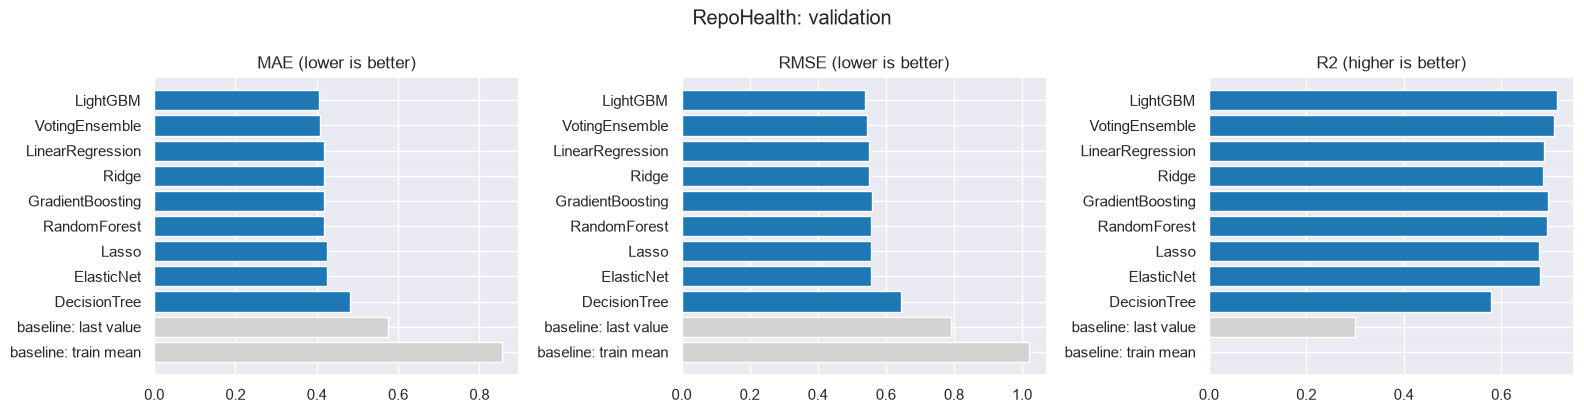

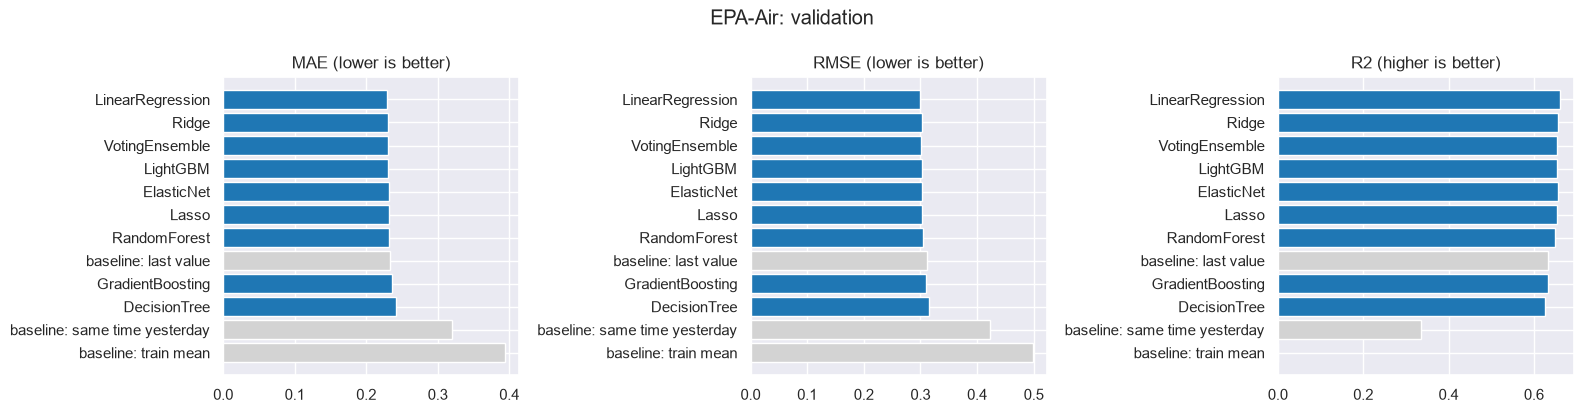

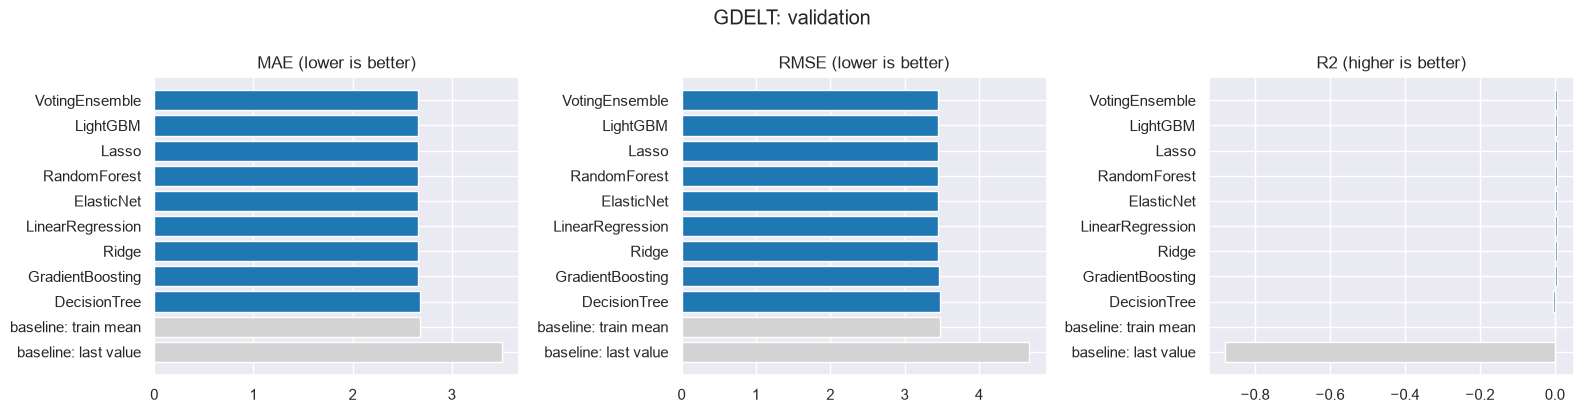

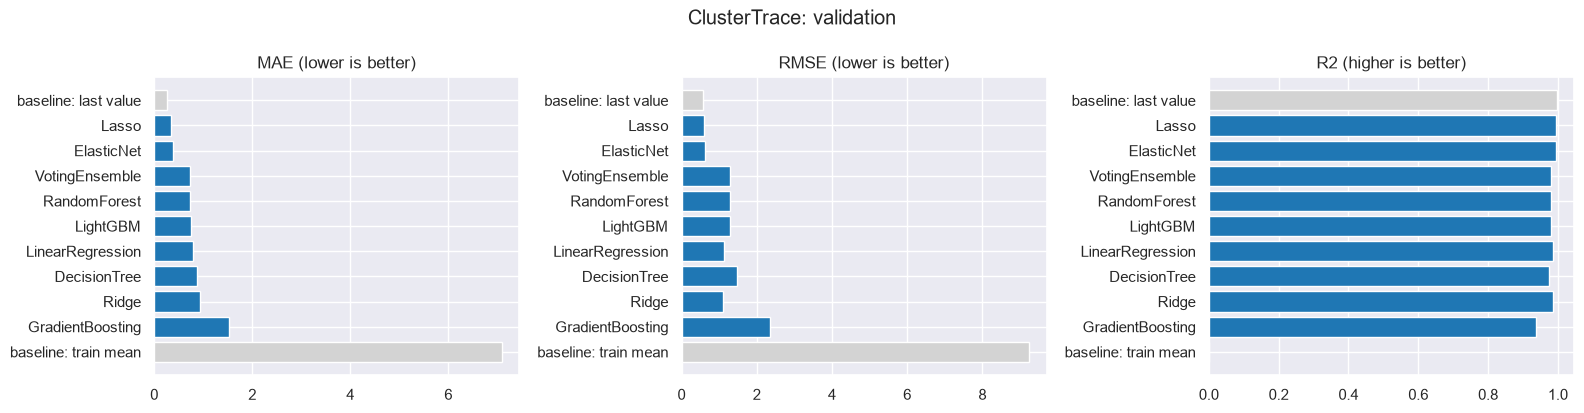

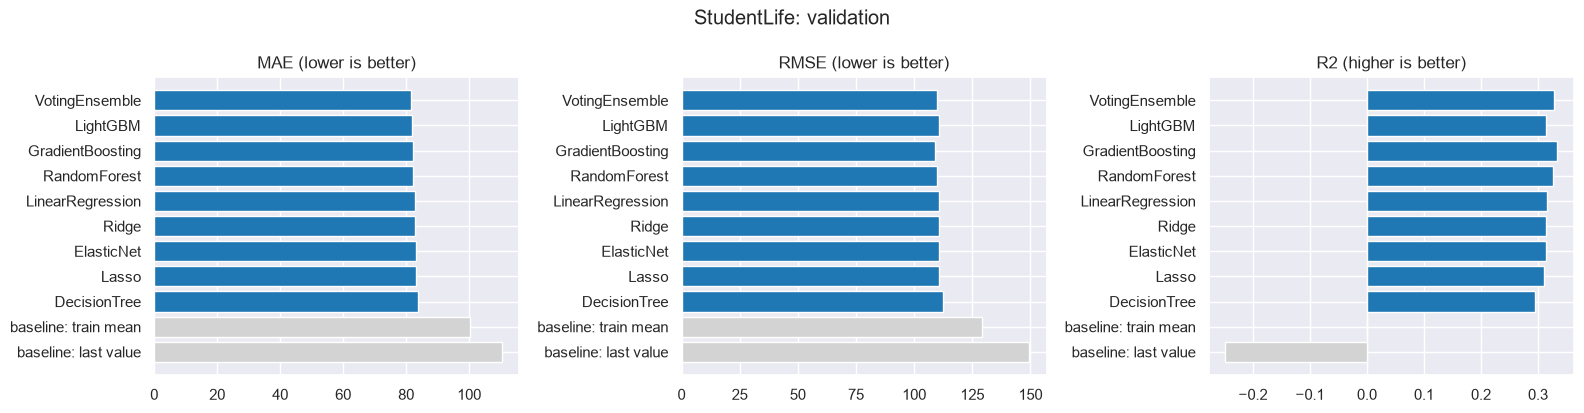

In [26]:
for ds, t in val_tables.items():
    print(f"\n{ds}  (validation, sorted by MAE; baselines in the same table)")
    display(t.sort_values("MAE").round(4))

rows = []
for ds, t in val_tables.items():
    is_base = t.index.str.startswith("baseline")
    base, mod = t[is_base], t[~is_base]
    bm, bb = mod["MAE"].idxmin(), base["MAE"].idxmin()
    g_best = 100 * (1 - mod.loc[bm, "MAE"] / base.loc[bb, "MAE"])
    g_mean = 100 * (1 - mod.loc[bm, "MAE"] / base.loc["baseline: train mean", "MAE"])
    verdict = "clear gain" if g_best >= 10 else "small gain" if g_best >= 2 else "no real gain"
    rows.append(dict(dataset=ds, best_model=bm, model_MAE=mod.loc[bm, "MAE"], best_baseline=bb,
                     baseline_MAE=base.loc[bb, "MAE"], gain_vs_best_baseline_pct=g_best,
                     gain_vs_train_mean_pct=g_mean, R2=mod.loc[bm, "R2"], verdict=verdict))
skill = pd.DataFrame(rows).set_index("dataset")
print("\nBest model vs best baseline (validation):")
display(skill.round(3))

for ds, t in val_tables.items():
    t = t.sort_values("MAE")
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    colors = ["lightgray" if m.startswith("baseline") else "tab:blue" for m in t.index]
    for ax, m in zip(axes, ["MAE", "RMSE", "R2"]):
        ax.barh(t.index, t[m], color=colors)
        ax.set_title(m + (" (higher is better)" if m == "R2" else " (lower is better)"))
        ax.invert_yaxis()
    fig.suptitle(f"{ds}: validation")
    fig.tight_layout()
    plt.show()

*The `verdict` column is a rule of thumb (10% or more better than the best baseline = clear, 2–10% = small, below 2% = none), not a statistical test.*
The best model is picked on validation. The final number comes from the locked test part in section 15.

**Which model is best?** (validation, MAE) The models are close to each other, so the dataset matters much more than the model: the best models are within 4.7% on RepoHealth, 1.3% on EPA-Air, 0.3% on GDELT and 1.6% on StudentLife. Best on validation: RepoHealth LightGBM (29% better than "repeat the last value"), EPA-Air LinearRegression (1.6%), GDELT VotingEnsemble (0.8% better than the train mean), StudentLife VotingEnsemble (19%). On ClusterTrace no model beats "repeat the last value" (0.259 vs 0.337). On EPA-Air a plain linear model is as good as anything; on RepoHealth the tree models are ahead of the linear ones (section 15).


## 10. Feature importance
Two views: the scaled `Ridge` coefficients (linear effect) and the share of the total *gain* of `LightGBM` (how much error reduction a column produced in the trees).
A column that is used often is not automatically useful; these tables describe what the model uses, not what causes the target.

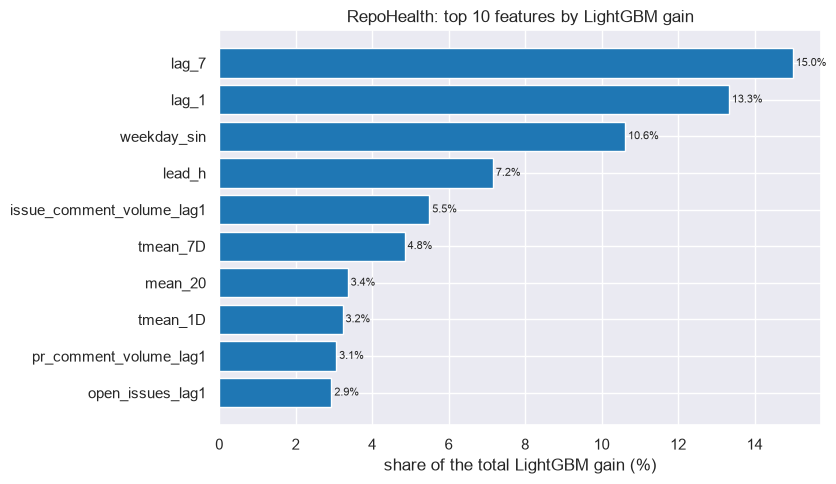


RepoHealth: top 10 by LightGBM gain share


,ridge_coef (scaled),lightgbm_gain_share
lag_7,0.1146,0.1500
lag_1,0.0717,0.1333
weekday_sin,0.2924,0.1061
lead_h,0.7536,0.0716
issue_comment_volume_lag1,0.0398,0.0549
tmean_7D,0.1964,0.0485
mean_20,-0.0303,0.0336
tmean_1D,0.0717,0.0322
pr_comment_volume_lag1,0.0395,0.0306
open_issues_lag1,0.0706,0.0293



EPA-Air: top 10 by LightGBM gain share


,ridge_coef (scaled),lightgbm_gain_share
lag_1,0.7534,0.3164
tmean_1D,0.2420,0.0950
temp_lag1,0.0257,0.0599
lag_3,0.2906,0.0591
lag_2,-0.0769,0.0428
lag_5,0.1362,0.0406
tstd_1D,-0.0756,0.0361
lag_7,-0.0316,0.0338
tstd_7D,0.1097,0.0338
mean_5,-0.5524,0.0322



GDELT: top 10 by LightGBM gain share


,ridge_coef (scaled),lightgbm_gain_share
tmean_7D,0.0646,0.1568
tmean_1D,0.0369,0.0868
tcount_7D,-0.0013,0.0478
std_5,0.0033,0.0449
mean_20,0.0708,0.0436
lag_1,0.0233,0.0429
lag_5,-0.0059,0.0423
lag_2,0.0201,0.0418
lead_h,0.0176,0.0413
tstd_7D,0.0091,0.0409



ClusterTrace: top 10 by LightGBM gain share


,ridge_coef (scaled),lightgbm_gain_share
lag_1,0.3161,0.4029
lag_2,0.1771,0.1464
machine_load_1_lag1,0.0693,0.1163
machine_cpu_usr_lag1,0.3199,0.0856
lead_h,-0.0284,0.0182
std_20,0.0015,0.0145
mean_5,0.0995,0.0141
gap_prev_h,-0.0248,0.0136
machine_cpu_kernel_lag1,0.0796,0.0128
tmean_1D,-0.0321,0.0128



StudentLife: top 10 by LightGBM gain share


,ridge_coef (scaled),lightgbm_gain_share
tmean_7D,0.0888,0.2821
mean_20,0.2453,0.2596
mean_5,0.1693,0.0374
act_walking_lag1,0.0064,0.0334
act_still_lag1,0.0116,0.0322
lag_7,0.0558,0.0291
std_20,-0.0294,0.0277
unlock_num_ep_0_lag1,-0.0286,0.0225
act_in_vehicle_lag1,0.0393,0.0194
loc_study_duration_missing_hours_lag1,-0.0060,0.0193


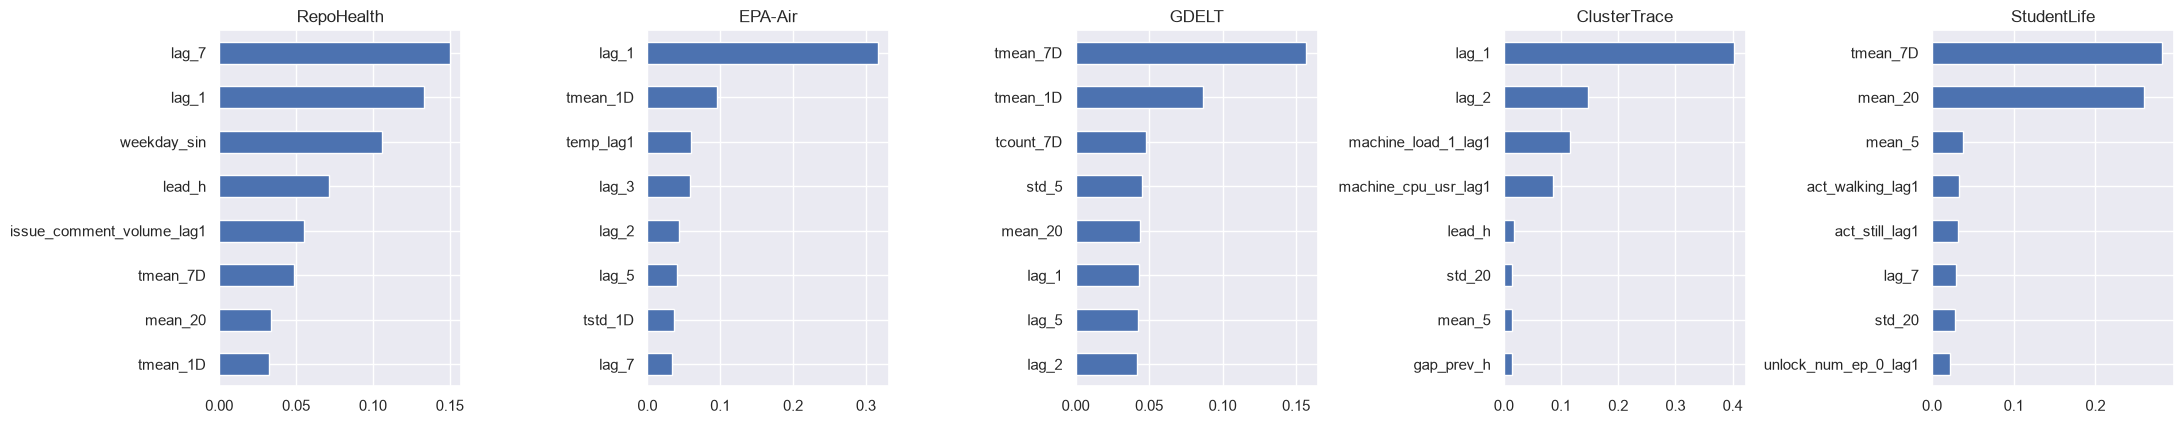

In [28]:
imp_all = {}
for ds in ALL_DS:
    imp = read_res(f"{ds}_feature_importance.csv", index_col=0)
    if imp is not None:
        imp_all[ds] = imp

if "RepoHealth" in imp_all:
    top = imp_all["RepoHealth"]["lightgbm_gain_share"].sort_values(ascending=False).head(10)
    fig, ax = plt.subplots(figsize=(8.5, 5))
    ax.barh(top.index[::-1], top.values[::-1] * 100, color="tab:blue")
    for i, v in enumerate(top.values[::-1] * 100):
        ax.text(v, i, f" {v:.1f}%", va="center", fontsize=8)
    ax.set_xlabel("share of the total LightGBM gain (%)")
    ax.set_title("RepoHealth: top 10 features by LightGBM gain")
    fig.tight_layout()
    plt.show()


for ds, imp in imp_all.items():
    print(f"\n{ds}: top 10 by LightGBM gain share")
    display(imp.sort_values("lightgbm_gain_share", ascending=False).head(10).round(4))

fig, axes = plt.subplots(1, len(imp_all), figsize=(4.4 * len(imp_all), 4.4), squeeze=False)
for ax, (ds, imp) in zip(axes.ravel(), imp_all.items()):
    imp["lightgbm_gain_share"].sort_values(ascending=False).head(8)[::-1].plot.barh(ax=ax)
    ax.set_title(ds)
fig.tight_layout()
plt.show()

**What the models use** (LightGBM gain share and scaled Ridge coefficients above; these describe what the models use, not what causes the target):

* **RepoHealth:** the target's own history and the calendar: `lag_7` (15.0% of the gain), `lag_1` (13.3%), `weekday_sin` (10.6%) and `lead_h` (7.2%, the time until the target; I did not test why it matters).
* **EPA-Air:** `lag_1` dominates (31.6%; Ridge coefficient 0.75), then the 1-day average (9.5%) and `temp` (6.0%). This agrees with section 13.
* **GDELT:** no feature stands out (top: the 7-day mean, 15.7%), which fits a target that is close to noise (R² about 0.01).
* **ClusterTrace:** `lag_1` (40%) and `lag_2` (15%), then other CPU-related columns that move with the target.
* **StudentLife:** averages, not the last night: the 7-day mean (28%) and the 20-observation mean (26%); `lag_1` is not in the top 10.


## 11. Cross-validation (walk-forward, inside the training part)
The mean and the spread over the 8 folds. The spread matters: a difference smaller than the spread between folds is not a real difference.


RepoHealth  (8 walk-forward folds, sorted by mean MAE)


,cv_MAE_mean,cv_MAE_std,cv_R2_mean,cv_R2_std
ElasticNet,0.3794,0.0543,0.5671,0.0718
Lasso,0.3807,0.0535,0.5639,0.0710
VotingEnsemble,0.3837,0.0731,0.5573,0.0541
LightGBM,0.3845,0.0709,0.5452,0.0632
LinearRegression,0.3894,0.0590,0.5558,0.0713
Ridge,0.3897,0.0572,0.5481,0.0860
RandomForest,0.3903,0.0774,0.5522,0.0518
GradientBoosting,0.3980,0.0675,0.5204,0.1454
DecisionTree,0.4345,0.0963,0.4622,0.0563
baseline: last value,0.5095,0.0634,0.0725,0.2035



EPA-Air  (8 walk-forward folds, sorted by mean MAE)


,cv_MAE_mean,cv_MAE_std,cv_R2_mean,cv_R2_std
Lasso,0.2666,0.0316,0.5039,0.0549
VotingEnsemble,0.2667,0.0325,0.5015,0.0478
ElasticNet,0.2667,0.0326,0.5048,0.0556
RandomForest,0.2673,0.0321,0.4990,0.0494
LinearRegression,0.2678,0.0392,0.5031,0.0650
Ridge,0.2681,0.0362,0.5008,0.0599
LightGBM,0.2700,0.0336,0.4901,0.0494
GradientBoosting,0.2729,0.0361,0.4841,0.0574
DecisionTree,0.2856,0.0314,0.4345,0.0586
baseline: last value,0.2902,0.0323,0.4004,0.0583



GDELT  (8 walk-forward folds, sorted by mean MAE)


,cv_MAE_mean,cv_MAE_std,cv_R2_mean,cv_R2_std
VotingEnsemble,2.7094,0.0936,0.0111,0.0099
LightGBM,2.7128,0.0939,0.0064,0.0095
RandomForest,2.7132,0.0926,0.0107,0.0111
Lasso,2.7199,0.1052,0.0099,0.0092
ElasticNet,2.7208,0.1037,0.0093,0.0104
Ridge,2.7219,0.1011,0.0086,0.0116
LinearRegression,2.7241,0.0987,0.0063,0.0134
GradientBoosting,2.7396,0.0879,-0.0023,0.0226
baseline: train mean,2.7513,0.1153,0.0000,0.0000
DecisionTree,2.7640,0.0975,-0.0231,0.0422



ClusterTrace  (8 walk-forward folds, sorted by mean MAE)


,cv_MAE_mean,cv_MAE_std,cv_R2_mean,cv_R2_std
baseline: last value,0.4005,0.1498,0.9763,0.0200
Lasso,0.7452,0.5959,0.9617,0.0436
ElasticNet,0.8624,0.6537,0.9574,0.0461
VotingEnsemble,1.0994,0.5827,0.9398,0.0543
LightGBM,1.1205,0.4171,0.9262,0.0872
RandomForest,1.2214,0.8840,0.9314,0.0832
Ridge,1.2221,0.6039,0.9386,0.0451
GradientBoosting,1.6888,1.2037,0.8815,0.1378
DecisionTree,1.7825,2.1878,0.7945,0.4018
LinearRegression,5.8082,10.1463,-1.7676,7.2463



StudentLife  (8 walk-forward folds, sorted by mean MAE)


,cv_MAE_mean,cv_MAE_std,cv_R2_mean,cv_R2_std
VotingEnsemble,94.5075,8.6686,0.2736,0.1677
Lasso,94.9909,6.9526,0.2948,0.1733
RandomForest,95.0858,7.9249,0.2730,0.1670
LightGBM,95.0965,9.3280,0.2536,0.1659
Ridge,95.1243,6.7842,0.2898,0.1684
ElasticNet,95.3864,7.3129,0.2895,0.1846
GradientBoosting,95.7739,7.7743,0.2762,0.1684
LinearRegression,96.1140,7.8468,0.2790,0.1929
DecisionTree,98.7307,8.4023,0.2026,0.2075
baseline: train mean,107.8904,10.2050,0.0000,0.0000


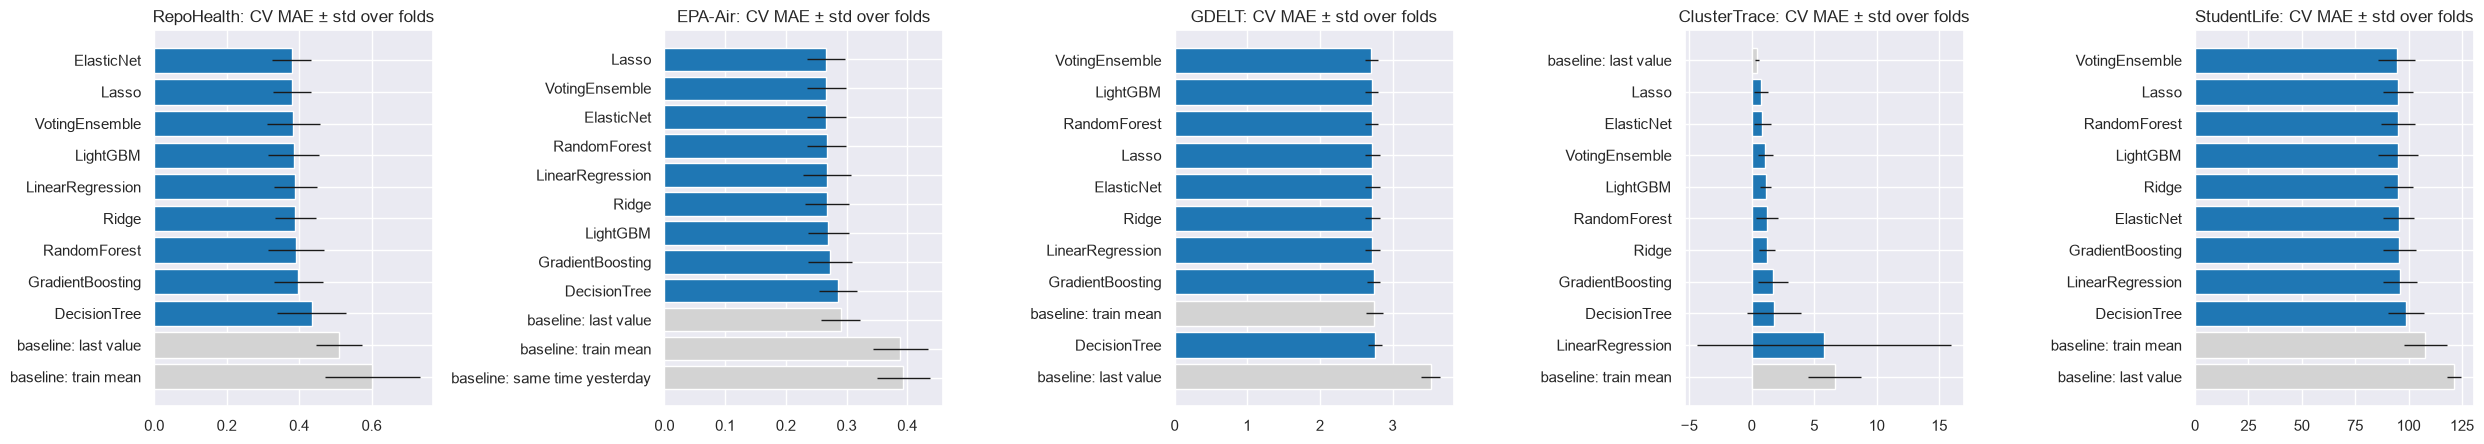

,best_by_CV,best_by_validation,rank_agreement_spearman
dataset,,,
RepoHealth,ElasticNet,LightGBM,0.150
EPA-Air,Lasso,LinearRegression,0.333
GDELT,VotingEnsemble,VotingEnsemble,0.967
ClusterTrace,Lasso,Lasso,0.833
StudentLife,VotingEnsemble,VotingEnsemble,0.433


In [30]:
for ds, c in cv_tables.items():
    print(f"\n{ds}  (8 walk-forward folds, sorted by mean MAE)")
    display(c.round(4))

fig, axes = plt.subplots(1, len(cv_tables), figsize=(5 * len(cv_tables), 4.6), squeeze=False)
for ax, (ds, c) in zip(axes.ravel(), cv_tables.items()):
    c = c.sort_values("cv_MAE_mean")
    ax.barh(c.index, c["cv_MAE_mean"], xerr=c["cv_MAE_std"],
            color=["lightgray" if m.startswith("baseline") else "tab:blue" for m in c.index], error_kw={"lw": 1})
    ax.invert_yaxis()
    ax.set_title(f"{ds}: CV MAE ± std over folds")
fig.tight_layout()
plt.show()



rows = []
for ds in cv_tables:
    if ds not in val_tables:
        continue
    c, v = cv_tables[ds], val_tables[ds]
    common = [m for m in c.index if m in v.index and not m.startswith("baseline")]
    rho = stats.spearmanr(c.loc[common, "cv_MAE_mean"], v.loc[common, "MAE"])[0]
    rows.append(dict(dataset=ds, best_by_CV=c.loc[common, "cv_MAE_mean"].idxmin(),
                     best_by_validation=v.loc[common, "MAE"].idxmin(), rank_agreement_spearman=rho))
agree = pd.DataFrame(rows).set_index("dataset")
display(agree.round(3))

**Do validation and cross-validation agree?** `rank_agreement_spearman` is 1 if both rank the models in the same order and near 0 if the order is unrelated.

* Both pick the same best model for GDELT (VotingEnsemble), ClusterTrace (Lasso) and StudentLife (VotingEnsemble), but not for RepoHealth (ElasticNet by CV, LightGBM on validation) and EPA-Air (Lasso by CV, LinearRegression on validation).
* The rank agreement is 0.97 for GDELT, 0.83 for ClusterTrace, 0.43 for StudentLife, 0.33 for EPA-Air and 0.15 for RepoHealth. My earlier guess that the order would be unrelated on GDELT (no signal) was wrong.
* Where the order is unrelated, the models are very close: the best eight CV models on RepoHealth are within 4.9% of each other and the best six on EPA-Air within 0.6%, less than the fold-to-fold spread (std 0.05 to 0.07 on a mean of 0.38). The clearly weak models are weak in both tables.


## 12. Is the model strong?
The *gate*: an optional dataset is only kept if its best numeric model reaches a cross-validated R² of at least 0.05 against the train mean.
A high R² alone proves little, so **always compare with the baselines**.


,dataset,best_cv_R2,optional,passed
0,RepoHealth,0.5671,False,True
1,EPA-Air,0.5048,False,True
2,GDELT,0.0111,False,True
3,ClusterTrace,0.9617,True,True
4,StudentLife,0.2948,True,True


,best_model,gain_vs_best_baseline_pct,gain_vs_train_mean_pct,R2,verdict
dataset,,,,,
RepoHealth,LightGBM,29.409,52.635,0.714,clear gain
EPA-Air,LinearRegression,1.558,41.900,0.661,no real gain
GDELT,VotingEnsemble,0.826,0.826,0.007,no real gain
ClusterTrace,Lasso,-30.285,95.252,0.996,no real gain
StudentLife,VotingEnsemble,18.724,18.724,0.328,clear gain


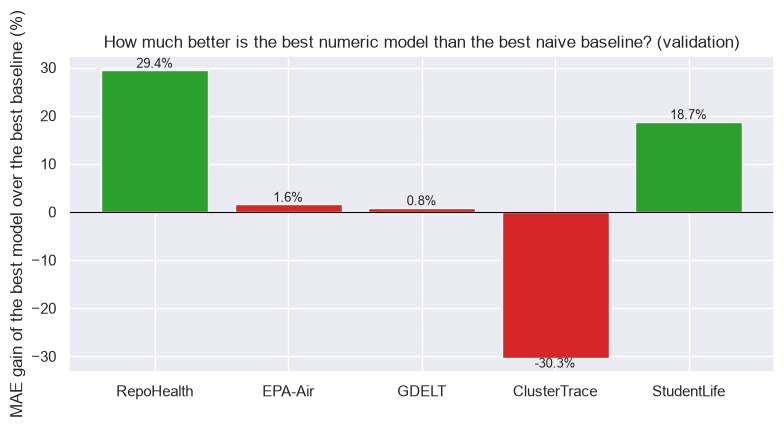

In [32]:
gate = read_res("gate.csv")
if gate is not None:
    display(gate.round(4))
display(skill[["best_model", "gain_vs_best_baseline_pct", "gain_vs_train_mean_pct", "R2", "verdict"]].round(3))


fig, ax = plt.subplots(figsize=(8, 4))
colors = skill["verdict"].map({"clear gain": "tab:green", "small gain": "gold", "no real gain": "tab:red"})
ax.bar(skill.index, skill["gain_vs_best_baseline_pct"], color=colors)
for i, v in enumerate(skill["gain_vs_best_baseline_pct"]):
    ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("MAE gain of the best model over the best baseline (%)")
ax.set_title("How much better is the best numeric model than the best naive baseline? (validation)")
fig.tight_layout()
plt.show()

* **Gate.** All five datasets pass. ClusterTrace (CV R² 0.96) and StudentLife (0.29) are above the 0.05 limit. GDELT (CV R² 0.011) is below it and stays only because the three main datasets are exempt (it is the negative control).
* **A high R² is not proof of a strong model.** ClusterTrace has an R² of 0.96 to 0.99, yet "repeat the last value" beats every model on validation (MAE 0.259 vs 0.337), in cross-validation (0.40 vs 0.75) and on the locked test (0.324 vs 0.333). The gate measures the gain over the train *mean*, so it cannot see this: the series is almost perfectly persistent and the models only add estimation noise.


## 13. Does the model live on the latest value? (lag ablation)
A fair worry: if the model is good only because it copies `lag_1`, "good" means little. `lag_ablation.py` retrains the models with parts of the target history removed
(same walk-forward folds, test part not used; LightGBM untuned here so that four feature sets stay cheap):

| Feature set | What is removed |
|---|---|
| all features | nothing |
| no lag_1 | only `lag_1` (the rolling means still contain the latest value) |
| no latest value | `lag_1` and every rolling mean/std that includes it |
| no target history | all past values of the target |

**Test 2** splits the rows by how far `lag_1` is from its recent average (`|lag_1 - mean_20| / std_20`): *near* (lowest 50%), *mid*, *far* (top 10%, the spikes).


EPA-Air: MAE (lower is better).  Baselines: last value: CV 0.2902, validation 0.2328, train mean: CV 0.3889, validation 0.3944


CV MAE         validation MAE        
model             LightGBM   Ridge       LightGBM   Ridge
feature set                                              
all features        0.2706  0.2681         0.2292  0.2298
no lag_1            0.2842  0.2703         0.2445  0.2324
no latest value     0.3403  0.3416         0.3045  0.3057
no target history   0.4140  0.3954         0.4299  0.4181


RepoHealth: MAE (lower is better).  Baselines: last value: CV 0.5095, validation 0.5740, train mean: CV 0.6024, validation 0.8555


CV MAE         validation MAE        
model             LightGBM   Ridge       LightGBM   Ridge
feature set                                              
all features        0.3791  0.3897         0.4029  0.4185
no lag_1            0.3759  0.3904         0.4195  0.4185
no latest value     0.3961  0.4098         0.4618  0.4489
no target history   0.4043  0.4328         0.4763  0.4943

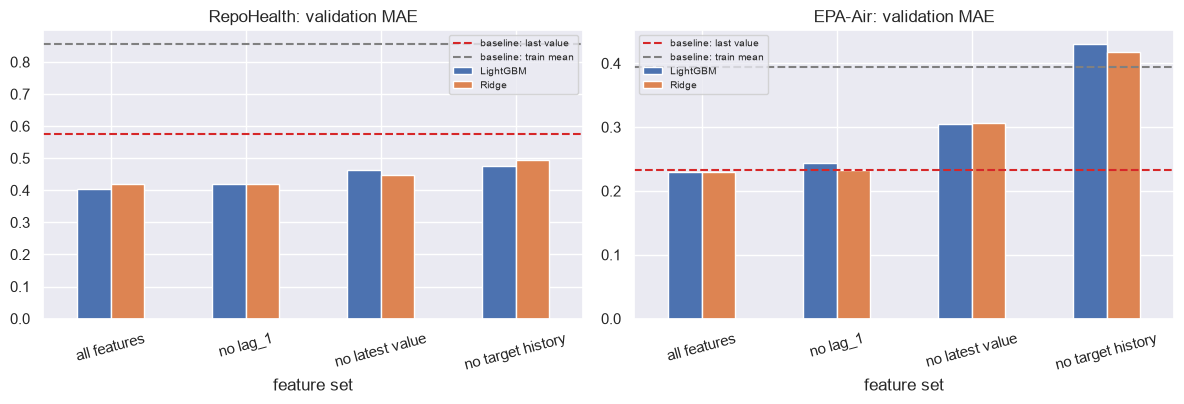

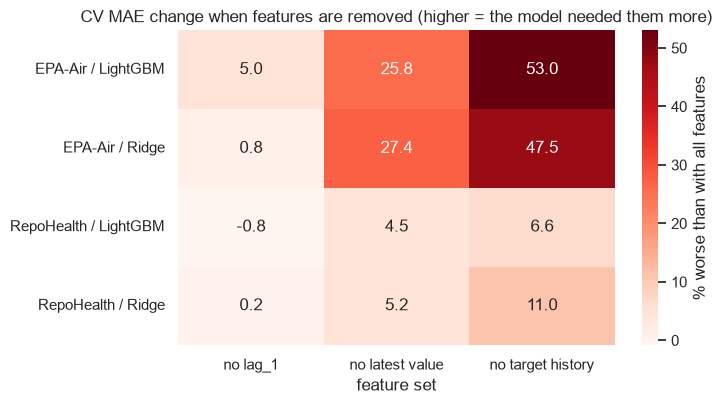


EPA-Air: pooled out-of-sample MAE by how far the latest value is from its recent average


group,near (lowest 50%),mid (50-90%),far (top 10%)
n rows,1344.000,1075.000,269.000
MAE last value,0.260,0.303,0.364
MAE train mean,0.318,0.423,0.577
MAE Ridge / all features,0.250,0.274,0.297
MAE Ridge / no latest value,0.296,0.356,0.469
"Ridge (all) beats last value, share of rows",0.522,0.567,0.621
MAE LightGBM / all features,0.251,0.278,0.298
MAE LightGBM / no latest value,0.303,0.346,0.440
"LightGBM (all) beats last value, share of rows",0.530,0.562,0.561



RepoHealth: pooled out-of-sample MAE by how far the latest value is from its recent average


group,near (lowest 50%),mid (50-90%),far (top 10%)
n rows,1773.000,1418.000,355.000
MAE last value,0.445,0.488,0.957
MAE train mean,0.502,0.531,0.669
MAE Ridge / all features,0.349,0.355,0.454
MAE Ridge / no latest value,0.363,0.377,0.471
"Ridge (all) beats last value, share of rows",0.600,0.646,0.769
MAE LightGBM / all features,0.339,0.347,0.419
MAE LightGBM / no latest value,0.347,0.357,0.429
"LightGBM (all) beats last value, share of rows",0.609,0.650,0.755


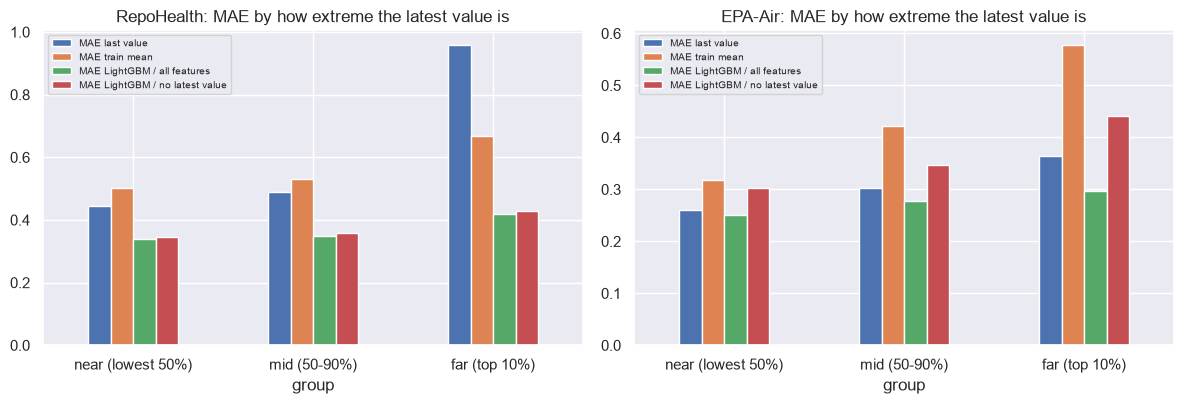

In [34]:
t1 = read_res("lag_ablation.csv")
t2 = read_res("lag_ablation_hard_cases.csv")
ORDER = ["all features", "no lag_1", "no latest value", "no target history"]
if t1 is not None:
    dss = list(t1["dataset"].unique())
    for ds, g in t1.groupby("dataset"):
        pv = g[g["feature set"] != "baseline"].pivot_table(index="feature set", columns="model",
                                                           values=["CV MAE", "validation MAE"]).reindex(ORDER)
        b = g[g["feature set"] == "baseline"].set_index("model")
        print(f"\n{ds}: MAE (lower is better).  Baselines: " +
              ", ".join(f"{k}: CV {r['CV MAE']:.4f}, validation {r['validation MAE']:.4f}" for k, r in b.iterrows()))
        display(pv.round(4))



    fig, axes = plt.subplots(1, len(dss), figsize=(6 * len(dss), 4.2), squeeze=False)
    for ax, ds in zip(axes.ravel(), dss):
        g = t1[(t1["dataset"] == ds) & (t1["feature set"] != "baseline")]
        g.pivot_table(index="feature set", columns="model", values="validation MAE").reindex(ORDER).plot.bar(ax=ax, rot=15)
        for name, col in [("last value", "tab:red"), ("train mean", "gray")]:
            b = t1[(t1["dataset"] == ds) & (t1["feature set"] == "baseline") & (t1["model"] == name)]
            if len(b):
                ax.axhline(b["validation MAE"].iloc[0], color=col, ls="--", label=f"baseline: {name}")
        ax.set_title(f"{ds}: validation MAE")
        ax.legend(fontsize=7)
    fig.tight_layout()
    plt.show()



    h = t1[t1["feature set"].isin(ORDER[1:])].copy()
    h["row"] = h["dataset"] + " / " + h["model"]
    hm = h.pivot_table(index="row", columns="feature set", values="CV change vs all features %").reindex(columns=ORDER[1:])
    fig, ax = plt.subplots(figsize=(7.5, 0.55 * len(hm) + 2))
    sns.heatmap(hm, annot=True, fmt=".1f", cmap="Reds", ax=ax, cbar_kws={"label": "% worse than with all features"})
    ax.set_title("CV MAE change when features are removed (higher = the model needed them more)")
    ax.set_ylabel("")
    fig.tight_layout()
    plt.show()

if t2 is not None:
    for ds, g in t2.groupby("dataset"):
        print(f"\n{ds}: pooled out-of-sample MAE by how far the latest value is from its recent average")
        display(g.drop(columns="dataset").set_index("group").T.round(3))
    dss2 = list(t2["dataset"].unique())
    fig, axes = plt.subplots(1, len(dss2), figsize=(6 * len(dss2), 4.2), squeeze=False)
    for ax, ds in zip(axes.ravel(), dss2):
        g = t2[t2["dataset"] == ds].set_index("group")
        cols_ = [c for c in ["MAE last value", "MAE train mean", "MAE LightGBM / all features", "MAE LightGBM / no latest value"] if c in g.columns]
        g[cols_].plot.bar(ax=ax, rot=0)
        ax.set_title(f"{ds}: MAE by how extreme the latest value is")
        ax.legend(fontsize=7)
    fig.tight_layout()
    plt.show()


* *"no latest value" close to "all features"* -> the model does not live on the latest value.
* *Much worse* -> it depends on it. That is not a failure (a good forecaster should use the latest value); the claim is then "the model adds something beyond the latest value".
* In the **far** group the model should still beat "repeat the last value" (lower MAE, share of rows above 50%).

**What I found** (tables above):

* **RepoHealth:** without the latest value the error is about 5% larger in cross-validation and 7-15% larger on validation, yet the models stay about 20% better than "repeat the last value" (CV 0.396 / 0.410 vs 0.510). On the top 10% of spikes the error of "last value" (0.957) is more than twice the model's (0.419, or 0.429 without the latest value). The advantage does not come from copying `lag_1`.
* **EPA-Air:** without the latest value the error grows by 26-33% and is worse than repeating the last value (CV 0.340 vs 0.290); without any target history it is worse than the train mean. The series is "latest value plus a small correction", which helps most on spikes (about 18% better than "last value" there, 3-4% in ordinary cases).
* **Limits:** LightGBM is not tuned here, other columns can carry the same information as the target, and differences of 1-2% are inside the fold-to-fold noise.


## 14. Does text help? (the research question)
Same models, same folds, with and without text. The text sets:

| Feature set | What is added to the numeric features |
|---|---|
| numeric only | nothing |
| + TF-IDF | TF-IDF of all texts in the window, shrunk to 20 numbers with SVD (vocabulary, IDF and SVD fitted on training rows of each fold only) |
| + RecAvg | recency-weighted average of sentence embeddings (all-MiniLM-L6-v2), shrunk to 20 numbers with PCA; Gaussian weight `exp(-(dt/sigma)^2)` |
| + LatestText | embedding of only the newest text in the window |
| + LLM | one-hot of the integer code a local LLM (qwen3.5:4b) gave to the newest text (RepoHealth 0–5, GDELT −2…2) plus a "has text" flag |

Text windows end at the **forecast origin**, never later. This is **Task B** of section 5 (long horizons), so its MAEs are not comparable with sections 8-13. The horizons are in the table of section 5.
Models: Ridge, RandomForest, LightGBM, VotingEnsemble. Test: **Diebold-Mariano** on the pooled out-of-sample errors (Harvey-Leybourne-Newbold correction, Newey-West variance),
Benjamini-Hochberg correction inside each family of tests.

### 14.1 Validation and cross-validation: numeric only vs the text sets

runs found: ['ClusterTrace_h12', 'ClusterTrace', 'EPA-Air_h168', 'EPA-Air', 'GDELT_h336', 'GDELT', 'RepoHealth_h744', 'RepoHealth', 'StudentLife_h744', 'StudentLife']



Best model with text against best numeric-only model (MAE; the full tables per model are in results/*_text_val.csv and *_text_cv.csv):


,run,part,best baseline MAE,best numeric-only model,best model with text,"text vs numeric (%, + = text better)"
0,ClusterTrace,validation,0.3981,Ridge 0.1730,Ridge + TF-IDF 0.1740,-0.58
1,ClusterTrace,cross-validation,0.3261,LightGBM 0.1929,RandomForest + TF-IDF 0.1927,0.10
2,ClusterTrace_h12,validation,6.5578,Ridge 5.4151,LightGBM + RecAvg 5.3574,1.07
3,ClusterTrace_h12,cross-validation,4.7364,RandomForest 5.8972,VotingEnsemble + LatestText 6.0080,-1.88
4,EPA-Air,validation,0.3944,Ridge 0.2290,Ridge + TF-IDF 0.2317,-1.18
5,EPA-Air,cross-validation,0.3889,Ridge 0.2662,RandomForest + TF-IDF 0.2688,-0.98
6,EPA-Air_h168,validation,0.3962,LightGBM 0.3807,RandomForest + TF-IDF 0.3813,-0.16
7,EPA-Air_h168,cross-validation,0.3928,VotingEnsemble 0.3817,Ridge + LatestText 0.3806,0.29
8,GDELT,validation,2.6787,LightGBM 2.6626,Ridge + TF-IDF 2.6538,0.33
9,GDELT,cross-validation,2.7513,LightGBM 2.7124,LightGBM + TF-IDF 2.7163,-0.14


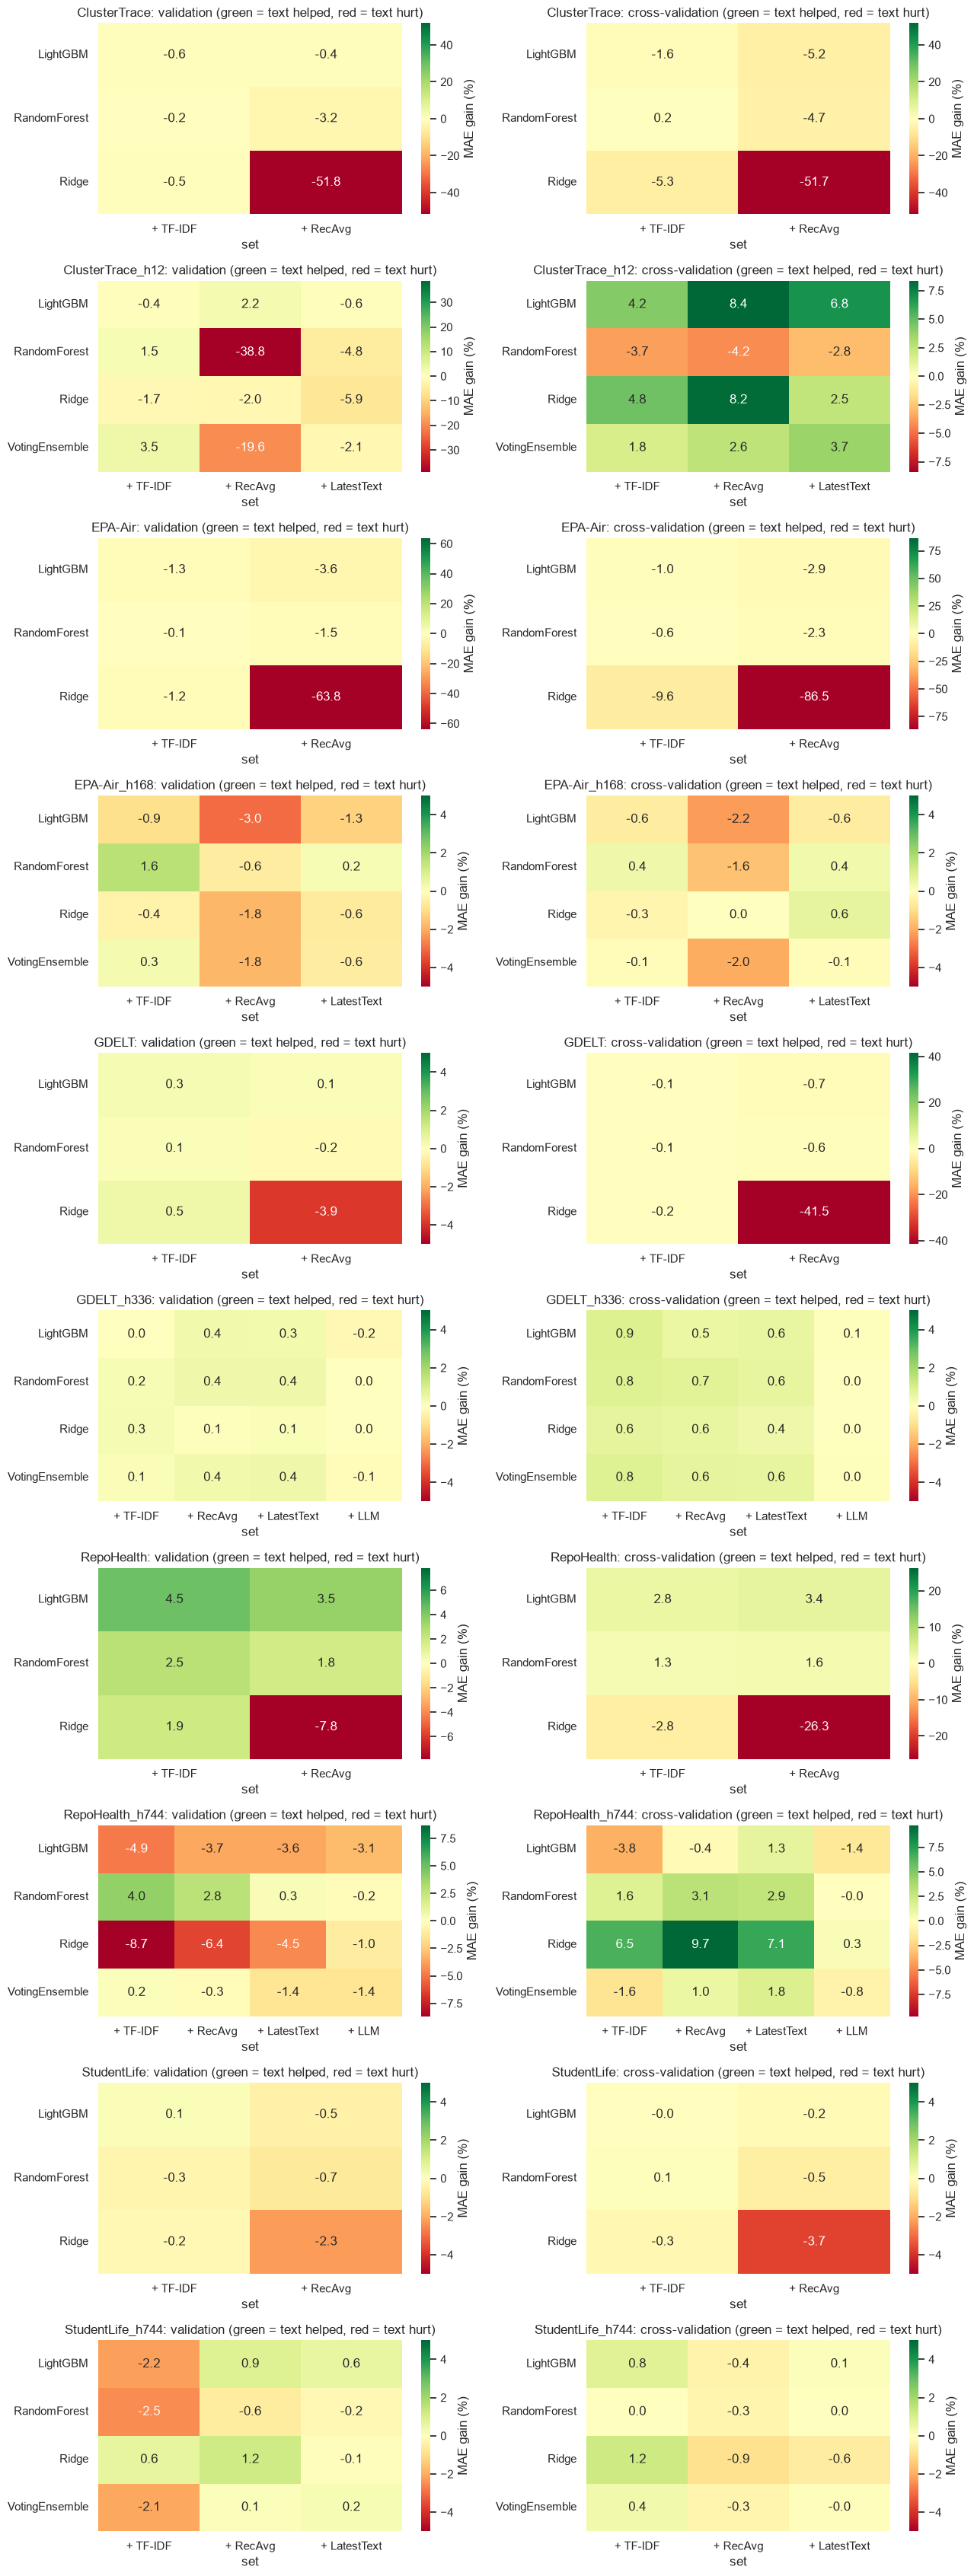

In [38]:
SETS = ["numeric only", "+ TF-IDF", "+ RecAvg", "+ LatestText", "+ LLM"]
val_files = sorted(RES.glob("*_text_val.csv"))
cv_files = sorted(RES.glob("*_text_cv.csv"))
print("runs found:", [f.name.replace("_text_val.csv", "") for f in val_files])


def pivot_sets(tbl, col="MAE"):
    t = tbl[tbl["set"] != "baseline"]
    p = t.pivot_table(index="model", columns="set", values=col, aggfunc="mean")
    return p[[s for s in SETS if s in p.columns]]


gain_tables, summary = {}, []
for kind, files in [("VALIDATION", val_files), ("CROSS-VALIDATION (mean of 8 folds)", cv_files)]:
    for f in files:
        run = f.name.replace("_text_val.csv", "").replace("_text_cv.csv", "")
        tbl = pd.read_csv(f)
        p = pivot_sets(tbl)
        gain = 100 * (1 - p.div(p["numeric only"], axis=0))
        base = tbl[tbl["set"] == "baseline"].groupby("model")["MAE"].mean()
        gain_tables[(run, kind.split()[0])] = gain

        num_model = p["numeric only"].idxmin()
        with_text = p.drop(columns="numeric only").stack()
        text_model, text_set = with_text.idxmin()
        summary.append({"run": run, "part": "validation" if kind == "VALIDATION" else "cross-validation",
                        "best baseline MAE": round(base.min(), 4),
                        "best numeric-only model": f"{num_model} {p.loc[num_model, 'numeric only']:.4f}",
                        "best model with text": f"{text_model} {text_set} {with_text.min():.4f}",
                        "text vs numeric (%, + = text better)": round(100 * (1 - with_text.min() / p["numeric only"].min()), 2)})

print("\nBest model with text against best numeric-only model (MAE; the full tables per model are in results/*_text_val.csv and *_text_cv.csv):")
display(pd.DataFrame(summary).sort_values(["run", "part"], ascending=[True, False]).reset_index(drop=True))


runs = sorted({r for r, _ in gain_tables})
if runs:
    fig, axes = plt.subplots(len(runs), 2, figsize=(13, 3.4 * len(runs)), squeeze=False)
    for i, run in enumerate(runs):
        for j, kind in enumerate(["VALIDATION", "CROSS-VALIDATION"]):
            ax = axes[i, j]
            g = gain_tables.get((run, kind))
            if g is None:
                ax.axis("off")
                continue
            g = g.drop(columns="numeric only", errors="ignore")
            lim = max(5, float(np.nanmax(np.abs(g.values))))
            sns.heatmap(g, annot=True, fmt=".1f", cmap="RdYlGn", center=0, vmin=-lim, vmax=lim, ax=ax,
                        cbar_kws={"label": "MAE gain (%)"})
            ax.set_title(f"{run}: {kind.lower()} (green = text helped, red = text hurt)")
            ax.set_ylabel("")
    fig.tight_layout()
    plt.show()


### 14.2 Hypothesis tests (Diebold-Mariano) and the RepoHealth / GDELT bar charts
`rel_gain_pct > 0` means the text set has the lower error. `entities_better` = in how many entities the text set had the lower mean loss.
**Read the p-value together with the gain.** With thousands of pooled rows, even a 0.3% gain can be "significant".
In the bar charts a **star (\*)** marks `p_fdr < 0.05`.

In [39]:
show_code("text_features.py", r"def steps_ahead", r"def dm_tests", "- the Diebold-Mariano test (HLN correction, Newey-West, entities blocked)")


**text_features.py`, lines 153-190**  - the Diebold-Mariano test (HLN correction, Newey-West, entities blocked)

```python
def steps_ahead(data):
    out = np.ones(len(data))
    t_all, c_all = to_ns(data["date_time"]), to_ns(data["t_cut"])
    for idx in data.groupby("entity_id").indices.values():
        t, c = t_all[idx], c_all[idx]
        out[idx] = np.searchsorted(t, t, side="right") - np.searchsorted(t, c, side="right")
    return out


def dm_test(loss_a, loss_b, entity_ids, h_steps):
    la, lb = np.asarray(loss_a, float), np.asarray(loss_b, float)
    d, n = la - lb, len(la)
    res = dict(n=n, rel_gain_pct=100 * (la.mean() - lb.mean()) / la.mean() if la.mean() > 0 else np.nan,
               dm_stat=np.nan, p_value=np.nan, entities_better="")
    ents = np.asarray(entity_ids)
    _, first = np.unique(ents, return_index=True)
    bounds = list(np.sort(first)) + [n]
    blocks = [d[bounds[i]:bounds[i + 1]] for i in range(len(bounds) - 1)]
    better = sum(b.mean() > 0 for b in blocks)
    res["entities_better"] = f"{better}/{len(blocks)}"
    if n < 30 or not np.isfinite(d).all():
        return res
    dc = [b - d.mean() for b in blocks]
    lags = min(max(2 * h_steps, int(np.ceil(n ** (1 / 3)))), n // 4)

    def gamma(k):
        return sum(float(np.dot(b[k:], b[:len(b) - k])) for b in dc if len(b) > k) / n

    var = gamma(0) + 2 * sum((1 - k / (lags + 1)) * gamma(k) for k in range(1, lags + 1))
    if var <= 0:
        return res
    stat = d.mean() / np.sqrt(var / n)
    h = max(int(h_steps), 1)
    factor = (n + 1 - 2 * h + h * (h - 1) / n) / n 
    if factor > 0:
        stat *= np.sqrt(factor)
    res["dm_stat"], res["p_value"] = stat, 2 * student_t.sf(abs(stat), df=n - 1)
    return res
```

H1: 'numeric only' vs each text set, by run


,tests,significant (p_fdr<0.05),"of those, text better","of those, text worse"
run,,,,
GDELT_h336,16,12,12,0
RepoHealth_h744,16,2,2,0


,run,comparison,n,rel_gain_pct,p_value,p_fdr,entities_better,practical
0,RepoHealth_h744,Ridge: numeric only vs + TF-IDF,3512,5.3860,0.0398,0.0797,4/4,
1,RepoHealth_h744,Ridge: numeric only vs + RecAvg,3512,6.6038,0.0611,0.1151,4/4,
2,RepoHealth_h744,Ridge: numeric only vs + LatestText,3512,5.7858,0.0138,0.0341,4/4,
3,RepoHealth_h744,Ridge: numeric only vs + LLM,3512,0.3150,0.2669,0.3624,3/4,negligible (<1%)
10,RepoHealth_h744,RandomForest: numeric only vs + TF-IDF,3512,3.4580,0.1265,0.2024,1/4,
11,RepoHealth_h744,RandomForest: numeric only vs + RecAvg,3512,3.8342,0.0208,0.0474,3/4,
12,RepoHealth_h744,RandomForest: numeric only vs + LatestText,3512,1.8189,0.2750,0.3624,3/4,
13,RepoHealth_h744,RandomForest: numeric only vs + LLM,3512,-0.0166,0.8179,0.8443,3/4,negligible (<1%)
20,RepoHealth_h744,LightGBM: numeric only vs + TF-IDF,3512,-0.6464,0.7910,0.8437,2/4,negligible (<1%)
21,RepoHealth_h744,LightGBM: numeric only vs + RecAvg,3512,1.9196,0.2666,0.3624,2/4,


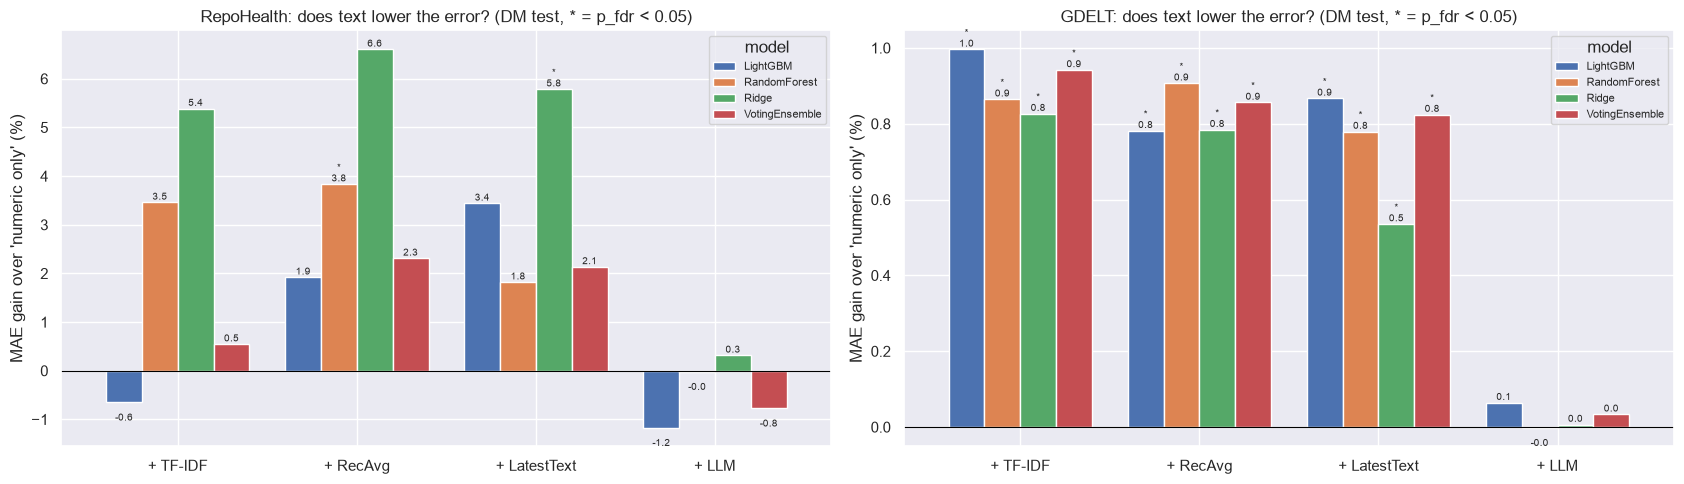


PRIMARY QUESTION of the LLM run: '+ LLM' vs 'numeric only' (FDR over these tests only)


,run,comparison,n,rel_gain_pct,p_value,p_fdr_llm_only,entities_better
0,RepoHealth_h744,Ridge: numeric only vs + LLM,3512,0.3150,0.2669,0.4893,3/4
1,RepoHealth_h744,RandomForest: numeric only vs + LLM,3512,-0.0166,0.8179,0.8703,3/4
2,RepoHealth_h744,LightGBM: numeric only vs + LLM,3512,-1.1684,0.2864,0.4893,0/4
3,RepoHealth_h744,VotingEnsemble: numeric only vs + LLM,3512,-0.7694,0.1467,0.4893,0/4
4,GDELT_h336,Ridge: numeric only vs + LLM,20132,0.0065,0.5752,0.7670,4/8
5,GDELT_h336,RandomForest: numeric only vs + LLM,20132,-0.0014,0.8703,0.8703,3/8
6,GDELT_h336,LightGBM: numeric only vs + LLM,20132,0.0642,0.3037,0.4893,6/8
7,GDELT_h336,VotingEnsemble: numeric only vs + LLM,20132,0.0335,0.3058,0.4893,6/8


In [40]:
dm = read_res("hypothesis_tests_dm.csv")
if dm is not None:
    h1 = dm[dm["hypothesis"] == "H1"].copy()
    parts = h1["comparison"].str.extract(r"^(?P<model>.+?):\s*numeric only\s+vs\s+(?P<text_set>.+)$")
    h1 = pd.concat([h1, parts], axis=1)
    h1["practical"] = np.where(h1["rel_gain_pct"].abs() < 1, "negligible (<1%)", "")

    summary = (h1.groupby("run")
                 .apply(lambda g: pd.Series({"tests": len(g),
                                             "significant (p_fdr<0.05)": int((g["p_fdr"] < 0.05).sum()),
                                             "of those, text better": int(((g["p_fdr"] < 0.05) & (g["rel_gain_pct"] > 0)).sum()),
                                             "of those, text worse": int(((g["p_fdr"] < 0.05) & (g["rel_gain_pct"] < 0)).sum())})))
    print("H1: 'numeric only' vs each text set, by run")
    display(summary)
    display(h1[["run", "comparison", "n", "rel_gain_pct", "p_value", "p_fdr", "entities_better", "practical"]].round(4))

    targets_ = [r for r in ["RepoHealth", "GDELT"] if h1["run"].str.startswith(r).any()]
    if targets_:
        fig, axes = plt.subplots(1, len(targets_), figsize=(8.5 * len(targets_), 5), squeeze=False)
        for ax, ds in zip(axes.ravel(), targets_):
            sub = h1[h1["run"].str.startswith(ds)]
            gain_p = sub.pivot_table(index="text_set", columns="model", values="rel_gain_pct").reindex([s for s in SETS[1:] if s in set(sub["text_set"])])
            sig_p = sub.pivot_table(index="text_set", columns="model", values="p_fdr").reindex(gain_p.index)
            gain_p.plot.bar(ax=ax, rot=0, width=0.8)
            for k, cont in enumerate(ax.containers):
                for i, bar in enumerate(cont):
                    v, pv = gain_p.iloc[i, k], sig_p.iloc[i, k]
                    if pd.notna(v):
                        ax.text(bar.get_x() + bar.get_width() / 2, v, ("*" if pd.notna(pv) and pv < 0.05 else "") + f"\n{v:.1f}",
                                ha="center", va="bottom" if v >= 0 else "top", fontsize=7)
            ax.axhline(0, color="black", lw=0.8)
            ax.set_ylabel("MAE gain over 'numeric only' (%)")
            ax.set_xlabel("")
            ax.set_title(f"{ds}: does text lower the error? (DM test, * = p_fdr < 0.05)")
            ax.legend(fontsize=8, title="model")
        fig.tight_layout()
        plt.show()

prim = read_res("llm_primary_tests.csv")
if prim is not None:
    print("\nPRIMARY QUESTION of the LLM run: '+ LLM' vs 'numeric only' (FDR over these tests only)")
    display(prim[["run", "comparison", "n", "rel_gain_pct", "p_value", "p_fdr_llm_only", "entities_better"]].round(4))

### 14.3 The LLM codes
What the local LLM said about each text (one integer per text, `llm_extract.py`). Texts the LLM answered with something unreadable get no code (those are counted separately; there should be none).
RepoHealth codes: 0 maintenance, 1 new feature, 2 bug fix, 3 urgent bug / crash, 4 documentation, 5 testing. GDELT codes: −2 very negative … +2 very positive.

In [41]:
show_code("llm_extract.py", r"prompts = ", r"def cache_key", "- the prompts and how the answer is read")


**llm_extract.py`, lines 23-88**  - the prompts and how the answer is read

```python
prompts = {
    "RepoHealth": (
        "Read this GitHub commit/PR text. Output only a single number:\n"
        "0 = general maintenance\n1 = new feature\n2 = bug fix\n3 = urgent "
        "bug/crash\n"
        "4 = documentation\n5 = testing\nText: {text}"
    ),
    "GDELT": (
        "Read this news text. Output only a single number for sentiment:\n"
        "-2 = very negative\n-1 = slightly negative\n0 = neutral\n1 = "
        "slightly positive\n2 = very positive\n"
        "Text: {text}"
    ),
}
valid = {"RepoHealth": set(range(0, 6)), "GDELT": set(range(-2, 3))}


def parse_code(content, ds):
    s = str(content).replace("−", "-").replace("–", "-")
    m = re.search(r"-?\d+", s)
    if not m:
        return None
    code = int(m.group(0))
    return code if code in valid[ds] else None


def ask(model, ds, text):
    payload = {
        "model": model,
        "stream": False,
        "keep_alive": "30m",
        "think": False,
        "options": {
            "num_predict": 5,
            "temperature": 0.0,
            "seed": 0,
            "num_ctx": 2048,
        },
        "messages": [
            {
                "role": "user",
                "content": prompts[ds].format(text=text[:max_chars]),
            }
        ],
    }
    t0, raw = time.time(), ""
    for _ in range(max_tries):
        try:
            r = requests.post(
                f"{ollama_url}/api/chat", json=payload, timeout=180
            )
            if (
                r.status_code == 400
                and "think" in r.text.lower()
                and "think" in payload
            ):
                payload.pop("think")
                r = requests.post(
                    f"{ollama_url}/api/chat", json=payload, timeout=180
                )
            r.raise_for_status()
            raw = r.json()["message"]["content"]
            return parse_code(raw, ds), raw, time.time() - t0
        except (requests.RequestException, KeyError, ValueError):
            time.sleep(1)
    return None, "<no answer from the server>", time.time() - t0
```

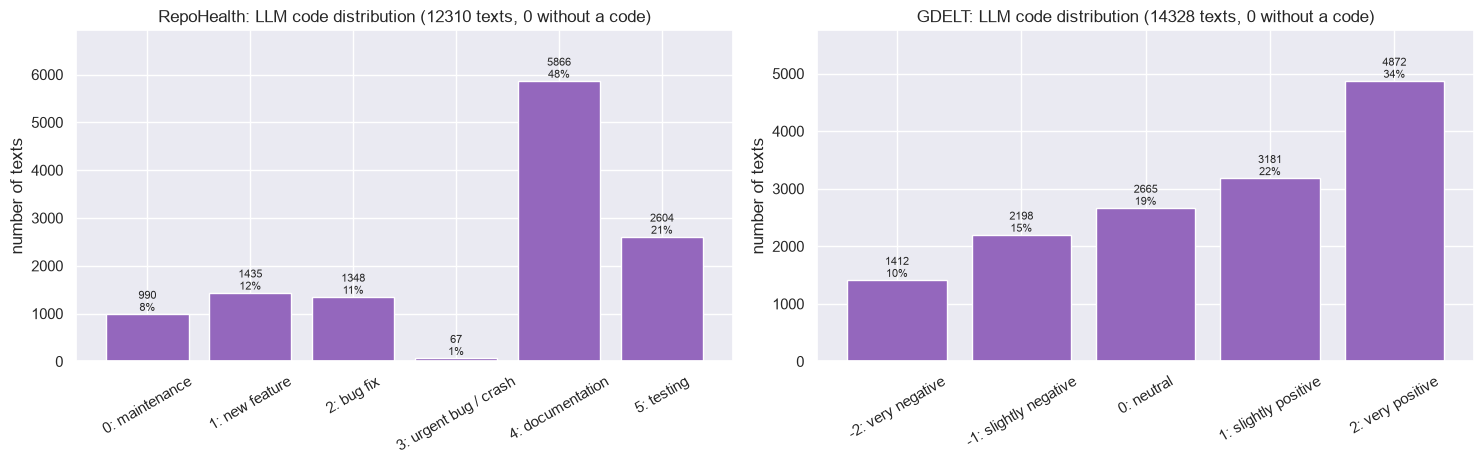


RepoHealth: manual check sample (20 texts)


,entity_id,date_time,code,meaning,text,looks right? (y/n)
0,RepoHealth/huggingface_transformers,2019-12-14 00:00:00+00:00,4,documentation,The discussions highlight several technical is...,NaN
1,RepoHealth/kubernetes_kubernetes,2019-04-05 00:00:00+00:00,5,testing,The comments highlight ongoing challenges with...,NaN
2,RepoHealth/pytorch_pytorch,2017-06-07 00:00:00+00:00,1,new feature,The discussions primarily focus on ensuring ba...,NaN
3,RepoHealth/kubernetes_kubernetes,2020-08-25 00:00:00+00:00,5,testing,The comments reflect various issues concerning...,NaN
4,RepoHealth/pytorch_pytorch,2022-12-17 00:00:00+00:00,5,testing,The discussions raise concerns about the accur...,NaN
5,RepoHealth/facebook_react,2021-02-19 00:00:00+00:00,4,documentation,The discussions highlight concerns about React...,NaN
6,RepoHealth/kubernetes_kubernetes,2016-10-06 00:00:00+00:00,4,documentation,The comments highlight several ongoing challen...,NaN
7,RepoHealth/pytorch_pytorch,2024-06-05 00:00:00+00:00,2,bug fix,The discussions primarily address configuratio...,NaN
8,RepoHealth/huggingface_transformers,2023-08-28 00:00:00+00:00,0,general maintenance,The discussions mainly revolve around challeng...,NaN
9,RepoHealth/huggingface_transformers,2020-08-18 00:00:00+00:00,1,new feature,The comments highlight several key technical c...,NaN



GDELT: manual check sample (20 texts)


,entity_id,date_time,code,meaning,text,looks right? (y/n)
0,GDELT/GBR_AGR,2023-05-16 13:45:00+00:00,2,very positive,"Kaleb Cooper, a farmer featured on Clarkson’s ...",NaN
1,GDELT/USA_LAB,2024-02-05 22:45:00+00:00,2,very positive,"President Biden met with union workers, includ...",NaN
2,GDELT/AUS_AGR,2023-12-03 03:30:00+00:00,1,slightly positive,Australian farmers are seeking mental health s...,NaN
3,GDELT/USA_LAB,2022-04-13 16:30:00+00:00,2,very positive,The article discusses Maryland's enactment of ...,NaN
4,GDELT/AUS_LAB,2024-05-12 23:15:00+00:00,1,slightly positive,Unions Tasmania secretary Jessica Munday empha...,NaN
5,GDELT/USA_LAB,2022-07-29 04:30:00+00:00,0,neutral,The article discusses the federal government's...,NaN
6,GDELT/USA_LAB,2023-11-29 18:45:00+00:00,2,very positive,"A California semiconductor company, Akash Syst...",NaN
7,GDELT/USA_AGR,2022-03-14 16:15:00+00:00,2,very positive,The article highlights that U.S. agricultural ...,NaN
8,GDELT/USA_LAB,2024-10-15 18:15:00+00:00,-2,very negative,The article details a wrongful death lawsuit a...,NaN
9,GDELT/USA_AGR,2024-09-23 21:00:00+00:00,2,very positive,The article highlights the 39th annual Farm Ai...,NaN


In [42]:
LLM_NAMES = {"RepoHealth": {0: "maintenance", 1: "new feature", 2: "bug fix", 3: "urgent bug / crash", 4: "documentation", 5: "testing"},
             "GDELT": {-2: "very negative", -1: "slightly negative", 0: "neutral", 1: "slightly positive", 2: "very positive"}}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, ds in zip(axes, ["RepoHealth", "GDELT"]):
    f = CLEAN / f"{ds}_llm_features.csv"
    if not f.exists():
        ax.set_title(f"{ds}: {f} not found (run llm_extract.py)")
        ax.axis("off")
        continue
    codes = pd.read_csv(f)["llm_code"]
    names = LLM_NAMES[ds]
    counts = codes.value_counts().reindex(list(names)).fillna(0).astype(int)
    labels = [f"{k}: {v}" for k, v in names.items()]
    bars = ax.bar(labels, counts.values, color="tab:purple")
    for b, v in zip(bars, counts.values):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v}\n{100 * v / len(codes):.0f}%", ha="center", va="bottom", fontsize=8)
    ax.set_title(f"{ds}: LLM code distribution ({len(codes)} texts, {int(codes.isna().sum())} without a code)")
    ax.set_ylabel("number of texts")
    ax.tick_params(axis="x", rotation=30)
    ax.set_ylim(0, counts.max() * 1.18)
fig.tight_layout()
plt.show()

for ds in ["RepoHealth", "GDELT"]:
    t = read_res(f"label_check_{ds}.csv", quiet=True)
    if t is not None:
        print(f"\n{ds}: manual check sample ({len(t)} texts)")
        display(t.head(10))

**What the LLM said** (charts above). Every text received a readable code.

* **RepoHealth:** 48% of the texts were labelled "documentation" (5,866 of 12,310), 21% "testing", 12% "new feature", 11% "bug fix", 8% "maintenance" and 1% "urgent bug / crash". Almost half in one class looks too high.
* **GDELT:** 56% of the texts were called positive and 25% negative, while the real `AvgTone` target is negative on average (mean -1.16, section 3.2): the codes lean positive.
* **Manual check:** `label_check.py` draws 20 random texts per dataset for a manual check (table above). I have not filled in the `looks right? (y/n)` column, so the quality of the codes is **not verified**; the only evidence of bias is the distribution above.
* **Result:** the LLM codes did not help (section 14.2): none of the eight "+ LLM vs numeric only" tests is significant (p_fdr 0.49 to 0.87) and the gains are between -1.17% and +0.32%. On the locked test the LLM column is within 0.4% of numeric only, except RepoHealth LightGBM (6.0% worse).


### 14.4 How far can the p-values be trusted? And the summary picture
`dm_calibration.py` runs the same DM test on simulated errors where the truth is known. If two equally good forecasts are "significantly different" in 5% of runs, the test is calibrated; here it rejects **more** often than 5% at long horizons and when entities share events,
so many "significant" results can be false alarms, and gains must always be read next to the p-values.

**Official position of this report.** DM p-values are **not** used as evidence on their own. A text gain counts only if it is also larger than 1% (`rel_gain_pct`), with `entities_better` shown next to it. So the 12 significant GDELT H1 tests, whose gains are all below 1%, are read as *no practical effect*. A block-bootstrap version of the test was not run (future work, section 16).


,table,h,entities,shared share,n per entity,delta,reject rate,mean gain %
0,size,1,1,0.0,800,0.00,0.045,NaN
1,size,1,8,0.0,800,0.00,0.040,NaN
2,size,1,8,0.5,800,0.00,0.200,NaN
3,size,31,1,0.0,800,0.00,0.080,NaN
4,size,31,8,0.0,800,0.00,0.065,NaN
5,size,31,8,0.5,800,0.00,0.255,NaN
6,size,115,1,0.0,800,0.00,0.170,NaN
7,size,115,8,0.0,800,0.00,0.085,NaN
8,size,115,8,0.5,800,0.00,0.305,NaN
9,power,31,1,0.0,500,0.00,0.060,-0.318


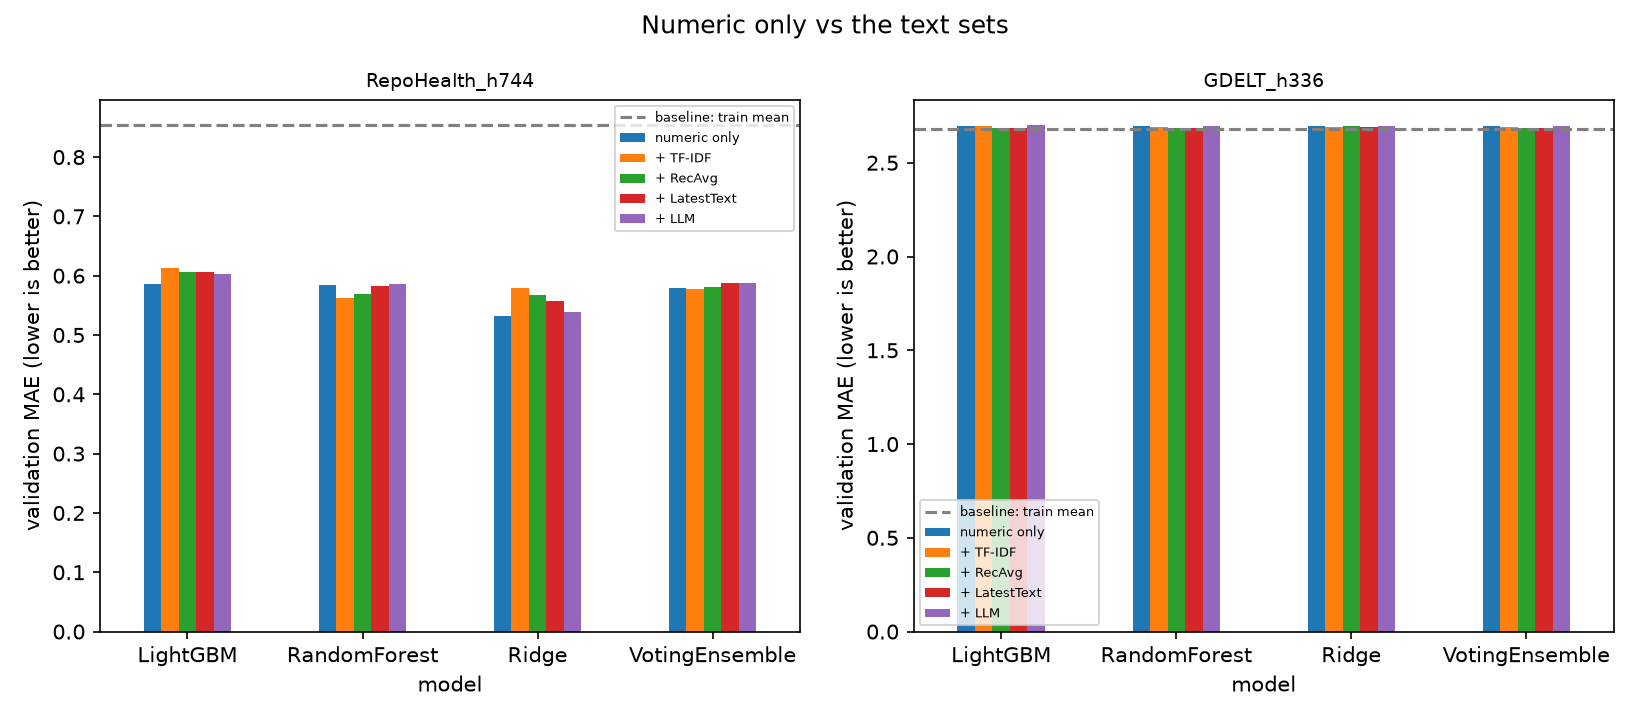

In [44]:
cal = read_res("dm_calibration.csv")
if cal is not None:
    display(cal.round(3))
if (RES / "fig_killer_plot.png").exists():
    display(Image(str(RES / "fig_killer_plot.png")))
else:
    print("[missing] results/fig_killer_plot.png")

### 14.5 What I found
1. **Text gives no reliable gain over a strong numeric model.** RepoHealth (31-day horizon), locked test: the best numeric-only model (LightGBM, 0.5677) beats every text model (best: VotingEnsemble + RecAvg, 0.5733, 1.0% worse). In cross-validation the gain of the best text model is small and not significant (p_fdr 0.77, 14.2). The two significant H1 gains (Ridge + LatestText +5.8%, RandomForest + RecAvg +3.8%) are for models that were worse than the best numeric model to begin with. GDELT (14-day horizon): RecAvg or TF-IDF improve the MAE by 0.5-0.8%, below the 1% I call negligible.
2. **The many "significant" GDELT tests mean little.** 12 of 16 H1 tests have p_fdr < 0.05, but every gain is under 1%, and my simulation (14.4) shows the test rejects too often at this horizon (30.5% of runs for two equally good forecasts at h = 115). By the rule in 14.4 these p-values are not used as evidence.
3. **LLM codes did not help** (14.2, 14.3): none of the eight tests is significant (p_fdr 0.49 to 0.87), and the codes look biased (GDELT leans positive while its target is negative on average), so this is partly a label-quality result.
4. **Extra hypotheses H3-H6 and the exploratory checks** are in Appendix A. None of them changes the answer.


## 15. The final test

*Note: the tables below come from a run with `EVALUATE_TEST = True` (the test part was opened for that run). In this saved notebook the switch is `False`, so a fresh run would print the LOCKED message instead of these tables.*



RepoHealth  TEST (trained on train + validation)


,MAE,MSE,RMSE,R2
VotingEnsemble,0.3787,0.2379,0.4824,0.7470
RandomForest,0.3855,0.2538,0.4974,0.7295
LightGBM,0.3870,0.2467,0.4897,0.7443
ElasticNet,0.4037,0.2764,0.5158,0.7178
Lasso,0.4053,0.2800,0.5193,0.7133
Ridge,0.4056,0.2778,0.5165,0.7194
LinearRegression,0.4066,0.2790,0.5176,0.7181
DecisionTree,0.4887,0.4112,0.6262,0.5341
GradientBoosting,0.5473,0.4661,0.6650,0.3945
baseline: last value,0.5866,0.6198,0.7759,0.3360



EPA-Air  TEST (trained on train + validation)


,MAE,MSE,RMSE,R2
LinearRegression,0.1967,0.0715,0.2592,0.5806
Ridge,0.1968,0.0715,0.2592,0.5805
LightGBM,0.1993,0.0742,0.2636,0.5644
VotingEnsemble,0.1994,0.0739,0.2630,0.5658
RandomForest,0.2017,0.0750,0.2649,0.5586
ElasticNet,0.2020,0.0744,0.2633,0.5651
Lasso,0.2023,0.0745,0.2633,0.5644
GradientBoosting,0.2097,0.0793,0.2739,0.5307
DecisionTree,0.2155,0.0841,0.2820,0.5038
baseline: last value,0.2244,0.0935,0.2934,0.4504



GDELT  TEST (trained on train + validation)


,MAE,MSE,RMSE,R2
LightGBM,2.7953,13.5610,3.6745,0.0202
VotingEnsemble,2.7957,13.5317,3.6709,0.0237
GradientBoosting,2.8011,13.5569,3.6749,0.0217
Ridge,2.8018,13.5414,3.6722,0.0220
LinearRegression,2.8018,13.5430,3.6723,0.0221
RandomForest,2.8026,13.5448,3.6731,0.0237
ElasticNet,2.8028,13.5389,3.6719,0.0219
Lasso,2.8036,13.5434,3.6726,0.0215
DecisionTree,2.8059,13.6723,3.6896,0.0158
baseline: train mean,2.8539,13.9633,3.7292,0.0000


... (4 outputs left out)


GDELT_h336  TEST, text experiment (MAE)


set,numeric only,+ TF-IDF,+ RecAvg,+ LatestText,+ LLM
model,,,,,
LightGBM,2.8439,2.8452,2.8296,2.8327,2.8447
RandomForest,2.8579,2.8565,2.8437,2.8457,2.8577
Ridge,2.8439,2.8393,2.8377,2.8353,2.8420
VotingEnsemble,2.8488,2.8489,2.8337,2.8370,2.8490



RepoHealth_h744  TEST, text experiment (MAE)


set,numeric only,+ TF-IDF,+ RecAvg,+ LatestText,+ LLM
model,,,,,
LightGBM,0.5677,0.5736,0.5840,0.5738,0.6019
RandomForest,0.5972,0.5978,0.5900,0.6018,0.5979
Ridge,0.5950,0.5993,0.5945,0.5831,0.5969
VotingEnsemble,0.5749,0.5787,0.5733,0.5778,0.5742


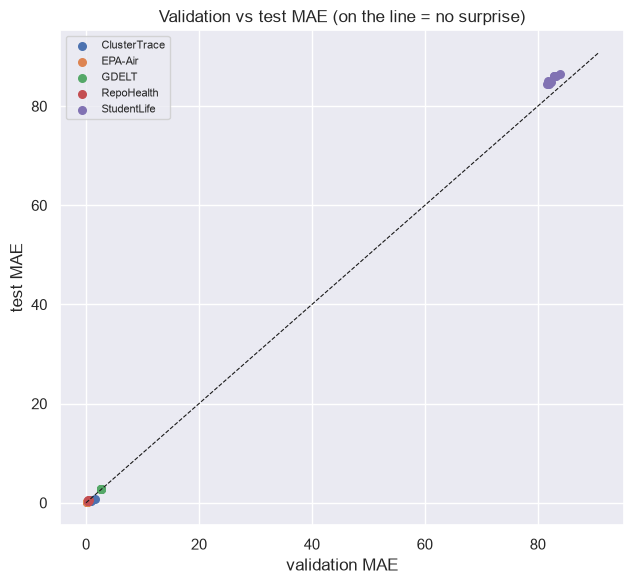

In [55]:
test_tables = {}
if not EVALUATE_TEST:
    print("The test part is LOCKED (EVALUATE_TEST = False in section 1): the test tables are not shown.")
else:
    for ds in ALL_DS:
        t = read_res(f"{ds}_test.csv", quiet=True, index_col=0)
        if t is not None:
            test_tables[ds] = t.sort_values("MAE")
            print(f"\n{ds}  TEST (trained on train + validation)")
            display(test_tables[ds].round(4))
    for f in sorted(RES.glob("*_text_test.csv")):
        print("\n" + f.name.replace("_text_test.csv", "") + "  TEST, text experiment (MAE)")
        display(pivot_sets(pd.read_csv(f)).round(4))
    if not test_tables:
        print("No *_test.csv files found yet: run the scripts with EVALUATE_TEST = True first.")



    rows = []
    for ds, t in test_tables.items():
        if ds in val_tables:
            for m in t.index:
                if m in val_tables[ds].index and not m.startswith("baseline"):
                    rows.append(dict(dataset=ds, model=m, validation=val_tables[ds].loc[m, "MAE"], test=t.loc[m, "MAE"]))
    if rows:
        gap = pd.DataFrame(rows)
        fig, ax = plt.subplots(figsize=(6.5, 6))
        for ds, g in gap.groupby("dataset"):
            ax.scatter(g["validation"], g["test"], label=ds, s=30)
        lim = [0, max(gap["validation"].max(), gap["test"].max()) * 1.05]
        ax.plot(lim, lim, "k--", lw=0.8)
        ax.set_xlabel("validation MAE")
        ax.set_ylabel("test MAE")
        ax.set_title("Validation vs test MAE (on the line = no surprise)")
        ax.legend(fontsize=8)
        fig.tight_layout()
        plt.show()

### 16. Conclusions
Answers to the four questions of the template, plus the research question. Numbers are from the locked test part (section 15) unless said otherwise.

**1. Which model is best on the test set?**

| Dataset | Best model (test MAE) | Best baseline (test MAE) | Gain over best baseline |
|---|---|---|---|
| RepoHealth | VotingEnsemble 0.379 | last value 0.587 | 35% |
| EPA-Air | LinearRegression 0.197 (Ridge 0.197) | last value 0.224 | 12% |
| GDELT | LightGBM 2.795 | train mean 2.854 | 2.1% |
| ClusterTrace | none (best: Lasso 0.333) | last value 0.324 | -2.6% (last value wins) |
| StudentLife | GradientBoosting 84.5 | train mean 103.9 | 19% |

The models are close to each other, so the dataset matters more than the model: on RepoHealth the three tree models are within 2.2% and the linear ones about 7% worse (GradientBoosting is the exception, 0.547 on test against 0.419 on validation); on EPA-Air a plain linear model is as good as anything; on GDELT and StudentLife the differences are too small to prefer a model. The size of the gains moves between periods: EPA-Air beats "last value" by 1.6% on validation but 12% on test.

**2. Do the train-validation results agree with cross-validation?**
Partly: both pick the same best model for GDELT, ClusterTrace and StudentLife, but not for RepoHealth and EPA-Air. Where the order differs the models are within 1-5% of each other, less than the fold-to-fold spread, so the order is mostly noise (rank agreement: section 11).

**3. Which features matter?**
The target's own history (section 10). Without the latest value RepoHealth keeps a 20% advantage over "last value", while on EPA-Air the error rises by 26-33% (section 13).

**4. What would I try next?**
Better text labels (a re-prompted or larger LLM for RepoHealth), a stronger numeric baseline check on ClusterTrace with more machines, a block-bootstrap version of the DM test, a `lag_1 - mean_20` (mean-reversion) feature for tree models, and the IMM-TSF deep-learning baseline for comparison with the paper.

**Research question.** Does text help, and does it depend on the cause of irregularity?
*Does text help?* Not reliably. On the locked test the best RepoHealth model uses no text (LightGBM 0.568; the best text model, 0.573, is 1.0% worse). On GDELT the best text model is 0.5% better (2.830 vs 2.844), too small to matter. The LLM codes added nothing. The few clear gains from text are for numeric models that were weak to begin with, and on ClusterTrace every model is still worse than "repeat the last value".
*Does it depend on the cause?* I cannot say. The H3 test (Appendix A) has very low power with 5 datasets and about 8 folds each. The DM tests and the locked text test cover only RepoHealth and GDELT, both trigger-based; the artifact-based (EPA-Air) and constraint-based datasets (ClusterTrace, StudentLife) only have validation and cross-validation results, where text sets are within about 1% of numeric only (EPA-Air RecAvg is 1.6-2.2% worse for the tree models).

**Compared with the literature.** Zhang et al. (arXiv 2506.21611) find that gains from text are more likely with weaker numeric models, enough training data and text that adds a signal the numbers lack, and that strong unimodal baselines often still win; this fits my results. The Time-IMM paper (arXiv 2506.10412) reports a 6.71% average MSE reduction for its best multimodal setups (up to 38.38% where the text is informative); my effects are much smaller. I did not test why (I use classical models and MAE, and my texts are already five-sentence summaries). Its claim that ClusterTrace gains a lot from text is not reproduced: there the text only helped the weakest numeric models.

**What the answer covers.** The honest answer is *"text did not help with these texts and this coverage"*: the texts are already summaries, 61% (GDELT) to 85% (EPA-Air) of the gaps between numeric observations contain no new text, and the LLM labels are not verified and look biased (GDELT leans positive while its target is negative on average). This does not show that text cannot help with fuller or better texts.

### Limitations
**Main limitations (they limit the answer itself)**
* **Power.** Few entities per dataset (RepoHealth 4, EPA-Air 8, GDELT 8, ClusterTrace 1 machine of 3 after cleaning, StudentLife 20) and only 8 walk-forward folds; entities of one dataset share events, so tests treat them as more independent than they are. H3 has the least power.
* **Text quality and coverage.** Summaries instead of full documents, many gaps without new text, noisy LLM labels (GDELT leans positive, RepoHealth has 48% "documentation"; the manual check of the codes was not completed, 14.3).
* **DM p-values.** The test rejects too often at long horizons (14.4), so I rely on the size of the gain, not on the p-value alone.

**Other limitations**
* The DM tests, `+ LLM` runs and the locked text test exist only for RepoHealth and GDELT (the only runs in `text_features.py`); the other text tables come from earlier runs.
* Many exploratory analyses are **not** corrected for as one family: target sweep (30 comparisons), two-stage residual model (24), error strata (129 cells), H5 follow-up (15 tests), direction signal check (8 runs) and lag ablation (16 combinations). No formal count of the `predict_delta` and L1-objective variants was kept (section 5), and those settings were chosen while looking at validation results; the test part was opened once.
* ClusterTrace: `machine_cpu` has one machine and about 2,500 rows, so it is thin evidence.
* The Time-IMM paper uses deep models; this is a classical re-implementation of the idea, so numbers are not directly comparable.


## Appendix A. Extra hypotheses H3–H6 and other exploratory checks
These analyses are exploratory and are not corrected for as one family (see the limitations in section 16).
`extra_hypotheses.py` tests the rest of the plan. These were written down before the results (pre-planned, not post-hoc). Benjamini-Hochberg correction inside each hypothesis. Rows with `p_fdr < 0.05` are highlighted in green.

| H | Question | Test |
|---|---|---|
| H3 | Does the gain from text differ between datasets / irregularity types (trigger: RepoHealth, GDELT; constraint: ClusterTrace, StudentLife; artifact: EPA-Air; the labels of the Time-IMM paper)? | Kruskal-Wallis, pairwise Mann-Whitney with Holm |
| H4 | Do inter-arrival times differ across datasets? | Kruskal-Wallis on gaps |
| H5 | Does more text volume come *before* higher volatility? | Spearman and Granger, combined with Fisher |
| H6 | Are the residuals of the numeric model uncorrelated? | Ljung-Box on the lags beyond the horizon |

In [47]:
for name in ("residual_summary.csv",):
    t = read_res(name)
    if t is not None:
        print(f"\n{name} (two-stage vs numeric only; exploratory):")
        display(t.round(4))


residual_summary.csv (two-stage vs numeric only; exploratory):


,Dataset,Target,Numeric model,Text,Stage 2,Numeric MAE,Two-stage MAE,Gain %,DM p-value,entities_better,residual_R2,VAL Numeric MAE,VAL Two-stage MAE,FDR p-value,VAL Gain %
0,RepoHealth,new_issues,LightGBM,RecAvg,Ridge,0.5525,0.5699,-3.1476,0.0126,1/4,-0.0655,0.6004,0.5957,0.0506,0.7790
1,RepoHealth,new_issues,LightGBM,RecAvg,LightGBM,0.5525,0.5845,-5.7907,0.0010,0/4,-0.0944,0.6004,0.5870,0.0248,2.2322
2,RepoHealth,new_issues,LightGBM,RecAvg,Gated,0.5525,0.5526,-0.0107,0.9613,3/4,-0.0014,0.6004,0.5985,0.9613,0.3186
3,RepoHealth,new_issues,LightGBM,TF-IDF,Ridge,0.5525,0.5643,-2.1295,0.1201,1/4,-0.0367,0.6004,0.5932,0.2130,1.1900
4,RepoHealth,new_issues,LightGBM,TF-IDF,LightGBM,0.5525,0.5660,-2.4340,0.1242,0/4,-0.0274,0.6004,0.5858,0.2130,2.4269
5,RepoHealth,new_issues,LightGBM,TF-IDF,Gated,0.5525,0.5512,0.2374,0.2459,2/4,0.0033,0.6004,0.6002,0.3834,0.0286
6,RepoHealth,new_issues,Ridge,RecAvg,Ridge,0.5101,0.5481,-7.4432,0.0034,1/4,-0.1271,0.5328,0.5318,0.0405,0.1828
7,RepoHealth,new_issues,Ridge,RecAvg,LightGBM,0.5101,0.5348,-4.8314,0.0493,1/4,-0.0960,0.5328,0.5480,0.1183,-2.8522
8,RepoHealth,new_issues,Ridge,RecAvg,Gated,0.5101,0.5119,-0.3484,0.1036,1/4,-0.0073,0.5328,0.5328,0.2072,-0.0068
9,RepoHealth,new_issues,Ridge,TF-IDF,Ridge,0.5101,0.5305,-3.9839,0.0608,1/4,-0.0552,0.5328,0.5313,0.1327,0.2804



===== H3: 6 tests, 0 with p_fdr < 0.05 =====


hypothesis,scope,detail,statistic,p_value,p_fdr
H3,+ TF-IDF by dataset,"median fold gain %: {'ClusterTrace': 1.55, 'RepoHealth': -1.03, 'EPA-Air': -0.73, 'GDELT': 0.66, 'StudentLife': 0.48}",2.148,0.7086,0.8453
H3,+ TF-IDF by type,"types: ['artifact', 'constraint', 'trigger']",0.336,0.8453,0.8453
H3,+ RecAvg by dataset,"median fold gain %: {'ClusterTrace': 2.16, 'RepoHealth': 0.65, 'EPA-Air': -0.92, 'GDELT': 0.68, 'StudentLife': -0.57}",5.235,0.2640,0.5280
H3,+ RecAvg by type,"types: ['artifact', 'constraint', 'trigger']",3.770,0.1519,0.4888
H3,+ LatestText by dataset,"median fold gain %: {'ClusterTrace': -2.51, 'RepoHealth': 3.25, 'EPA-Air': 0.28, 'GDELT': 0.58, 'StudentLife': -0.13}",4.233,0.3754,0.5631
H3,+ LatestText by type,"types: ['artifact', 'constraint', 'trigger']",3.629,0.1629,0.4888



===== H4: 2 tests, 2 with p_fdr < 0.05 =====


hypothesis,scope,detail,statistic,p_value,p_fdr
H4,gaps between numeric observations,epsilon^2 = 0.829,18649.631,0.0000,0.0000
H4,gaps between texts,epsilon^2 = 0.564,9543.011,0.0000,0.0000



===== H5: 10 tests, 5 with p_fdr < 0.05 =====


hypothesis,scope,detail,statistic,p_value,p_fdr
H5,ClusterTrace Spearman,"median rho 0.447, 1 entities",,0.0000,0.0000
H5,ClusterTrace Granger,1 entities,,0.0124,0.0247
H5,RepoHealth Spearman,"median rho -0.007, 4 entities",,0.6271,0.8959
H5,RepoHealth Granger,4 entities,,0.0100,0.0247
H5,EPA-Air Spearman,"median rho 0.001, 7 entities",,0.8044,0.9318
H5,EPA-Air Granger,7 entities,,0.9965,0.9965
H5,GDELT Spearman,"median rho -0.076, 8 entities",,0.0003,0.0014
H5,GDELT Granger,8 entities,,0.8386,0.9318
H5,StudentLife Spearman,"median rho -0.044, 20 entities",,0.0040,0.0134
H5,StudentLife Granger,20 entities,,0.1302,0.2171



===== H6: 20 tests, 16 with p_fdr < 0.05 =====


hypothesis,scope,detail,statistic,p_value,p_fdr
H6,ClusterTrace / Ridge,"1 entities, h = 38",,0.0000,0.0000
H6,ClusterTrace / RandomForest,"1 entities, h = 38",,0.0000,0.0000
H6,ClusterTrace / LightGBM,"1 entities, h = 38",,0.0000,0.0000
H6,ClusterTrace / VotingEnsemble,"1 entities, h = 38",,0.0000,0.0000
H6,RepoHealth / Ridge,"4 entities, h = 31",,0.0000,0.0000
H6,RepoHealth / RandomForest,"4 entities, h = 31",,0.0000,0.0000
H6,RepoHealth / LightGBM,"4 entities, h = 31",,0.0000,0.0000
H6,RepoHealth / VotingEnsemble,"4 entities, h = 31",,0.0000,0.0000
H6,EPA-Air / Ridge,"8 entities, h = 21",,0.0000,0.0000
H6,EPA-Air / RandomForest,"8 entities, h = 21",,0.0000,0.0000


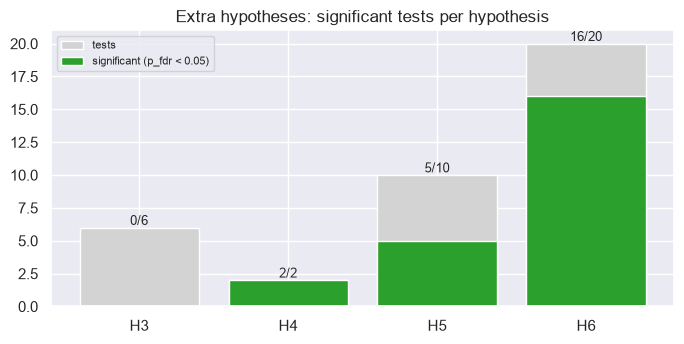

In [3]:
eh = read_res("extra_hypotheses.csv")
if eh is not None:
    def green_if_significant(row):
        sig = pd.notna(row.get("p_fdr")) and row["p_fdr"] < 0.05
        return ["background-color: #b8d6be" if sig else "" for _ in row]

    for hyp, g in eh.groupby("hypothesis"):
        print(f"\n===== {hyp}: {len(g)} tests, {int((g['p_fdr'] < 0.05).sum())} with p_fdr < 0.05 =====")
        g = g.reset_index(drop=True)
        try:
            display(g.style.apply(green_if_significant, axis=1)
                     .format({"statistic": "{:.3f}", "p_value": "{:.4f}", "p_fdr": "{:.4f}"}, na_rep="")
                     .hide(axis="index"))
        except Exception:
            display(g.round(4))



    cnt = eh.groupby("hypothesis").agg(tests=("p_value", "size"), significant=("p_fdr", lambda s: int((s < 0.05).sum())))
    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.bar(cnt.index, cnt["tests"], color="lightgray", label="tests")
    ax.bar(cnt.index, cnt["significant"], color="tab:green", label="significant (p_fdr < 0.05)")
    for i, (t_, s_) in enumerate(zip(cnt["tests"], cnt["significant"])):
        ax.text(i, t_, f"{s_}/{t_}", ha="center", va="bottom", fontsize=9)
    ax.set_title("Extra hypotheses: significant tests per hypothesis")
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

**H3.** The cell below reads the H3 rows of `extra_hypotheses.csv` and writes the summary from them, so the text always matches the table above.

In [49]:
if eh is not None:
    h3 = eh[eh["hypothesis"] == "H3"]
    by_type = h3[h3["scope"].str.contains("by type")]
    by_ds = h3[h3["scope"].str.contains("by dataset")]
    if by_type.empty:
        print("no by-type H3 rows found")
    elif not by_type["detail"].str.contains("constraint").all():
        print("This CSV was made BEFORE ClusterTrace and StudentLife were added to irregularity_type "
              "(constraint-based).\nRun extra_hypotheses.py again, then rerun this cell.")
    else:
        print(f"H3 by dataset ({len(by_ds)} tests): p_fdr {by_ds['p_fdr'].min():.3f} to {by_ds['p_fdr'].max():.3f}")
        print(f"H3 by type trigger / constraint / artifact ({len(by_type)} tests): "
              f"p_fdr {by_type['p_fdr'].min():.3f} to {by_type['p_fdr'].max():.3f}")
        display(h3[["scope", "detail", "statistic", "p_value", "p_fdr"]].round(4).reset_index(drop=True))


H3 by dataset (3 tests): p_fdr 0.528 to 0.845
H3 by type trigger / constraint / artifact (3 tests): p_fdr 0.489 to 0.845


,scope,detail,statistic,p_value,p_fdr
0,+ TF-IDF by dataset,"median fold gain %: {'ClusterTrace': 1.55, 'Re...",2.1476,0.7086,0.8453
1,+ TF-IDF by type,"types: ['artifact', 'constraint', 'trigger']",0.3361,0.8453,0.8453
2,+ RecAvg by dataset,"median fold gain %: {'ClusterTrace': 2.16, 'Re...",5.2354,0.2640,0.5280
3,+ RecAvg by type,"types: ['artifact', 'constraint', 'trigger']",3.7697,0.1519,0.4888
4,+ LatestText by dataset,"median fold gain %: {'ClusterTrace': -2.51, 'R...",4.2329,0.3754,0.5631
5,+ LatestText by type,"types: ['artifact', 'constraint', 'trigger']",3.6288,0.1629,0.4888


In [50]:
for name, what in [("h5_followup.csv", "H5 follow-up: is the volume -> volatility link just observation density?"),
                   ("text_signal_check.csv", "does the text carry direction information on its own / next to the numbers?"),
                   ("error_analysis.csv", "where does text help or hurt (strata of rows)?"),
                   ("sweep_summary.csv", "target sweep: for which numeric columns does text help?")]:
    t = read_res(name)
    if t is not None:
        print(f"\n=== {name}: {what}  ({len(t)} rows, showing up to 40)")
        display(t.head(40).round(4))


=== h5_followup.csv: H5 follow-up: is the volume -> volatility link just observation density?  (15 rows, showing up to 40)


,dataset,bins,entities,median rho (raw),median rho (density removed),share positive,Fisher p (circular shift)
0,ClusterTrace,100,1,0.4358,0.1437,1.0000,0.1608
1,ClusterTrace,200,1,0.4472,0.1057,1.0000,0.1219
2,ClusterTrace,400,1,0.2071,0.0414,1.0000,0.3377
3,RepoHealth,100,4,-0.1089,-0.0960,0.0000,0.3175
4,RepoHealth,200,4,-0.0068,-0.0152,0.5000,0.5990
5,RepoHealth,400,4,-0.0252,-0.0127,0.5000,0.6298
6,EPA-Air,100,7,0.0381,0.0182,0.5714,0.7579
7,EPA-Air,200,7,0.0009,-0.0084,0.4286,0.8404
8,EPA-Air,400,7,-0.0091,-0.0087,0.4286,0.1479
9,GDELT,100,8,-0.1397,-0.0552,0.1250,0.2086



=== text_signal_check.csv: does the text carry direction information on its own / next to the numbers?  (8 rows, showing up to 40)


,dataset,target,n rows,share up,AUC numeric,AUC text only (RecAvg),p (RecAvg text only),AUC numeric+text (RecAvg),AUC change (RecAvg),p (RecAvg AUC change),AUC text only (TF-IDF),p (TF-IDF text only),AUC numeric+text (TF-IDF),AUC change (TF-IDF),p (TF-IDF AUC change)
0,RepoHealth,new_issues,3832,0.4598,0.9102,0.4977,0.9010,0.9044,-0.0058,0.8218,0.5036,0.7624,0.9025,-0.0077,0.4554
1,RepoHealth,merged_prs,3136,0.4493,0.8945,0.4810,0.9307,0.8814,-0.0131,0.9604,0.4916,0.8218,0.8946,0.0001,0.1188
2,RepoHealth,issue_comment_volume,3945,0.4603,0.9163,0.5035,0.5545,0.9204,0.0042,0.0693,0.4976,0.7228,0.9175,0.0012,0.1683
3,ClusterTrace,machine_cpu,1471,0.5942,0.6219,0.5786,0.0396,0.6818,0.0599,0.0297,0.4854,0.3366,0.5769,-0.0449,0.8713
4,ClusterTrace,n_job,5390,0.5328,0.8227,0.5729,0.0297,0.8159,-0.0068,0.5743,0.5429,0.0495,0.8228,0.0002,0.1782
5,EPA-Air,pm2_5,2877,0.4918,0.7853,0.4934,0.4455,0.7776,-0.0077,0.0198,0.4586,0.9802,0.7718,-0.0135,0.0297
6,GDELT,AvgTone,22645,0.4885,0.8230,0.5189,0.0099,0.8251,0.0021,0.2673,0.5130,0.0099,0.8260,0.0030,0.0396
7,StudentLife,sleep_duration,14255,0.4958,0.8071,0.5196,0.0099,0.8018,-0.0053,0.7822,0.5063,0.1188,0.8102,0.0031,0.1980



=== error_analysis.csv: where does text help or hurt (strata of rows)?  (129 rows, showing up to 40)


,run,model,text set,stratum,group,n,numeric MAE,text MAE,gain %,CI low,CI high,CI excludes 0
0,ClusterTrace_h12,VotingEnsemble,+ TF-IDF,gap before origin,mid,440,6.4481,6.4244,0.3675,-13.9691,12.9252,False
1,ClusterTrace_h12,VotingEnsemble,+ TF-IDF,gap before origin,low,441,5.9672,5.6167,5.8731,-6.6928,15.8472,False
2,ClusterTrace_h12,VotingEnsemble,+ TF-IDF,gap before origin,high,428,6.2879,6.3343,-0.7381,-4.4480,2.6965,False
3,ClusterTrace_h12,VotingEnsemble,+ TF-IDF,lead time,mid,436,5.2916,5.2884,0.0600,-11.2568,12.9623,False
4,ClusterTrace_h12,VotingEnsemble,+ TF-IDF,lead time,high,436,6.9963,6.8561,2.0043,-3.5031,10.2249,False
5,ClusterTrace_h12,VotingEnsemble,+ TF-IDF,lead time,low,437,6.4127,6.2238,2.9471,-8.5837,11.8212,False
6,ClusterTrace_h12,VotingEnsemble,+ TF-IDF,text recency,recent,510,6.0193,6.0603,-0.6812,-5.4950,6.7284,False
7,ClusterTrace_h12,VotingEnsemble,+ TF-IDF,text recency,old,412,6.2255,5.7910,6.9788,-3.4994,15.9141,False
8,ClusterTrace_h12,VotingEnsemble,+ TF-IDF,text recency,mid,387,6.5249,6.5585,-0.5138,-10.9229,8.5988,False
9,ClusterTrace_h12,VotingEnsemble,+ TF-IDF,target size (outcome!),typical,1309,6.2337,6.1228,1.7784,-5.0473,8.2299,False



=== sweep_summary.csv: target sweep: for which numeric columns does text help?  (30 rows, showing up to 40)


,Dataset,Target,Model,Numeric MAE,TF-IDF MAE,RecAvg MAE,RecAvg Gain %,DM p-value (RecAvg vs Numeric),FDR-corrected p-value,Mode
0,RepoHealth,new_issues,Ridge,0.5101,0.5083,0.5079,0.4376,0.7294,0.8772,level
1,RepoHealth,new_issues,RandomForest,0.5163,0.5214,0.5076,1.6844,0.2921,0.7969,level
2,RepoHealth,new_issues,LightGBM,0.5525,0.5466,0.5504,0.3907,0.6827,0.8772,level
3,RepoHealth,merged_prs,Ridge,0.6896,0.6748,0.6859,0.5300,0.3187,0.7969,level
4,RepoHealth,merged_prs,RandomForest,0.6378,0.6410,0.6350,0.4378,0.7365,0.8772,level
5,RepoHealth,merged_prs,LightGBM,0.6261,0.6190,0.6180,1.2908,0.6818,0.8772,level
6,RepoHealth,issue_comment_volume,Ridge,0.5527,0.5640,0.5593,-1.1978,0.1389,0.5209,level
7,RepoHealth,issue_comment_volume,RandomForest,0.5129,0.5175,0.5196,-1.3063,0.7603,0.8772,level
8,RepoHealth,issue_comment_volume,LightGBM,0.5631,0.5156,0.5445,3.3137,0.0766,0.5209,level
9,ClusterTrace,n_job,Ridge,0.2891,0.3148,0.2910,-0.6739,0.8494,0.9100,level


**Findings of the extra analyses (Appendix A).** 

1. **H3 (does the gain depend on the dataset or on the cause of irregularity?):** see the H3 table and the one-line summary under it above. The by-type test now has three groups, trigger (RepoHealth, GDELT), constraint (ClusterTrace, StudentLife) and artifact (EPA-Air); these are the labels of the Time-IMM paper. With 5 datasets and about 8 folds each the power is low, so a non-significant result would not mean "no difference".
2. **H4 (do the gaps differ between datasets?): yes, strongly.** epsilon² = 0.83 for the gaps between numeric observations and 0.56 for the gaps between texts, which matches section 3.3.
3. **H5 (more text now, more volatility later): not supported.** The only positive link is ClusterTrace (rho 0.45, one machine). When the number of numeric observations per bin is taken out it drops to 0.11 (100 bins: 0.44 to 0.14; 400 bins: 0.21 to 0.04) and is no longer significant (circular-shift p = 0.12-0.34, tables above). GDELT and StudentLife have significant but *negative* and tiny correlations (-0.08, -0.04), the opposite of the hypothesis. One StudentLife follow-up test (100 bins, p = 0.0098) is one of 15 and does not repeat at 200 or 400 bins (p = 0.21, 0.42).
4. **H6 (residuals uncorrelated beyond the horizon): rejected for four of five datasets.** For ClusterTrace, RepoHealth, EPA-Air and StudentLife all models leave structure in their errors (p_fdr < 0.0001). For GDELT (no signal) they do not (p_fdr 0.25-0.32). So the numeric models could still be improved.
5. **Exploratory checks, same picture.** *Target sweep* (30 text-vs-numeric comparisons): 3 reach p_fdr < 0.05, all in delta mode: RepoHealth `merged_prs` with LightGBM (+4.8%), ClusterTrace `n_job` with LightGBM (+4.8%) and RepoHealth `issue_comment_volume` with Ridge (3.9% *worse*). *Two-stage residual model* (24 combinations): in 22 the error in cross-validation is higher with text. *Signal check* (can text predict the direction of the next change?): text alone is close to a coin flip (AUC 0.46-0.58), and adding it to the numbers changes the AUC between -0.04 and +0.06.